In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#### Load the Dataset

In [2]:
df = pd.read_csv("data/Atlantic_France.csv")
df.head()

,date,position,song,artist,popularity,duration_ms,album_type,total_tracks,is_explicit,album_cover_url
0,18-05-2024,1,LA RUE,No Limit & Gazo & Damso,72,225137,single,1,True,https://i.scdn.co/image/ab67616d0000b27384f245...
1,18-05-2024,2,C'est carré le S,Naps,74,201533,album,22,False,https://i.scdn.co/image/ab67616d0000b27348f7c1...
2,18-05-2024,3,Freestyle LVL UP 1,Ninho,76,114182,single,1,True,https://i.scdn.co/image/ab67616d0000b273fbe613...
3,18-05-2024,4,Bolide allemand,SDM,79,176746,album,15,True,https://i.scdn.co/image/ab67616d0000b273455e89...
4,18-05-2024,5,Freestyle LVL UP 2,Ninho,71,149064,single,1,True,https://i.scdn.co/image/ab67616d0000b27351f1cb...


In [3]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 27800
Columns: 10


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 27800 entries, 0 to 27799
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   date             27800 non-null  str  
 1   position         27800 non-null  int64
 2   song             27799 non-null  str  
 3   artist           27800 non-null  str  
 4   popularity       27800 non-null  int64
 5   duration_ms      27800 non-null  int64
 6   album_type       27800 non-null  str  
 7   total_tracks     27800 non-null  int64
 8   is_explicit      27800 non-null  bool 
 9   album_cover_url  27800 non-null  str  
dtypes: bool(1), int64(4), str(5)
memory usage: 4.7 MB


In [5]:
df.isnull().sum()

date               0
position           0
song               1
artist             0
popularity         0
duration_ms        0
album_type         0
total_tracks       0
is_explicit        0
album_cover_url    0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(19)

#### Data Cleaning and Validation

In [7]:
df_clean = df.copy()

print("Original shape:", df.shape)
print("Working Dataset Shape:", df_clean.shape)

Original shape: (27800, 10)
Working Dataset Shape: (27800, 10)


In [8]:
print(df_clean.columns.to_list())

['date', 'position', 'song', 'artist', 'popularity', 'duration_ms', 'album_type', 'total_tracks', 'is_explicit', 'album_cover_url']


In [9]:
df_clean.dtypes

date                 str
position           int64
song                 str
artist               str
popularity         int64
duration_ms        int64
album_type           str
total_tracks       int64
is_explicit         bool
album_cover_url      str
dtype: object

In [10]:
df_clean["date"] = pd.to_datetime(df_clean["date"], errors="coerce")

C:\Users\rudra\AppData\Local\Temp\ipykernel_31268\2544305112.py:1: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df_clean["date"] = pd.to_datetime(df_clean["date"], errors="coerce")


In [11]:
df_clean.dtypes

date               datetime64[us]
position                    int64
song                          str
artist                        str
popularity                  int64
duration_ms                 int64
album_type                    str
total_tracks                int64
is_explicit                  bool
album_cover_url               str
dtype: object

In [12]:
missing_values = df_clean.isnull().sum()
print(missing_values)

date               0
position           0
song               1
artist             0
popularity         0
duration_ms        0
album_type         0
total_tracks       0
is_explicit        0
album_cover_url    0
dtype: int64


In [13]:
df_clean[df_clean["song"].isna()].T

,13001
date,2025-02-02 00:00:00
position,2
song,NaN
artist,Lavern
popularity,0
duration_ms,0
album_type,single
total_tracks,5
is_explicit,False
album_cover_url,https://i.scdn.co/image/ab67616d0000b273eb5e3a...


In [14]:
df_clean["song"] = df_clean["song"].fillna("Unknown Song")

In [15]:
duplicate_count = df_clean.duplicated().sum()

print("Duplicated Count:", duplicate_count)

Duplicated Count: 19


In [16]:
df_clean[df_clean.duplicated(keep=False)].sort_values(by=["date", "position"])

,date,position,song,artist,popularity,duration_ms,album_type,total_tracks,is_explicit,album_cover_url
14350,2025-03-01,1,Pyramide,Werenoi,78,208405,album,17,True,https://i.scdn.co/image/ab67616d0000b273cb7db7...
14400,2025-03-01,1,Pyramide,Werenoi,78,208405,album,17,True,https://i.scdn.co/image/ab67616d0000b273cb7db7...
14351,2025-03-01,2,Petit génie,Jungeli & Imen Es & Alonzo,84,217259,single,1,True,https://i.scdn.co/image/ab67616d0000b2737b6ae1...
14401,2025-03-01,2,Petit génie,Jungeli & Imen Es & Alonzo,84,217259,single,1,True,https://i.scdn.co/image/ab67616d0000b2737b6ae1...
14352,2025-03-01,3,Ceux qu'on était,Pierre Garnier,82,174106,single,1,False,https://i.scdn.co/image/ab67616d0000b27398855c...
14402,2025-03-01,3,Ceux qu'on était,Pierre Garnier,82,174106,single,1,False,https://i.scdn.co/image/ab67616d0000b27398855c...
14355,2025-03-01,6,Beautiful Things,Benson Boone,100,180304,single,1,False,https://i.scdn.co/image/ab67616d0000b273f2a919...
14405,2025-03-01,6,Beautiful Things,Benson Boone,100,180304,single,1,False,https://i.scdn.co/image/ab67616d0000b273f2a919...
14356,2025-03-01,7,MAMI WATA,Gazo & Tiakola,79,233240,album,12,True,https://i.scdn.co/image/ab67616d0000b2737dfe25...
14406,2025-03-01,7,MAMI WATA,Gazo & Tiakola,79,233240,album,12,True,https://i.scdn.co/image/ab67616d0000b2737dfe25...


In [17]:
df_clean = df_clean.drop_duplicates()

In [18]:
df_clean.duplicated().sum()

np.int64(0)

In [19]:
df_clean.dtypes

date               datetime64[us]
position                    int64
song                          str
artist                        str
popularity                  int64
duration_ms                 int64
album_type                    str
total_tracks                int64
is_explicit                  bool
album_cover_url               str
dtype: object

In [20]:
numerical_columns = ["position", "popularity", "duration_ms", "total_tracks"]
df_clean[numerical_columns].describe()

,position,popularity,duration_ms,total_tracks
count,27781.000000,27781.000000,27781.00000,27781.000000
mean,25.502718,76.642309,185473.91649,9.001116
std,14.429266,11.571757,32439.85779,8.140697
min,1.000000,0.000000,0.00000,1.000000
25%,13.000000,71.000000,165586.00000,1.000000
50%,26.000000,75.000000,180000.00000,10.000000
75%,38.000000,83.000000,207733.00000,15.000000
max,50.000000,100.000000,547413.00000,119.000000


In [21]:
print(
    df_clean[df_clean["position"] <= 0][
        ["date", "position", "song", "artist"]
    ]
)

Empty DataFrame
Columns: [date, position, song, artist]
Index: []


In [22]:
print(
    "Minimum popularity:",
    df_clean["popularity"].min()
)

print(
    "Maximum popularity:",
    df_clean["popularity"].max()
)

Minimum popularity: 0
Maximum popularity: 100


In [23]:
df_clean[
    (df_clean["popularity"] < 0) |
    (df_clean["popularity"] > 100)
]

,date,position,song,artist,popularity,duration_ms,album_type,total_tracks,is_explicit,album_cover_url


In [24]:
df_clean["duration_min"] = (
    df_clean["duration_ms"] / 60000
)

df_clean[
    ["song", "duration_ms", "duration_min"]
].head()

,song,duration_ms,duration_min
0,LA RUE,225137,3.752283
1,C'est carré le S,201533,3.358883
2,Freestyle LVL UP 1,114182,1.903033
3,Bolide allemand,176746,2.945767
4,Freestyle LVL UP 2,149064,2.484400


In [25]:
print(df_clean["is_explicit"].value_counts(dropna=False))

is_explicit
True     15629
False    12152
Name: count, dtype: int64


In [26]:
print(df_clean["is_explicit"].unique())

[ True False]


In [27]:
print("Album types:")
print(df_clean["album_type"].value_counts(dropna=False))

print("\nExplicit values:")
print(df_clean["is_explicit"].value_counts(dropna=False))

Album types:
album_type
album          14686
single         13086
compilation        9
Name: count, dtype: int64

Explicit values:
is_explicit
True     15629
False    12152
Name: count, dtype: int64


In [28]:
print("Final Shape:", df_clean.shape)

print("\nMissing Values:")
print(df_clean.isnull().sum())

print("\nDuplicate Rows:")
print(df_clean.duplicated().sum())

print("\nData Types:")
print(df_clean.dtypes)

Final Shape: (27781, 11)

Missing Values:
date               0
position           0
song               0
artist             0
popularity         0
duration_ms        0
album_type         0
total_tracks       0
is_explicit        0
album_cover_url    0
duration_min       0
dtype: int64

Duplicate Rows:
0

Data Types:
date               datetime64[us]
position                    int64
song                          str
artist                        str
popularity                  int64
duration_ms                 int64
album_type                    str
total_tracks                int64
is_explicit                  bool
album_cover_url               str
duration_min              float64
dtype: object


In [29]:
df_clean.to_csv("data/France_Top50_Cleaned.csv")

In [30]:
print("Rows:", df_clean.shape[0])
print("Columns:", df_clean.shape[1])

Rows: 27781
Columns: 11


In [31]:
df_clean.head()

,date,position,song,artist,popularity,duration_ms,album_type,total_tracks,is_explicit,album_cover_url,duration_min
0,2024-05-18,1,LA RUE,No Limit & Gazo & Damso,72,225137,single,1,True,https://i.scdn.co/image/ab67616d0000b27384f245...,3.752283
1,2024-05-18,2,C'est carré le S,Naps,74,201533,album,22,False,https://i.scdn.co/image/ab67616d0000b27348f7c1...,3.358883
2,2024-05-18,3,Freestyle LVL UP 1,Ninho,76,114182,single,1,True,https://i.scdn.co/image/ab67616d0000b273fbe613...,1.903033
3,2024-05-18,4,Bolide allemand,SDM,79,176746,album,15,True,https://i.scdn.co/image/ab67616d0000b273455e89...,2.945767
4,2024-05-18,5,Freestyle LVL UP 2,Ninho,71,149064,single,1,True,https://i.scdn.co/image/ab67616d0000b27351f1cb...,2.484400


In [32]:
df_clean.tail()

,date,position,song,artist,popularity,duration_ms,album_type,total_tracks,is_explicit,album_cover_url,duration_min
27795,2025-11-27,46,Mauvais garçon,Helena,63,162706,single,1,False,https://i.scdn.co/image/ab67616d0000b2731ad45d...,2.711767
27796,2025-11-27,47,Laboratoire,Werenoi,71,162840,album,18,True,https://i.scdn.co/image/ab67616d0000b273454178...,2.714000
27797,2025-11-27,48,Coco,Ninho & Niska,66,148656,album,15,True,https://i.scdn.co/image/ab67616d0000b273d30660...,2.477600
27798,2025-11-27,49,Nightcall,Kavinsky & Angèle & Phoenix,74,179306,single,1,False,https://i.scdn.co/image/ab67616d0000b27382e856...,2.988433
27799,2025-11-27,50,Paint The Town Blue (from the series Arcane Le...,Ashnikko & Arcane & League of Legends,76,115533,single,1,False,https://i.scdn.co/image/ab67616d0000b273b6d68c...,1.925550


In [33]:
print("Start Date:", df_clean["date"].min())
print("End Date:", df_clean["date"].max())

Start Date: 2024-05-18 00:00:00
End Date: 2025-11-27 00:00:00


In [34]:
df_clean["date"].nunique()

555

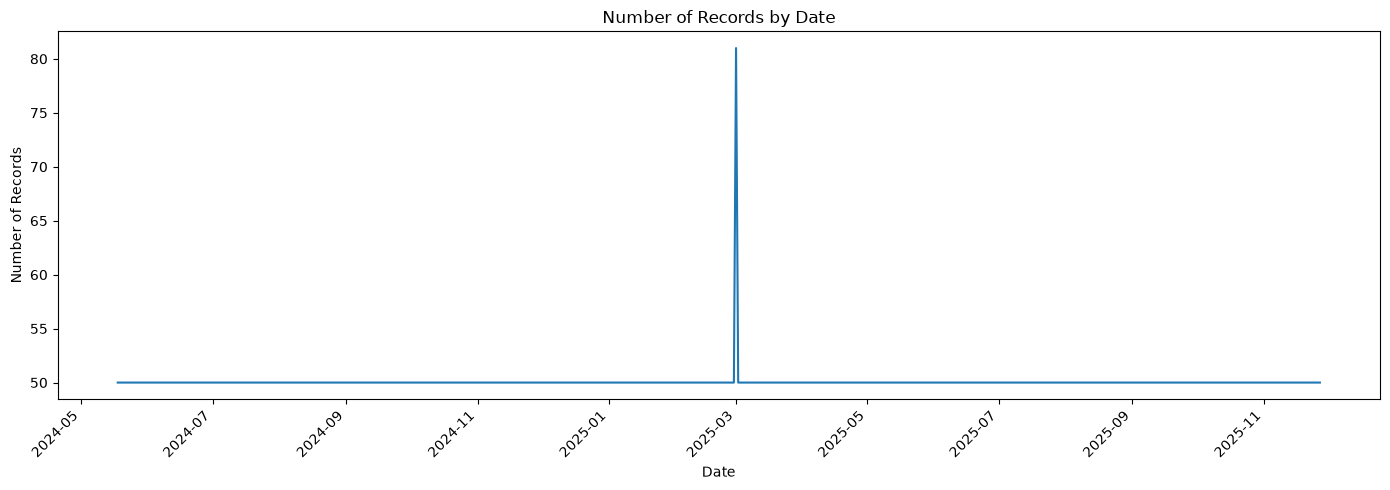

In [35]:
daily_records = df_clean.groupby("date").size()

plt.figure(figsize=(14, 5))
daily_records.plot()
plt.title("Number of Records by Date")
plt.xlabel("Date")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [36]:
position_counts = df_clean["position"].value_counts().sort_index()

position_counts.head(10)

position
1     555
2     555
3     555
4     556
5     556
6     555
7     555
8     555
9     556
10    556
Name: count, dtype: int64

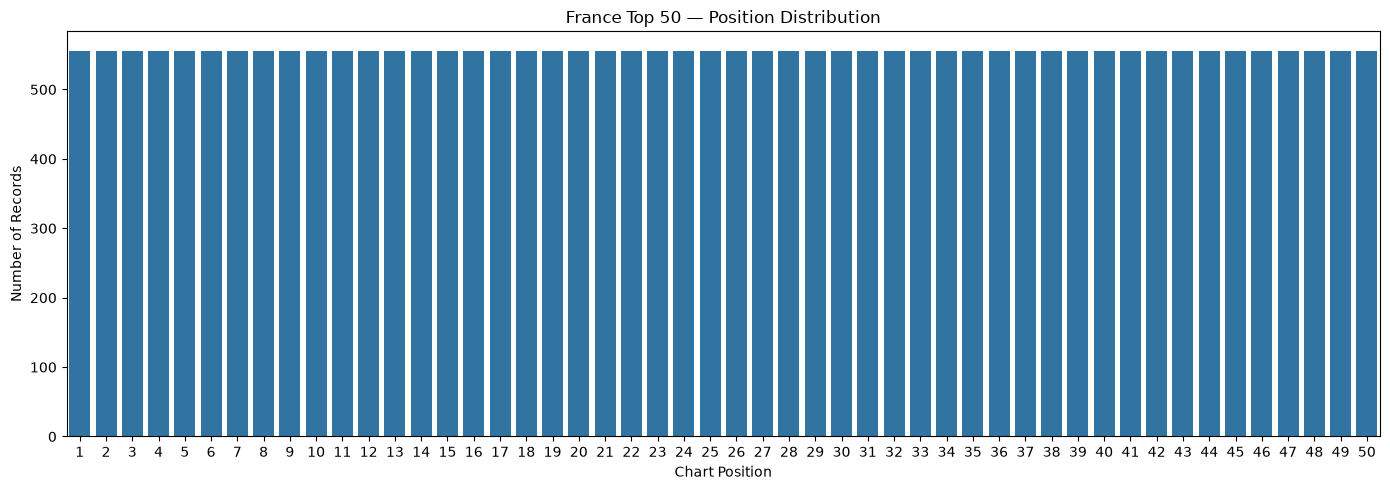

In [37]:
plt.figure(figsize=(14, 5))

sns.barplot(
    x=position_counts.index,
    y=position_counts.values
)

plt.title("France Top 50 — Position Distribution")
plt.xlabel("Chart Position")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

In [38]:
df_clean["popularity"].describe()

count    27781.000000
mean        76.642309
std         11.571757
min          0.000000
25%         71.000000
50%         75.000000
75%         83.000000
max        100.000000
Name: popularity, dtype: float64

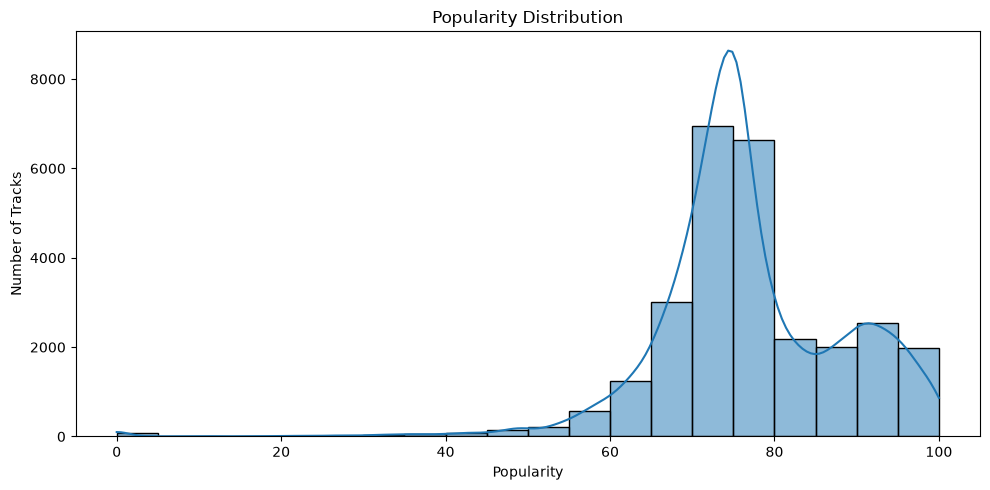

In [39]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df_clean["popularity"],
    bins=20,
    kde=True
)

plt.title("Popularity Distribution")
plt.xlabel("Popularity")
plt.ylabel("Number of Tracks")
plt.tight_layout()
plt.show()

In [40]:
df_clean["duration_min"].describe()

count    27781.000000
mean         3.091232
std          0.540664
min          0.000000
25%          2.759767
50%          3.000000
75%          3.462217
max          9.123550
Name: duration_min, dtype: float64

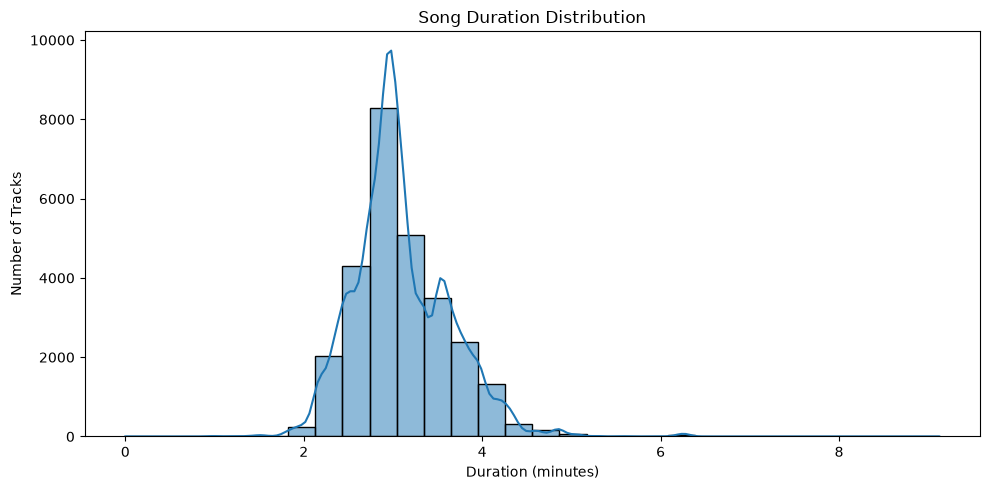

In [41]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df_clean["duration_min"],
    bins=30,
    kde=True
)

plt.title("Song Duration Distribution")
plt.xlabel("Duration (minutes)")
plt.ylabel("Number of Tracks")
plt.tight_layout()
plt.show()

In [42]:
df_clean.nlargest(
    10,
    "duration_min"
)[
    ["song", "artist", "duration_min"]
]

,song,artist,duration_min
194,BIG Brother,Luv Resval,9.123550
23795,Sous le soleil,Jul & 13 Organisé & L'Algérino,8.002667
22653,Bande organisée 2,Jul & 13 Organisé & Alonzo,6.274883
22707,Bande organisée 2,Jul & 13 Organisé & Alonzo,6.274883
22757,Bande organisée 2,Jul & 13 Organisé & Alonzo,6.274883
22810,Bande organisée 2,Jul & 13 Organisé & Alonzo,6.274883
22860,Bande organisée 2,Jul & 13 Organisé & Alonzo,6.274883
22912,Bande organisée 2,Jul & 13 Organisé & Alonzo,6.274883
22964,Bande organisée 2,Jul & 13 Organisé & Alonzo,6.274883
23013,Bande organisée 2,Jul & 13 Organisé & Alonzo,6.274883


In [43]:
explicit_counts = df_clean["is_explicit"].value_counts()

print(explicit_counts)

is_explicit
True     15629
False    12152
Name: count, dtype: int64


In [44]:
explicit_percentage = (
    df_clean["is_explicit"]
    .value_counts(normalize=True)
    * 100
)

print(explicit_percentage)

is_explicit
True     56.257874
False    43.742126
Name: proportion, dtype: float64


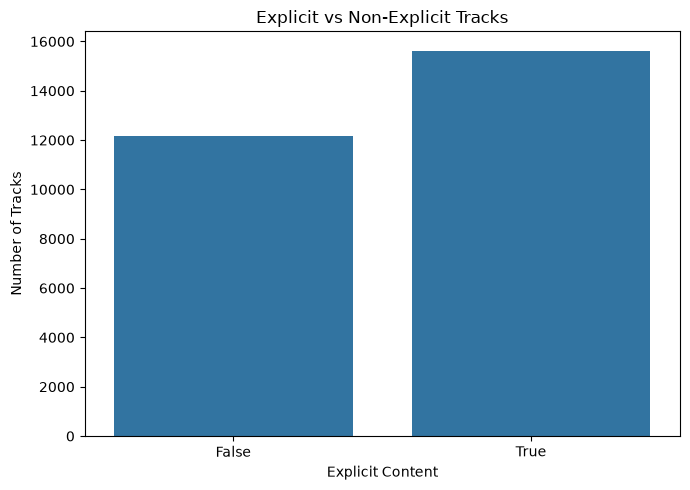

In [45]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_clean,
    x="is_explicit"
)

plt.title("Explicit vs Non-Explicit Tracks")
plt.xlabel("Explicit Content")
plt.ylabel("Number of Tracks")
plt.tight_layout()
plt.show()

In [46]:
album_counts = df_clean["album_type"].value_counts()

print(album_counts)

album_type
album          14686
single         13086
compilation        9
Name: count, dtype: int64


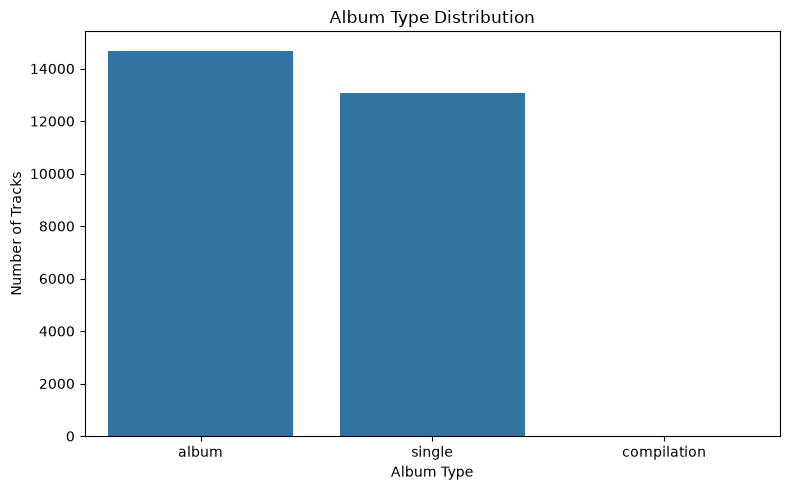

In [47]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="album_type",
    order=df_clean["album_type"].value_counts().index
)

plt.title("Album Type Distribution")
plt.xlabel("Album Type")
plt.ylabel("Number of Tracks")
plt.tight_layout()
plt.show()

In [48]:
top_artists = (
    df_clean["artist"]
    .value_counts()
    .head(15)
)

print(top_artists)

artist
Werenoi                       2201
PLK                            905
SDM                            901
Jul                            711
Ninho                          622
Favé                           597
Tiakola                        594
GIMS                           559
KeBlack                        546
Dua Lipa                       488
Gazo & Tiakola                 482
Heuss L'enfoiré                428
Soolking & Gazo                411
Jungeli & Imen Es & Alonzo     408
Gazo                           365
Name: count, dtype: int64


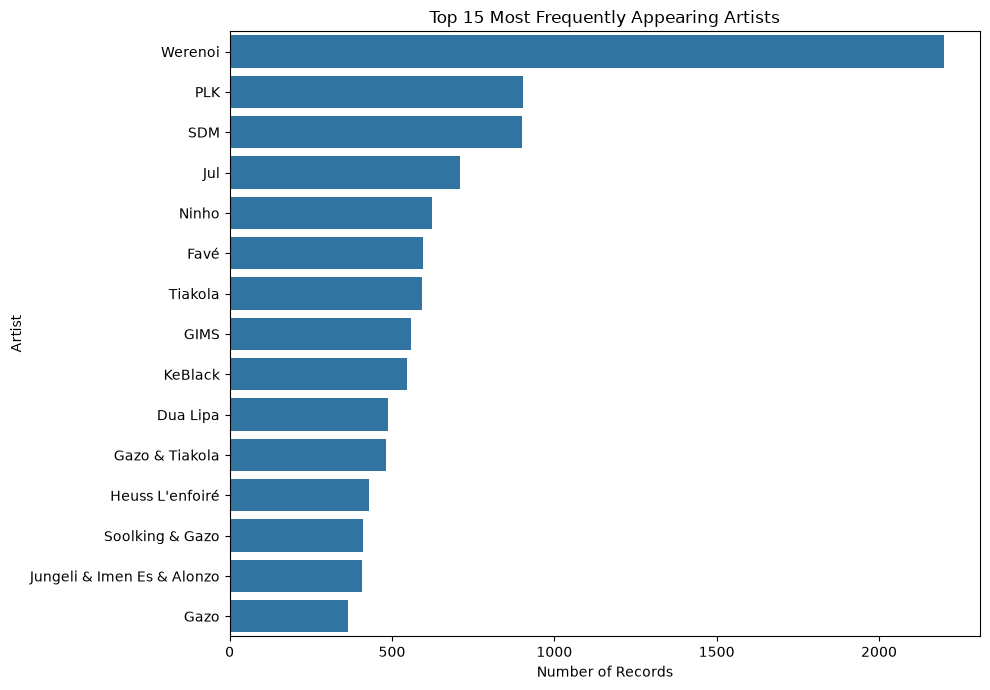

In [49]:
plt.figure(figsize=(10, 7))

sns.barplot(
    x=top_artists.values,
    y=top_artists.index
)

plt.title("Top 15 Most Frequently Appearing Artists")
plt.xlabel("Number of Records")
plt.ylabel("Artist")
plt.tight_layout()
plt.show()

In [50]:
top_songs = (
    df_clean["song"]
    .value_counts()
    .head(15)
)

print(top_songs)

song
Laboratoire         458
Bolide allemand     454
Casanova            411
Petit génie         409
FLASHBACK           396
Saiyan              343
Lose Control        295
La League           287
Si No Estás         287
Beautiful Things    285
Aucune attache      284
Tu connais          283
Solitaire           279
Meuda               261
Tattoo              257
Name: count, dtype: int64


In [51]:
df_clean.groupby("is_explicit")["popularity"].agg(
    ["count", "mean", "median", "min", "max"]
)

,count,mean,median,min,max
is_explicit,,,,,
False,12152,80.901333,81.0,0,100
True,15629,73.330795,74.0,0,100


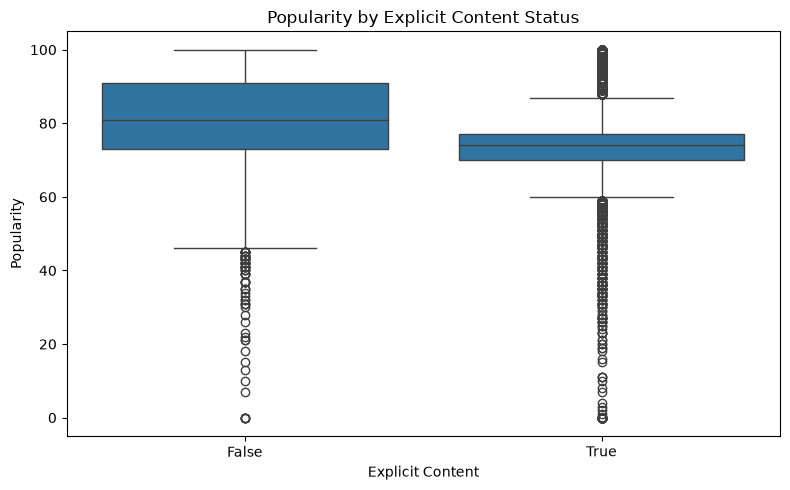

In [52]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="is_explicit",
    y="popularity"
)

plt.title("Popularity by Explicit Content Status")
plt.xlabel("Explicit Content")
plt.ylabel("Popularity")
plt.tight_layout()
plt.show()

In [53]:
df_clean.groupby("is_explicit")["duration_min"].agg(
    ["count", "mean", "median"]
)

,count,mean,median
is_explicit,,,
False,12152,3.042105,3.005067
True,15629,3.129430,2.994217


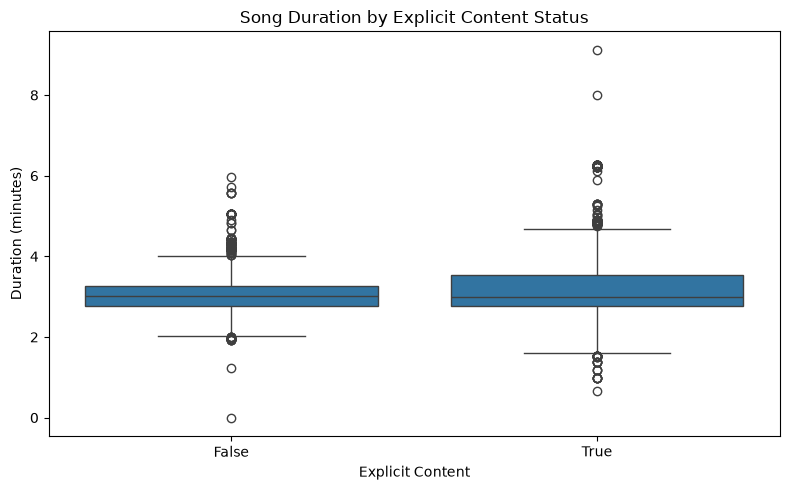

In [54]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="is_explicit",
    y="duration_min"
)

plt.title("Song Duration by Explicit Content Status")
plt.xlabel("Explicit Content")
plt.ylabel("Duration (minutes)")
plt.tight_layout()
plt.show()

In [55]:
numeric_cols = [
    "position",
    "popularity",
    "duration_ms",
    "total_tracks"
]

correlation = df_clean[numeric_cols].corr()

print(correlation)

              position  popularity  duration_ms  total_tracks
position      1.000000   -0.117347     0.017751      0.107018
popularity   -0.117347    1.000000     0.056009     -0.342383
duration_ms   0.017751    0.056009     1.000000      0.118618
total_tracks  0.107018   -0.342383     0.118618      1.000000


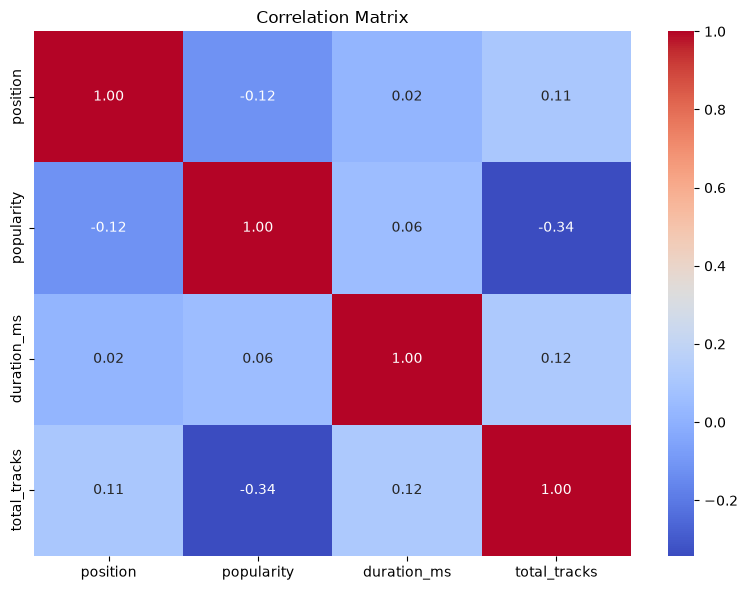

In [56]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

In [57]:
print("========== EDA SUMMARY ==========")

print("\nDataset Shape:")
print(df_clean.shape)

print("\nDate Range:")
print(df_clean["date"].min(), "to", df_clean["date"].max())

print("\nAverage Popularity:")
print(round(df_clean["popularity"].mean(), 2))

print("\nAverage Duration (minutes):")
print(round(df_clean["duration_min"].mean(), 2))

print("\nMost Common Album Type:")
print(df_clean["album_type"].mode()[0])

print("\nMost Common Explicit Status:")
print(df_clean["is_explicit"].mode()[0])

print("\nNumber of Unique Artists:")
print(df_clean["artist"].nunique())

print("\nNumber of Unique Songs:")
print(df_clean["song"].nunique())

========== EDA SUMMARY ==========

Dataset Shape:
(27781, 11)

Date Range:
2024-05-18 00:00:00 to 2025-11-27 00:00:00

Average Popularity:
76.64

Average Duration (minutes):
3.09

Most Common Album Type:
album

Most Common Explicit Status:
True

Number of Unique Artists:
325

Number of Unique Songs:
696


#### Audience Sensitivity Analysis

In [58]:
explicit_summary = (
    df_clean
    .groupby("is_explicit")
    .agg(
        total_tracks=("song", "count"),
        avg_popularity=("popularity", "mean"),
        avg_position=("position", "mean"),
        avg_duration=("duration_min", "mean")
    )
    .reset_index()
)

explicit_summary

,is_explicit,total_tracks,avg_popularity,avg_position,avg_duration
0,False,12152,80.901333,26.157752,3.042105
1,True,15629,73.330795,24.993410,3.129430


In [59]:
explicit_distribution = (
    df_clean["is_explicit"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(explicit_distribution)

is_explicit
True     56.26
False    43.74
Name: proportion, dtype: float64


In [60]:
position_explicit = pd.crosstab(
    df_clean["position"],
    df_clean["is_explicit"],
    normalize="index"
) * 100

position_explicit.head(10)

is_explicit,False,True
position,,
1,41.621622,58.378378
2,44.864865,55.135135
3,28.468468,71.531532
4,32.014388,67.985612
5,35.431655,64.568345
6,36.756757,63.243243
7,37.657658,62.342342
8,44.864865,55.135135
9,39.568345,60.431655


In [61]:
position_explicit_long = (
    position_explicit
    .rename_axis("position")
    .reset_index()
    .melt(
        id_vars="position",
        var_name="Explicit status",
        value_name="Percentage"
    )
)

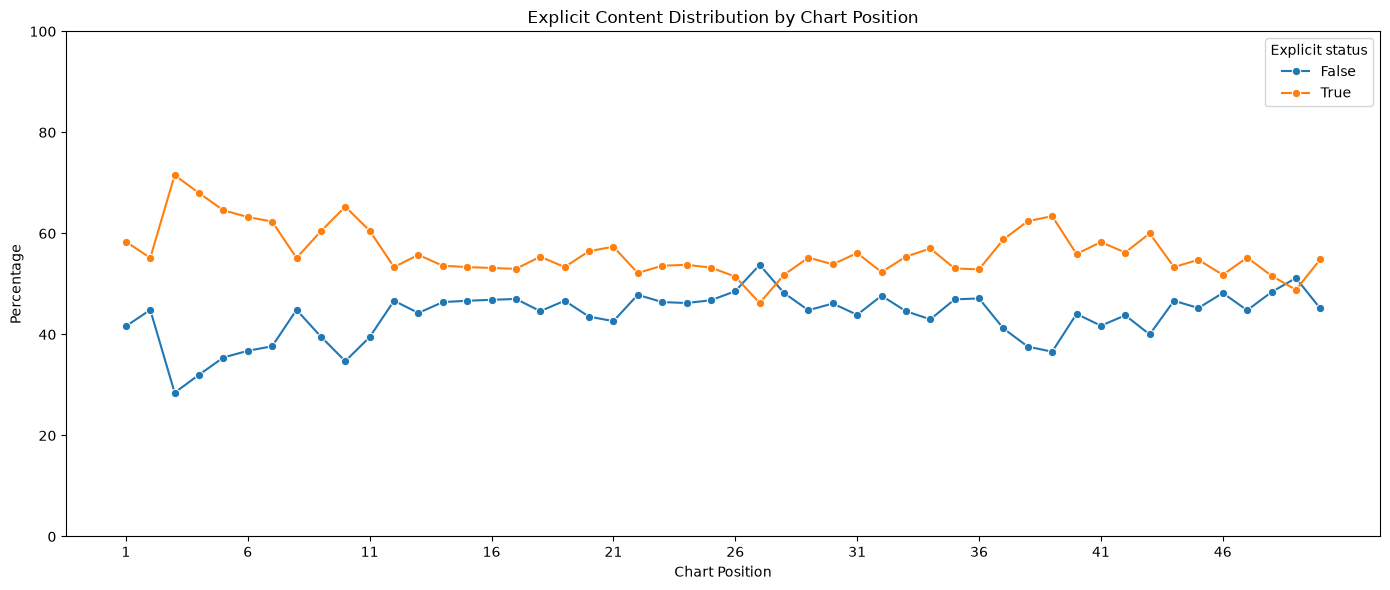

In [62]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=position_explicit_long,
    x="position",
    y="Percentage",
    hue="Explicit status",
    marker="o"
)

plt.title("Explicit Content Distribution by Chart Position")
plt.xlabel("Chart Position")
plt.ylabel("Percentage")
plt.xticks(range(1, 51, 5))
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

#### Analyze Explicit Content by Chart Position

In [63]:
position_explicit_summary = (
    df_clean
    .groupby(["position", "is_explicit"])
    .agg(
        track_count=("song", "count"),
        avg_popularity=("popularity", "mean")
    )
    .reset_index()
)

position_explicit_summary.head(20)

,position,is_explicit,track_count,avg_popularity
0,1,False,231,81.363636
1,1,True,324,76.814815
2,2,False,249,81.240964
3,2,True,306,76.774510
4,3,False,158,84.810127
5,3,True,397,78.586902
6,4,False,178,78.196629
7,4,True,378,74.989418
8,5,False,197,80.954315
9,5,True,359,75.952646


In [64]:
position_explicit_pct = (
    pd.crosstab(
        df_clean["position"],
        df_clean["is_explicit"],
        normalize="index"
    ) * 100
)

position_explicit_pct.round(2)

is_explicit,False,True
position,,
1,41.62,58.38
2,44.86,55.14
3,28.47,71.53
4,32.01,67.99
5,35.43,64.57
6,36.76,63.24
7,37.66,62.34
8,44.86,55.14
9,39.57,60.43


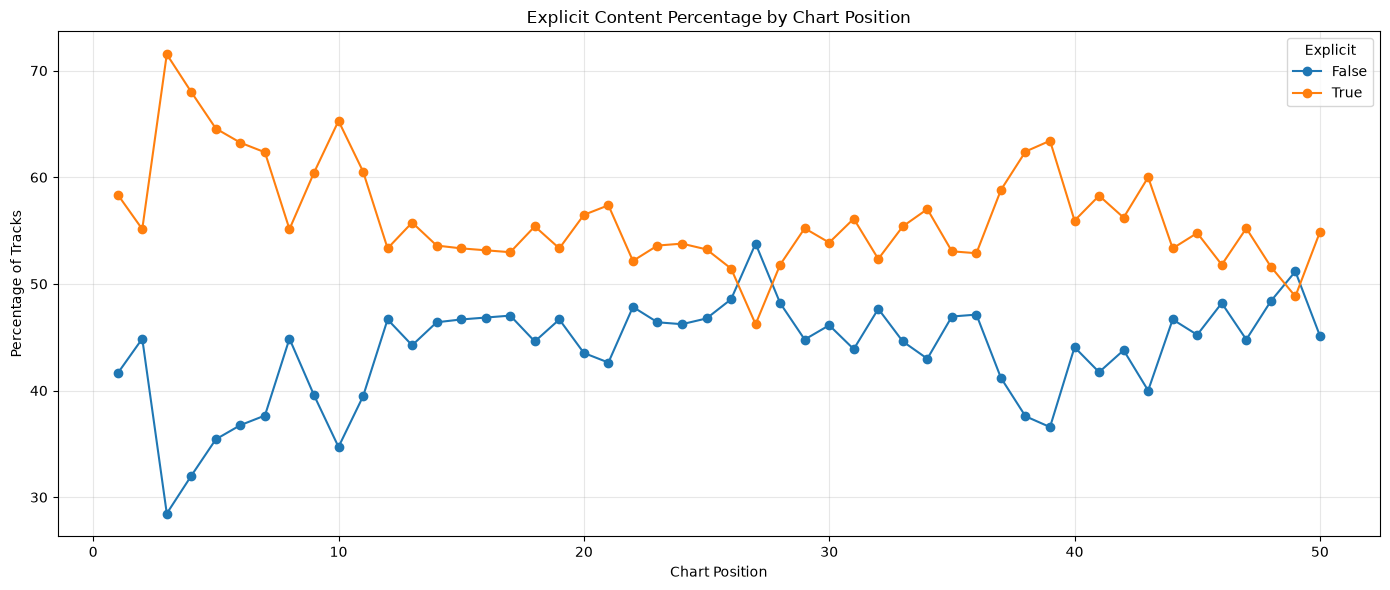

In [65]:
plt.figure(figsize=(14, 6))

for column in position_explicit_pct.columns:
    plt.plot(
        position_explicit_pct.index,
        position_explicit_pct[column],
        marker="o",
        label=str(column)
    )

plt.title("Explicit Content Percentage by Chart Position")
plt.xlabel("Chart Position")
plt.ylabel("Percentage of Tracks")
plt.legend(title="Explicit")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [66]:
df_clean["chart_group"] = np.where(
    df_clean["position"] <= 10,
    "Top 10",
    "Positions 11-50"
)

In [67]:
chart_group_explicit = (
    pd.crosstab(
        df_clean["chart_group"],
        df_clean["is_explicit"],
        normalize="index"
    ) * 100
)

chart_group_explicit.round(2)

is_explicit,False,True
chart_group,,
Positions 11-50,45.28,54.72
Top 10,37.59,62.41


<Figure size 800x500 with 0 Axes>

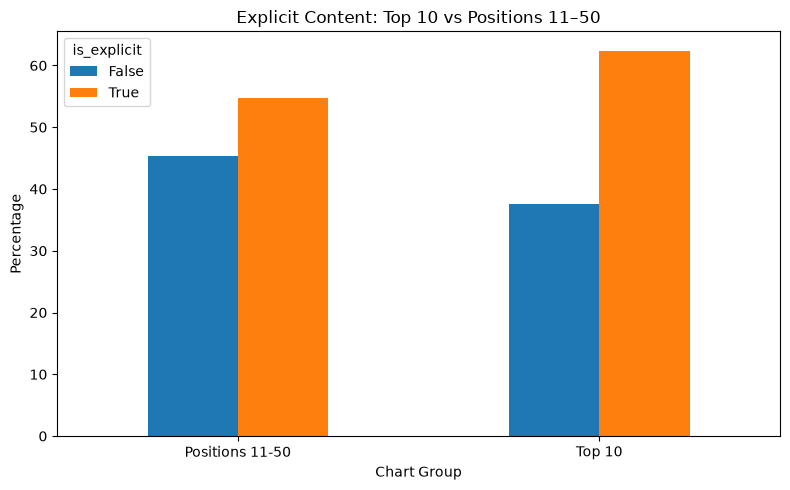

In [68]:
plt.figure(figsize=(8, 5))

chart_group_explicit.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Explicit Content: Top 10 vs Positions 11–50")
plt.xlabel("Chart Group")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [69]:
popularity_by_group = (
    df_clean
    .groupby(["chart_group", "is_explicit"])["popularity"]
    .agg(["count", "mean", "median"])
    .round(2)
)

popularity_by_group

count   mean  median
chart_group     is_explicit                      
Positions 11-50 False        10064  80.71    81.0
                True         12163  72.53    73.0
Top 10          False         2088  81.81    81.0
                True          3466  76.14    77.0

#### Chart Position by Explicit Status

In [70]:
position_explicit = (
    df_clean
    .groupby(["position", "is_explicit"])
    .agg(
        track_count=("song", "count"),
        avg_popularity=("popularity", "mean")
    )
    .reset_index()
)

position_explicit

,position,is_explicit,track_count,avg_popularity
0,1,False,231,81.363636
1,1,True,324,76.814815
2,2,False,249,81.240964
3,2,True,306,76.774510
4,3,False,158,84.810127
...,...,...,...,...
95,48,True,287,72.536585
96,49,False,284,77.957746
97,49,True,271,70.926199
98,50,False,251,77.713147


In [71]:
df_clean["chart_group"] = np.where(
    df_clean["position"] <= 10,
    "Top 10",
    "Positions 11-50"
)

In [72]:
chart_group_explicit = (
    pd.crosstab(
        df_clean["chart_group"],
        df_clean["is_explicit"],
        normalize="index"
    ) * 100
)

chart_group_explicit.round(2)

is_explicit,False,True
chart_group,,
Positions 11-50,45.28,54.72
Top 10,37.59,62.41


In [73]:
print("Chart Position Analysis Completed")
print("=" * 45)
print(chart_group_explicit.round(2))

Chart Position Analysis Completed
is_explicit      False  True 
chart_group                  
Positions 11-50  45.28  54.72
Top 10           37.59  62.41


#### Song Duration by Explicit Status

In [74]:
duration_summary = (
    df_clean
    .groupby("is_explicit")["duration_min"]
    .agg(
        track_count="count",
        average_duration="mean",
        median_duration="median",
        minimum_duration="min",
        maximum_duration="max"
    )
    .round(2)
)

duration_summary

,track_count,average_duration,median_duration,minimum_duration,maximum_duration
is_explicit,,,,,
False,12152,3.04,3.01,0.00,5.96
True,15629,3.13,2.99,0.67,9.12


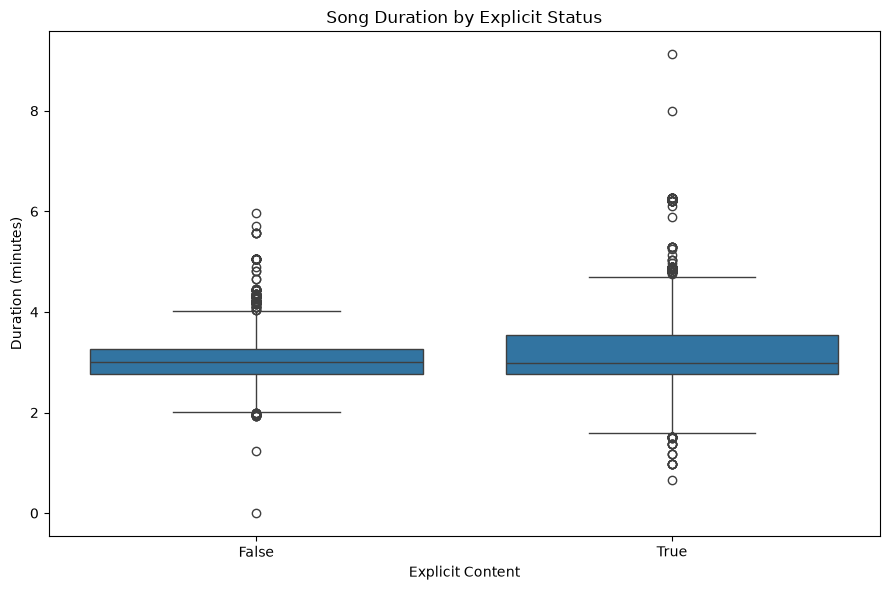

In [75]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df_clean,
    x="is_explicit",
    y="duration_min"
)

plt.title("Song Duration by Explicit Status")
plt.xlabel("Explicit Content")
plt.ylabel("Duration (minutes)")
plt.tight_layout()
plt.show()

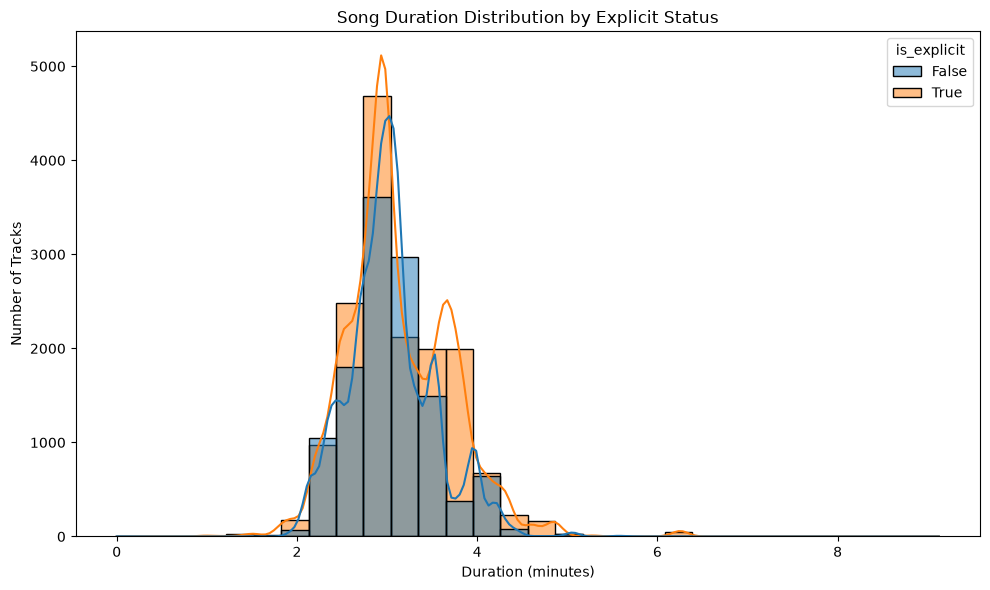

In [76]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_clean,
    x="duration_min",
    hue="is_explicit",
    bins=30,
    kde=True
)

plt.title("Song Duration Distribution by Explicit Status")
plt.xlabel("Duration (minutes)")
plt.ylabel("Number of Tracks")
plt.tight_layout()
plt.show()

In [77]:
longest_tracks = (
    df_clean
    .nlargest(15, "duration_min")
    [["song", "artist", "duration_min", "is_explicit"]]
)

longest_tracks

,song,artist,duration_min,is_explicit
194,BIG Brother,Luv Resval,9.123550,True
23795,Sous le soleil,Jul & 13 Organisé & L'Algérino,8.002667,True
22653,Bande organisée 2,Jul & 13 Organisé & Alonzo,6.274883,True
22707,Bande organisée 2,Jul & 13 Organisé & Alonzo,6.274883,True
22757,Bande organisée 2,Jul & 13 Organisé & Alonzo,6.274883,True
22810,Bande organisée 2,Jul & 13 Organisé & Alonzo,6.274883,True
22860,Bande organisée 2,Jul & 13 Organisé & Alonzo,6.274883,True
22912,Bande organisée 2,Jul & 13 Organisé & Alonzo,6.274883,True
22964,Bande organisée 2,Jul & 13 Organisé & Alonzo,6.274883,True
23013,Bande organisée 2,Jul & 13 Organisé & Alonzo,6.274883,True


In [78]:
df_clean["duration_group"] = pd.cut(
    df_clean["duration_min"],
    bins=[0, 2, 3, 4, 5, float("inf")],
    labels=[
        "Under 2 min",
        "2–3 min",
        "3–4 min",
        "4–5 min",
        "5+ min"
    ],
    right=False
)

In [79]:
duration_group_summary = (
    pd.crosstab(
        df_clean["duration_group"],
        df_clean["is_explicit"],
        normalize="index"
    ) * 100
)

duration_group_summary.round(2)

is_explicit,False,True
duration_group,,
Under 2 min,13.33,86.67
2–3 min,43.74,56.26
3–4 min,46.59,53.41
4–5 min,23.16,76.84
5+ min,34.83,65.17


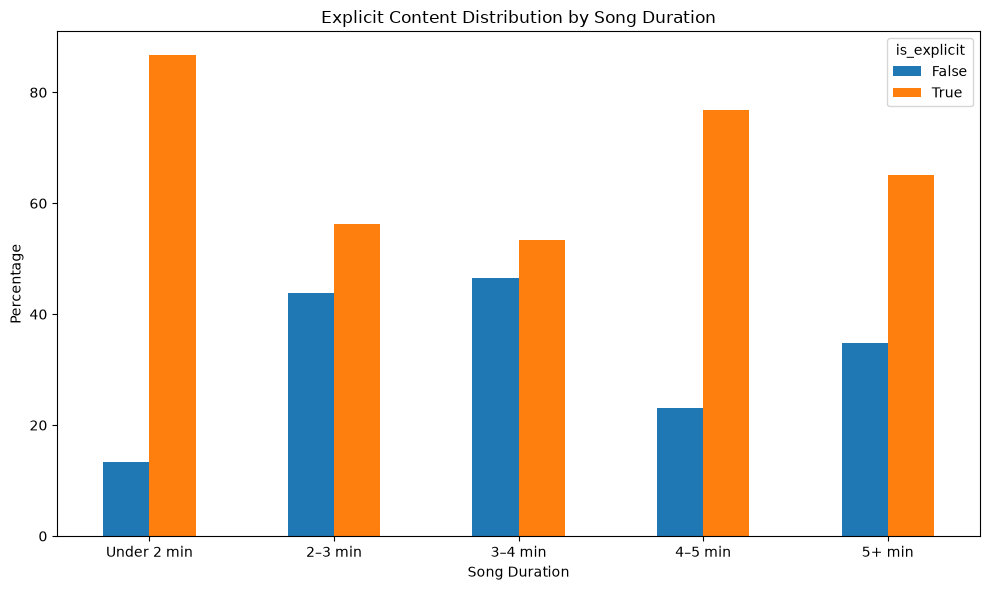

In [80]:
duration_group_summary.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Explicit Content Distribution by Song Duration")
plt.xlabel("Song Duration")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [81]:
duration_summary.to_csv(
    "data/saved/duration_by_explicit_summary.csv"
)

duration_group_summary.to_csv(
    "data/saved/duration_group_by_explicit_summary.csv"
)

#### Album Type by Explicit Status

In [82]:
print("Album Types:")
print(df_clean["album_type"].value_counts(dropna=False))

Album Types:
album_type
album          14686
single         13086
compilation        9
Name: count, dtype: int64


In [83]:
album_explicit_summary = (
    df_clean
    .groupby(["album_type", "is_explicit"])
    .agg(
        track_count=("song", "count"),
        avg_popularity=("popularity", "mean"),
        avg_duration=("duration_min", "mean")
    )
    .reset_index()
)

album_explicit_summary.round(2)

,album_type,is_explicit,track_count,avg_popularity,avg_duration
0,album,False,4051,77.01,3.19
1,album,True,10635,71.45,3.15
2,compilation,False,9,79.33,2.91
3,single,False,8092,82.85,2.97
4,single,True,4994,77.33,3.09


In [84]:
album_explicit_pct = (
    pd.crosstab(
        df_clean["album_type"],
        df_clean["is_explicit"],
        normalize="index"
    ) * 100
)

album_explicit_pct.round(2)

is_explicit,False,True
album_type,,
album,27.58,72.42
compilation,100.00,0.00
single,61.84,38.16


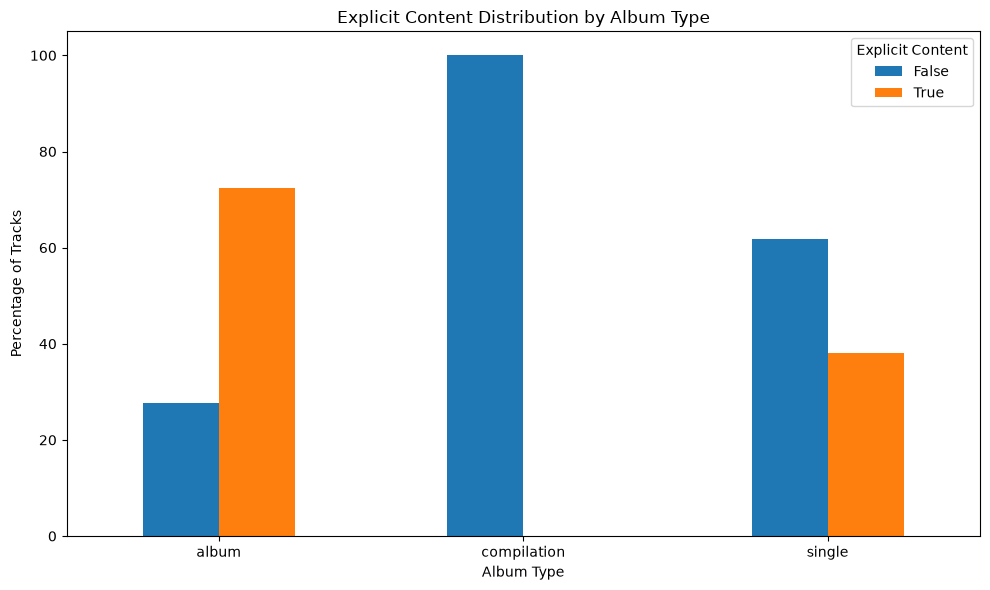

In [85]:
album_explicit_pct.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Explicit Content Distribution by Album Type")
plt.xlabel("Album Type")
plt.ylabel("Percentage of Tracks")
plt.xticks(rotation=0)
plt.legend(title="Explicit Content")
plt.tight_layout()
plt.show()

In [86]:
album_popularity = (
    df_clean
    .groupby(["album_type", "is_explicit"])["popularity"]
    .agg(
        count="count",
        mean="mean",
        median="median"
    )
    .round(2)
)

album_popularity

count   mean  median
album_type  is_explicit                      
album       False         4051  77.01    75.0
            True         10635  71.45    73.0
compilation False            9  79.33    75.0
single      False         8092  82.85    83.0
            True          4994  77.33    76.0

In [87]:
album_duration = (
    df_clean
    .groupby(["album_type", "is_explicit"])["duration_min"]
    .agg(
        count="count",
        mean="mean",
        median="median"
    )
    .round(2)
)

album_duration

count  mean  median
album_type  is_explicit                     
album       False         4051  3.19    3.14
            True         10635  3.15    3.02
compilation False            9  2.91    3.28
single      False         8092  2.97    2.97
            True          4994  3.09    2.99

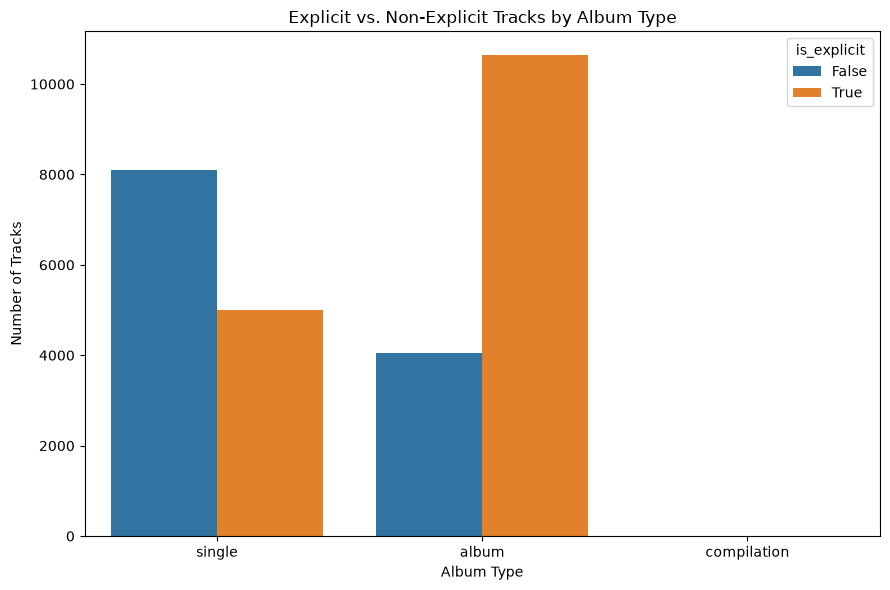

In [88]:
plt.figure(figsize=(9, 6))

sns.countplot(
    data=df_clean,
    x="album_type",
    hue="is_explicit"
)

plt.title("Explicit vs. Non-Explicit Tracks by Album Type")
plt.xlabel("Album Type")
plt.ylabel("Number of Tracks")
plt.tight_layout()
plt.show()

In [89]:
album_explicit_summary.to_csv(
    "data/saved/album_explicit_summary.csv",
    index=False
)

album_explicit_pct.to_csv(
    "data/saved/album_explicit_percentage.csv"
)

album_popularity.to_csv(
    "data/saved/album_explicit_popularity.csv"
)

album_duration.to_csv(
    "data/saved/album_explicit_duration.csv"
)

#### Artist-Level Explicit-Content Patterns

In [90]:
artist_counts = (
    df_clean["artist"]
    .value_counts()
)

artist_counts.head(20)

artist
Werenoi                       2201
PLK                            905
SDM                            901
Jul                            711
Ninho                          622
Favé                           597
Tiakola                        594
GIMS                           559
KeBlack                        546
Dua Lipa                       488
Gazo & Tiakola                 482
Heuss L'enfoiré                428
Soolking & Gazo                411
Jungeli & Imen Es & Alonzo     408
Gazo                           365
Teddy Swims                    340
Loreen                         308
Booba                          308
Benson Boone                   291
Freeze corleone                290
Name: count, dtype: int64

In [91]:
artist_threshold = 10

eligible_artists = artist_counts[
    artist_counts >= artist_threshold
].index

artist_df = df_clean[
    df_clean["artist"].isin(eligible_artists)
].copy()

print("Eligible artists:", artist_df["artist"].nunique())
print("Records:", len(artist_df))

Eligible artists: 203
Records: 27385


In [92]:
artist_explicit_summary = (
    artist_df
    .groupby(["artist", "is_explicit"])
    .agg(
        track_count=("song", "count"),
        avg_popularity=("popularity", "mean"),
        avg_position=("position", "mean"),
        avg_duration=("duration_min", "mean")
    )
    .reset_index()
)

artist_explicit_summary.round(2)

,artist,is_explicit,track_count,avg_popularity,avg_position,avg_duration
0,AMK,True,84,62.68,19.86,3.20
1,Adam Port & Stryv & Keinemusik,False,85,89.85,29.42,2.96
2,Aden Foyer,False,95,76.05,40.68,3.36
3,Amy Winehouse,True,10,83.20,44.60,4.02
4,Andy Williams,False,12,78.33,26.92,2.52
...,...,...,...,...,...,...
215,Zokush,True,108,65.07,29.84,3.01
216,Zola,True,113,65.99,39.07,3.02
217,Zola & Koba LaD,True,213,67.78,20.89,2.61
218,cassö & RAYE & D-Block Europe,True,92,93.52,34.83,2.21


In [93]:
artist_explicit_pct = (
    pd.crosstab(
        artist_df["artist"],
        artist_df["is_explicit"],
        normalize="index"
    ) * 100
)

artist_explicit_pct = artist_explicit_pct.round(2)

artist_explicit_pct.head(20)

is_explicit,False,True
artist,,
AMK,0.00,100.00
Adam Port & Stryv & Keinemusik,100.00,0.00
Aden Foyer,100.00,0.00
Amy Winehouse,0.00,100.00
Andy Williams,100.00,0.00
Ariana Grande,42.19,57.81
Arma Jackson,100.00,0.00
Artemas,100.00,0.00
Aya Nakamura,100.00,0.00


In [94]:
if True in artist_explicit_pct.columns:
    explicit_artist_share = (
        artist_explicit_pct[True]
        .sort_values(ascending=False)
    )

    explicit_artist_share.head(15)

In [95]:
print(df_clean["is_explicit"].unique())

[ True False]


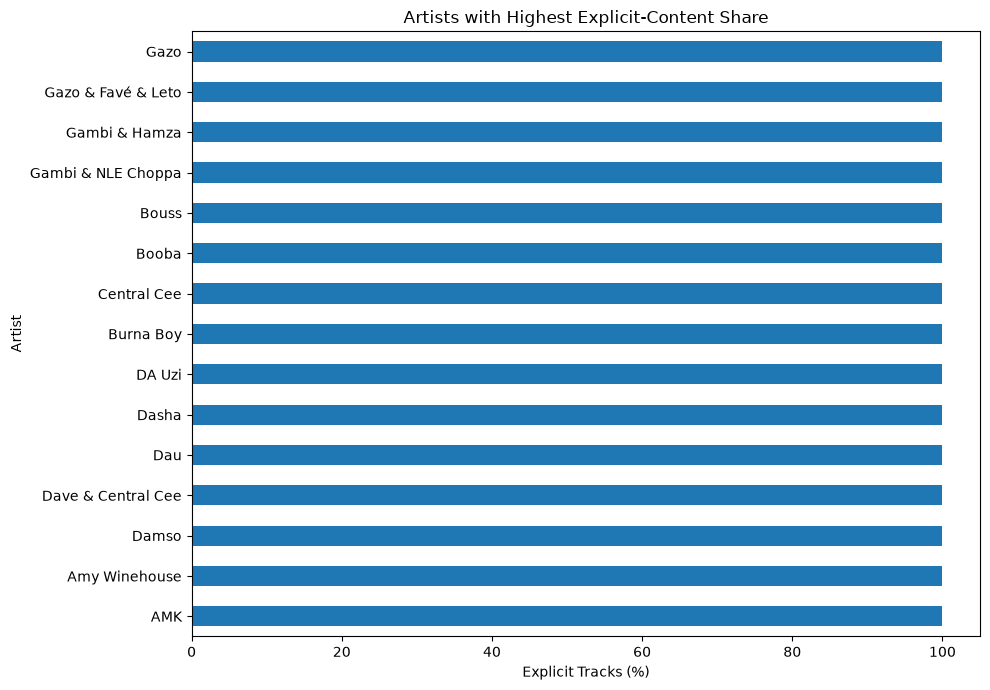

In [96]:
top_explicit_artists = (
    explicit_artist_share
    .head(15)
    .sort_values()
)

plt.figure(figsize=(10, 7))

top_explicit_artists.plot(
    kind="barh"
)

plt.title("Artists with Highest Explicit-Content Share")
plt.xlabel("Explicit Tracks (%)")
plt.ylabel("Artist")
plt.tight_layout()
plt.show()

In [97]:
lowest_explicit_artists = (
    explicit_artist_share
    .sort_values()
    .head(15)
)

lowest_explicit_artists

artist
Becky G & Omega                      0.0
Brenda Lee                           0.0
Billie Eilish                        0.0
Corneille & Aya Nakamura & Trinix    0.0
Carbonne                             0.0
GIMS & Dadju                         0.0
Harry Styles                         0.0
Eva                                  0.0
Arma Jackson                         0.0
Andy Williams                        0.0
Artemas                              0.0
Adam Port & Stryv & Keinemusik       0.0
Aden Foyer                           0.0
BENNETT                              0.0
GIMS & DYSTINCT                      0.0
Name: True, dtype: float64

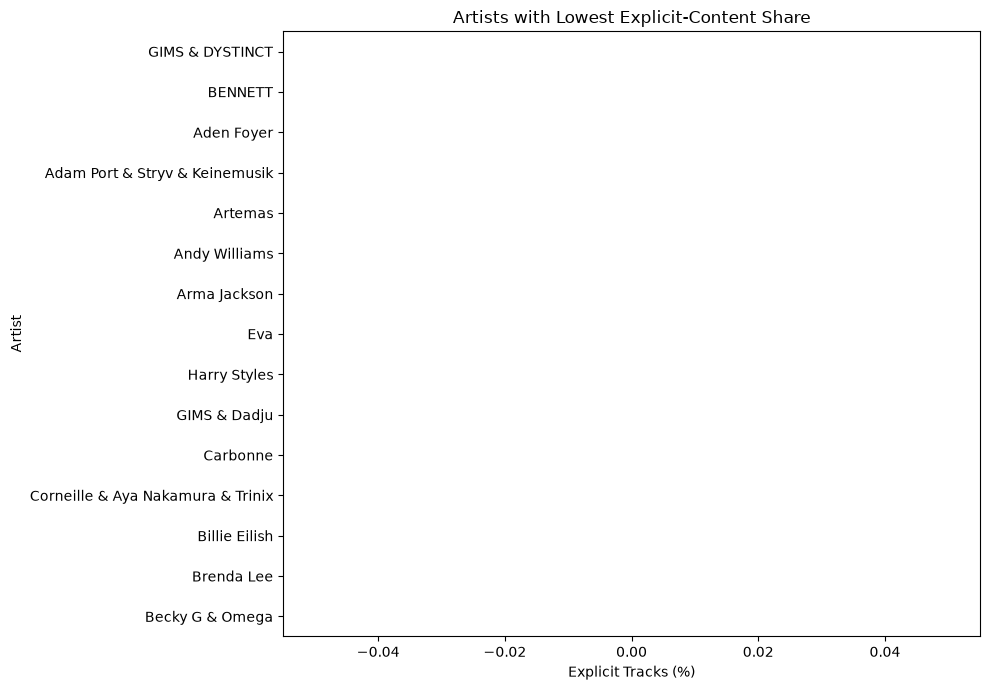

In [98]:
plt.figure(figsize=(10, 7))

lowest_explicit_artists.sort_values().plot(
    kind="barh"
)

plt.title("Artists with Lowest Explicit-Content Share")
plt.xlabel("Explicit Tracks (%)")
plt.ylabel("Artist")
plt.tight_layout()
plt.show()

In [99]:
artist_overall = (
    artist_df
    .groupby("artist")
    .agg(
        total_records=("song", "count"),
        avg_popularity=("popularity", "mean"),
        avg_position=("position", "mean"),
        avg_duration=("duration_min", "mean")
    )
)

artist_overall = artist_overall.sort_values(
    "avg_popularity",
    ascending=False
)

artist_overall.head(15).round(2)

,total_records,avg_popularity,avg_position,avg_duration
artist,,,,
Jack Harlow,15,98.80,46.00,2.31
Lady Gaga & Bruno Mars,96,98.70,19.69,4.19
Djo,16,97.06,45.69,2.65
Taylor Swift,68,97.06,42.75,3.21
Tate McRae,216,96.84,13.67,2.20
FloyyMenor & Cris Mj,115,96.34,3.89,3.70
Metro Boomin,35,95.89,39.31,3.69
David Kushner,246,95.76,25.39,3.55
Kenya Grace,177,95.59,20.99,2.88


In [100]:
artist_analysis = artist_overall.copy()

if True in artist_explicit_pct.columns:
    artist_analysis["explicit_pct"] = artist_explicit_pct[True]

if False in artist_explicit_pct.columns:
    artist_analysis["non_explicit_pct"] = artist_explicit_pct[False]

artist_analysis = artist_analysis.sort_values(
    "explicit_pct",
    ascending=False
)

artist_analysis.head(20).round(2)

,total_records,avg_popularity,avg_position,avg_duration,explicit_pct,non_explicit_pct
artist,,,,,,
Jack Harlow,15,98.80,46.00,2.31,100.0,0.0
FloyyMenor & Cris Mj,115,96.34,3.89,3.70,100.0,0.0
Tate McRae,216,96.84,13.67,2.20,100.0,0.0
Metro Boomin,35,95.89,39.31,3.69,100.0,0.0
Eminem,12,88.00,37.83,3.79,100.0,0.0
Dasha,47,91.06,41.11,2.86,100.0,0.0
Tom Odell,86,91.36,41.65,4.07,100.0,0.0
YG Marley,27,92.11,39.56,4.38,100.0,0.0
cassö & RAYE & D-Block Europe,92,93.52,34.83,2.21,100.0,0.0


In [101]:
artist_analysis.to_csv(
    "data/saved/artist_explicit_analysis.csv"
)

artist_explicit_summary.to_csv(
    "data/saved/artist_explicit_summary.csv",
    index=False
)

print("Artist-level analysis saved successfully.")

Artist-level analysis saved successfully.


#### Trends in Explicit Content Over Time

In [102]:
daily_explicit = (
    df_clean
    .groupby(["date", "is_explicit"])
    .agg(
        track_count=("song", "count")
    )
    .reset_index()
)

daily_explicit.head()

,date,is_explicit,track_count
0,2024-05-18,False,18
1,2024-05-18,True,32
2,2024-05-19,False,19
3,2024-05-19,True,31
4,2024-05-20,False,23


In [103]:
daily_explicit_pct = (
    pd.crosstab(
        df_clean["date"],
        df_clean["is_explicit"],
        normalize="index"
    ) * 100
)

daily_explicit_pct = daily_explicit_pct.round(2)

daily_explicit_pct.head()

is_explicit,False,True
date,,
2024-05-18,36.0,64.0
2024-05-19,38.0,62.0
2024-05-20,46.0,54.0
2024-05-21,46.0,54.0
2024-05-22,46.0,54.0


In [104]:
daily_explicit_analysis = daily_explicit_pct.reset_index()

daily_explicit_analysis.head()

is_explicit,date,False,True
0,2024-05-18,36.0,64.0
1,2024-05-19,38.0,62.0
2,2024-05-20,46.0,54.0
3,2024-05-21,46.0,54.0
4,2024-05-22,46.0,54.0


In [105]:
daily_explicit_analysis = daily_explicit_analysis.rename(
    columns={
        True: "explicit_pct",
        False: "non_explicit_pct"
    }
)

daily_explicit_analysis.head()

is_explicit,date,non_explicit_pct,explicit_pct
0,2024-05-18,36.0,64.0
1,2024-05-19,38.0,62.0
2,2024-05-20,46.0,54.0
3,2024-05-21,46.0,54.0
4,2024-05-22,46.0,54.0


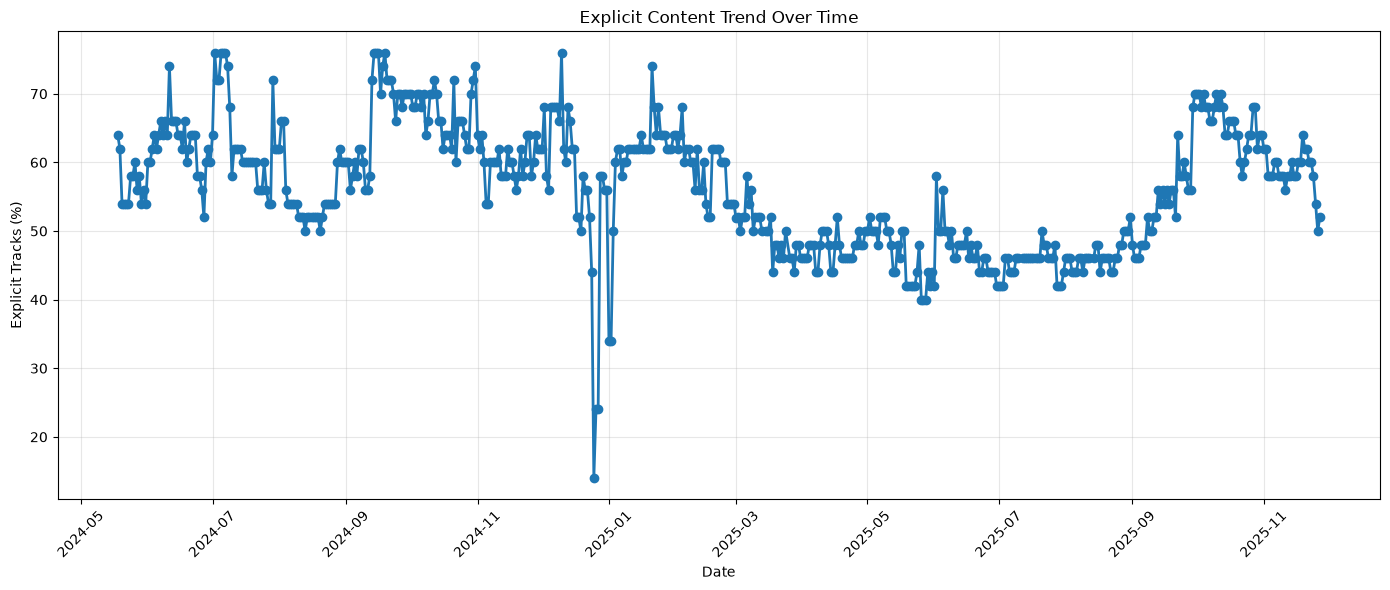

In [106]:
plt.figure(figsize=(14, 6))

plt.plot(
    daily_explicit_analysis["date"],
    daily_explicit_analysis["explicit_pct"],
    marker="o",
    linewidth=2
)

plt.title("Explicit Content Trend Over Time")
plt.xlabel("Date")
plt.ylabel("Explicit Tracks (%)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [107]:
print(
    "Average daily explicit percentage:",
    round(
        daily_explicit_analysis["explicit_pct"].mean(),
        2
    ),
    "%"
)

print(
    "Minimum daily explicit percentage:",
    round(
        daily_explicit_analysis["explicit_pct"].min(),
        2
    ),
    "%"
)

print(
    "Maximum daily explicit percentage:",
    round(
        daily_explicit_analysis["explicit_pct"].max(),
        2
    ),
    "%"
)

Average daily explicit percentage: 56.26 %
Minimum daily explicit percentage: 14.0 %
Maximum daily explicit percentage: 76.0 %


In [108]:
highest_explicit_dates = (
    daily_explicit_analysis
    .nlargest(10, "explicit_pct")
)

highest_explicit_dates

is_explicit,date,non_explicit_pct,explicit_pct
45,2024-07-02,24.0,76.0
48,2024-07-05,24.0,76.0
49,2024-07-06,24.0,76.0
50,2024-07-07,24.0,76.0
119,2024-09-14,24.0,76.0
120,2024-09-15,24.0,76.0
121,2024-09-16,24.0,76.0
124,2024-09-19,24.0,76.0
206,2024-12-10,24.0,76.0
24,2024-06-11,26.0,74.0


In [109]:
lowest_explicit_dates = (
    daily_explicit_analysis
    .nsmallest(10, "explicit_pct")
)

lowest_explicit_dates

is_explicit,date,non_explicit_pct,explicit_pct
221,2024-12-25,86.0,14.0
222,2024-12-26,76.0,24.0
223,2024-12-27,76.0,24.0
228,2025-01-01,66.0,34.0
229,2025-01-02,66.0,34.0
371,2025-05-26,60.0,40.0
372,2025-05-27,60.0,40.0
373,2025-05-28,60.0,40.0
364,2025-05-19,58.0,42.0
365,2025-05-20,58.0,42.0


In [110]:
first_value = (
    daily_explicit_analysis
    .sort_values("date")
    .iloc[0]["explicit_pct"]
)

last_value = (
    daily_explicit_analysis
    .sort_values("date")
    .iloc[-1]["explicit_pct"]
)

change = last_value - first_value

print("First recorded explicit percentage:", round(first_value, 2), "%")
print("Last recorded explicit percentage:", round(last_value, 2), "%")
print("Change:", round(change, 2), "percentage points")

First recorded explicit percentage: 64.0 %
Last recorded explicit percentage: 52.0 %
Change: -12.0 percentage points


In [111]:
daily_explicit_analysis = (
    daily_explicit_analysis
    .sort_values("date")
    .copy()
)

daily_explicit_analysis["explicit_7day_avg"] = (
    daily_explicit_analysis["explicit_pct"]
    .rolling(window=7, min_periods=1)
    .mean()
)

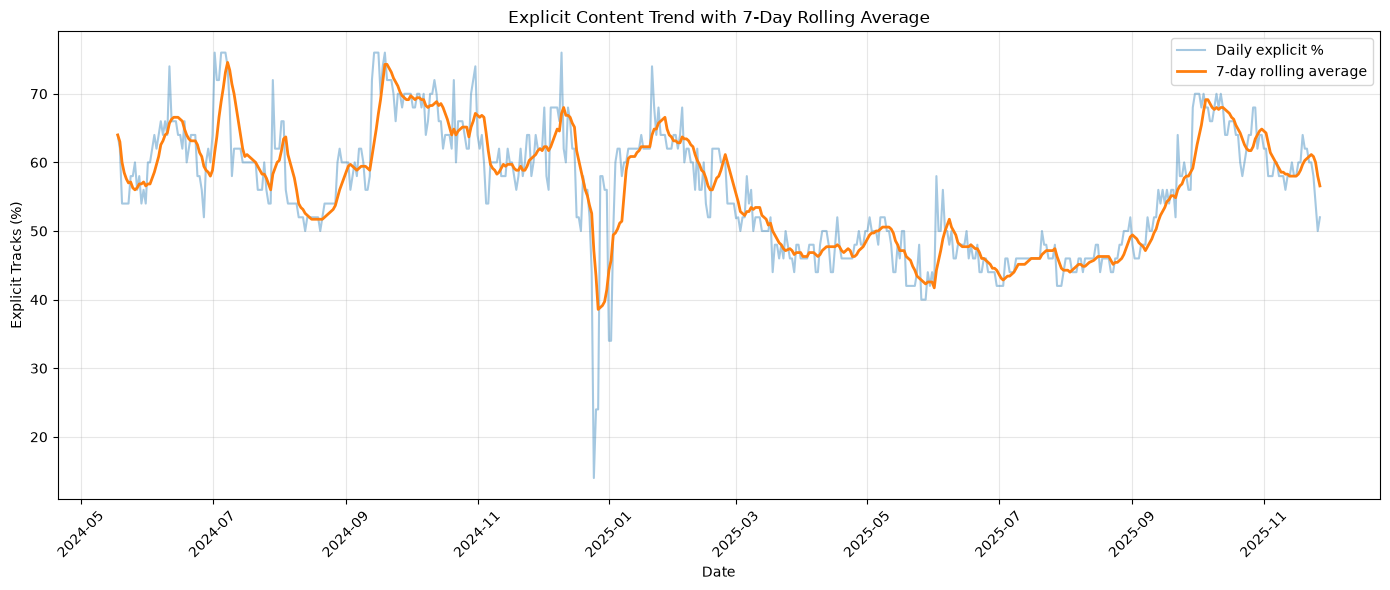

In [112]:
plt.figure(figsize=(14, 6))

plt.plot(
    daily_explicit_analysis["date"],
    daily_explicit_analysis["explicit_pct"],
    alpha=0.4,
    label="Daily explicit %"
)

plt.plot(
    daily_explicit_analysis["date"],
    daily_explicit_analysis["explicit_7day_avg"],
    linewidth=2,
    label="7-day rolling average"
)

plt.title("Explicit Content Trend with 7-Day Rolling Average")
plt.xlabel("Date")
plt.ylabel("Explicit Tracks (%)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [113]:
daily_explicit_analysis.to_csv(
    "data/saved/daily_explicit_content_trend.csv",
    index=False
)

print("Time-series analysis saved successfully.")

Time-series analysis saved successfully.


#### Combined Audience-Sensitivity Summary

In [114]:
overall_sensitivity = (
    df_clean
    .groupby("is_explicit")
    .agg(
        track_count=("song", "count"),
        avg_popularity=("popularity", "mean"),
        median_popularity=("popularity", "median"),
        avg_position=("position", "mean"),
        median_position=("position", "median"),
        avg_duration=("duration_min", "mean"),
        median_duration=("duration_min", "median")
    )
    .round(2)
)

overall_sensitivity

,track_count,avg_popularity,median_popularity,avg_position,median_position,avg_duration,median_duration
is_explicit,,,,,,,
False,12152,80.90,81.0,26.16,26.0,3.04,3.01
True,15629,73.33,74.0,24.99,25.0,3.13,2.99


In [115]:
overall_percentage = (
    df_clean["is_explicit"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

overall_percentage

is_explicit
True     56.26
False    43.74
Name: proportion, dtype: float64

In [116]:
audience_sensitivity_summary = (
    df_clean
    .groupby("is_explicit")
    .agg(
        track_count=("song", "count"),
        avg_popularity=("popularity", "mean"),
        avg_chart_position=("position", "mean"),
        avg_duration_min=("duration_min", "mean"),
        unique_artists=("artist", "nunique"),
        unique_songs=("song", "nunique")
    )
    .reset_index()
)

audience_sensitivity_summary["track_percentage"] = (
    audience_sensitivity_summary["track_count"]
    / audience_sensitivity_summary["track_count"].sum()
    * 100
).round(2)

audience_sensitivity_summary.round(2)

,is_explicit,track_count,avg_popularity,avg_chart_position,avg_duration_min,unique_artists,unique_songs,track_percentage
0,False,12152,80.90,26.16,3.04,193,242,43.74
1,True,15629,73.33,24.99,3.13,150,461,56.26


In [117]:
top10_sensitivity = (
    df_clean[df_clean["position"] <= 10]
    .groupby("is_explicit")
    .agg(
        track_count=("song", "count"),
        avg_popularity=("popularity", "mean"),
        avg_duration=("duration_min", "mean")
    )
    .reset_index()
)

top10_sensitivity.round(2)

,is_explicit,track_count,avg_popularity,avg_duration
0,False,2088,81.81,3.00
1,True,3466,76.14,3.14


In [118]:
top10_percentage = (
    df_clean[df_clean["position"] <= 10]["is_explicit"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

top10_percentage

is_explicit
True     62.41
False    37.59
Name: proportion, dtype: float64

In [119]:
album_sensitivity_summary = (
    df_clean
    .groupby(["album_type", "is_explicit"])
    .agg(
        track_count=("song", "count"),
        avg_popularity=("popularity", "mean"),
        avg_duration=("duration_min", "mean")
    )
    .reset_index()
)

album_sensitivity_summary.round(2)

,album_type,is_explicit,track_count,avg_popularity,avg_duration
0,album,False,4051,77.01,3.19
1,album,True,10635,71.45,3.15
2,compilation,False,9,79.33,2.91
3,single,False,8092,82.85,2.97
4,single,True,4994,77.33,3.09


In [120]:
artist_sensitivity_summary = (
    artist_analysis
    .sort_values(
        "total_records",
        ascending=False
    )
)

artist_sensitivity_summary.head(20).round(2)

,total_records,avg_popularity,avg_position,avg_duration,explicit_pct,non_explicit_pct
artist,,,,,,
Werenoi,2201,71.97,28.20,2.97,100.00,0.00
PLK,905,73.07,27.32,2.84,96.69,3.31
SDM,901,74.82,21.47,3.13,100.00,0.00
Jul,711,69.68,27.29,3.52,98.45,1.55
Ninho,622,73.82,25.64,3.26,90.68,9.32
Favé,597,72.04,26.44,2.78,100.00,0.00
Tiakola,594,72.69,20.41,2.95,100.00,0.00
GIMS,559,65.08,24.84,2.96,0.00,100.00
KeBlack,546,74.88,18.35,2.75,48.35,51.65


In [121]:
time_sensitivity_summary = {
    "average_daily_explicit_pct":
        round(
            daily_explicit_analysis["explicit_pct"].mean(),
            2
        ),

    "minimum_daily_explicit_pct":
        round(
            daily_explicit_analysis["explicit_pct"].min(),
            2
        ),

    "maximum_daily_explicit_pct":
        round(
            daily_explicit_analysis["explicit_pct"].max(),
            2
        ),

    "first_recorded_explicit_pct":
        round(
            daily_explicit_analysis
            .sort_values("date")
            .iloc[0]["explicit_pct"],
            2
        ),

    "last_recorded_explicit_pct":
        round(
            daily_explicit_analysis
            .sort_values("date")
            .iloc[-1]["explicit_pct"],
            2
        )
}

time_sensitivity_summary

{'average_daily_explicit_pct': np.float64(56.26),
 'minimum_daily_explicit_pct': np.float64(14.0),
 'maximum_daily_explicit_pct': np.float64(76.0),
 'first_recorded_explicit_pct': np.float64(64.0),
 'last_recorded_explicit_pct': np.float64(52.0)}

In [122]:
combined_summary = pd.DataFrame({
    "Analysis Area": [
        "Overall explicit-content representation",
        "Chart position",
        "Song duration",
        "Album type",
        "Artist-level patterns",
        "Time trend"
    ],

    "Dataset Measure": [
        "Explicit vs. non-explicit percentage",
        "Explicit-content distribution by chart position",
        "Average and median duration",
        "Explicit-content distribution by album type",
        "Explicit-content percentage by eligible artist",
        "Daily explicit-content percentage"
    ]
})

combined_summary

,Analysis Area,Dataset Measure
0,Overall explicit-content representation,Explicit vs. non-explicit percentage
1,Chart position,Explicit-content distribution by chart position
2,Song duration,Average and median duration
3,Album type,Explicit-content distribution by album type
4,Artist-level patterns,Explicit-content percentage by eligible artist
5,Time trend,Daily explicit-content percentage


In [123]:
audience_sensitivity_summary.to_csv(
    "data/saved/audience_sensitivity_summary.csv",
    index=False
)

album_sensitivity_summary.to_csv(
    "data/saved/album_sensitivity_summary.csv",
    index=False
)

artist_sensitivity_summary.to_csv(
    "data/saved/artist_sensitivity_summary.csv"
)

combined_summary.to_csv(
    "data/saved/combined_audience_sensitivity_summary.csv",
    index=False
)

print("Combined audience-sensitivity analysis saved successfully.")

Combined audience-sensitivity analysis saved successfully.


#### Content Compliance Analysis

In [124]:
compliance_summary = (
    df_clean
    .groupby("is_explicit")
    .agg(
        track_count=("song", "count"),
        unique_songs=("song", "nunique"),
        unique_artists=("artist", "nunique"),
        avg_popularity=("popularity", "mean"),
        avg_chart_position=("position", "mean"),
        avg_duration_min=("duration_min", "mean")
    )
    .reset_index()
)

compliance_summary = compliance_summary.round(2)

compliance_summary

,is_explicit,track_count,unique_songs,unique_artists,avg_popularity,avg_chart_position,avg_duration_min
0,False,12152,242,193,80.90,26.16,3.04
1,True,15629,461,150,73.33,24.99,3.13


In [125]:
compliance_distribution = (
    df_clean["is_explicit"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("Explicit-content distribution:")
print(compliance_distribution)

Explicit-content distribution:
is_explicit
True     56.26
False    43.74
Name: proportion, dtype: float64


In [126]:
df_clean["content_compliance_category"] = np.where(
    df_clean["is_explicit"] == True,
    "Explicit",
    "Non-Explicit"
)

df_clean[
    ["song", "artist", "is_explicit", "content_compliance_category"]
].head(10)

,song,artist,is_explicit,content_compliance_category
0,LA RUE,No Limit & Gazo & Damso,True,Explicit
1,C'est carré le S,Naps,False,Non-Explicit
2,Freestyle LVL UP 1,Ninho,True,Explicit
3,Bolide allemand,SDM,True,Explicit
4,Freestyle LVL UP 2,Ninho,True,Explicit
5,Demain,PLK,True,Explicit
6,Meuda,Tiakola,True,Explicit
7,Jolie (feat. Ninho),GAULOIS,True,Explicit
8,Flowers,Miley Cyrus,False,Non-Explicit
9,Capitaine,Djadja & Dinaz,True,Explicit


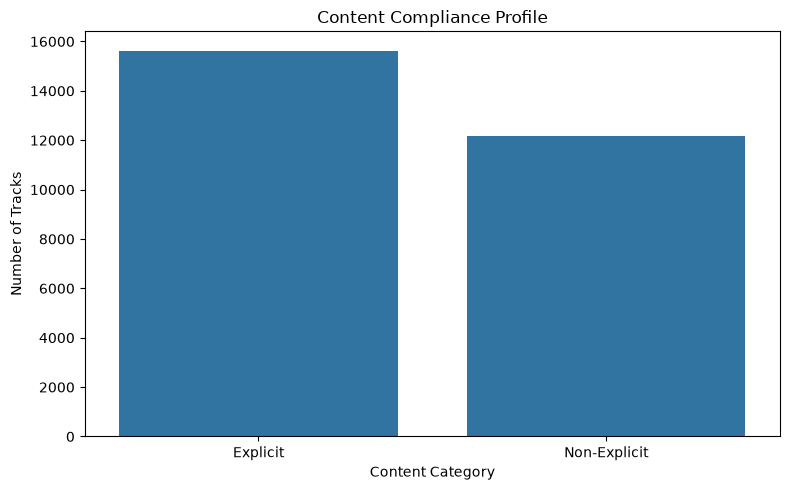

In [127]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="content_compliance_category"
)

plt.title("Content Compliance Profile")
plt.xlabel("Content Category")
plt.ylabel("Number of Tracks")
plt.tight_layout()
plt.show()

In [128]:
compliance_percentage = (
    df_clean["content_compliance_category"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(compliance_percentage)

content_compliance_category
Explicit        56.26
Non-Explicit    43.74
Name: proportion, dtype: float64


In [129]:
explicit_pct = (
    df_clean["is_explicit"]
    .mean() * 100
)

non_explicit_pct = 100 - explicit_pct

print(f"Explicit content: {explicit_pct:.2f}%")
print(f"Non-explicit content: {non_explicit_pct:.2f}%")

Explicit content: 56.26%
Non-explicit content: 43.74%


In [130]:
compliance_summary.to_csv(
    "data/saved/content_compliance_summary.csv",
    index=False
)

print("Step 5.1 completed successfully.")

Step 5.1 completed successfully.


#### Explicit Content by Chart Position

In [131]:
position_compliance = (
    df_clean
    .groupby(["position", "is_explicit"])
    .agg(
        track_count=("song", "count"),
        avg_popularity=("popularity", "mean")
    )
    .reset_index()
)

position_compliance.round(2)

,position,is_explicit,track_count,avg_popularity
0,1,False,231,81.36
1,1,True,324,76.81
2,2,False,249,81.24
3,2,True,306,76.77
4,3,False,158,84.81
...,...,...,...,...
95,48,True,287,72.54
96,49,False,284,77.96
97,49,True,271,70.93
98,50,False,251,77.71


In [132]:
position_compliance_pct = (
    pd.crosstab(
        df_clean["position"],
        df_clean["is_explicit"],
        normalize="index"
    ) * 100
)

position_compliance_pct = position_compliance_pct.round(2)

position_compliance_pct

is_explicit,False,True
position,,
1,41.62,58.38
2,44.86,55.14
3,28.47,71.53
4,32.01,67.99
5,35.43,64.57
6,36.76,63.24
7,37.66,62.34
8,44.86,55.14
9,39.57,60.43


In [133]:
top10_compliance = (
    df_clean[df_clean["position"] <= 10]
    .groupby("is_explicit")
    .agg(
        track_count=("song", "count"),
        avg_popularity=("popularity", "mean"),
        avg_duration=("duration_min", "mean")
    )
    .reset_index()
)

top10_compliance.round(2)

,is_explicit,track_count,avg_popularity,avg_duration
0,False,2088,81.81,3.00
1,True,3466,76.14,3.14


In [134]:
top10_compliance_pct = (
    df_clean[df_clean["position"] <= 10]["is_explicit"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(top10_compliance_pct)

is_explicit
True     62.41
False    37.59
Name: proportion, dtype: float64


In [135]:
df_clean["chart_group"] = np.where(
    df_clean["position"] <= 10,
    "Top 10",
    "Positions 11-50"
)

In [136]:
chart_compliance = (
    pd.crosstab(
        df_clean["chart_group"],
        df_clean["is_explicit"],
        normalize="index"
    ) * 100
)

chart_compliance.round(2)

is_explicit,False,True
chart_group,,
Positions 11-50,45.28,54.72
Top 10,37.59,62.41


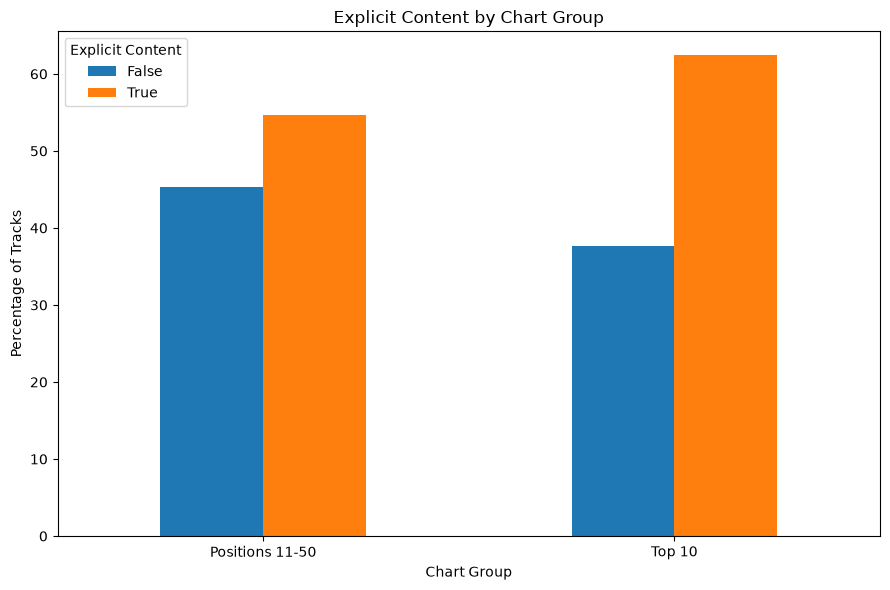

In [137]:
chart_compliance.plot(
    kind="bar",
    figsize=(9, 6)
)

plt.title("Explicit Content by Chart Group")
plt.xlabel("Chart Group")
plt.ylabel("Percentage of Tracks")
plt.xticks(rotation=0)
plt.legend(title="Explicit Content")
plt.tight_layout()
plt.show()

In [138]:
position_popularity_compliance = (
    df_clean
    .groupby(["chart_group", "is_explicit"])["popularity"]
    .agg(
        count="count",
        mean="mean",
        median="median"
    )
    .round(2)
)

position_popularity_compliance

count   mean  median
chart_group     is_explicit                      
Positions 11-50 False        10064  80.71    81.0
                True         12163  72.53    73.0
Top 10          False         2088  81.81    81.0
                True          3466  76.14    77.0

In [139]:
avg_position_compliance = (
    df_clean
    .groupby("is_explicit")["position"]
    .agg(
        count="count",
        mean="mean",
        median="median"
    )
    .round(2)
)

avg_position_compliance

,count,mean,median
is_explicit,,,
False,12152,26.16,26.0
True,15629,24.99,25.0


In [140]:
position_compliance.to_csv(
    "data/saved/position_compliance_summary.csv",
    index=False
)

position_compliance_pct.to_csv(
    "data/saved/position_compliance_percentage.csv"
)

chart_compliance.to_csv(
    "data/saved/chart_group_compliance.csv"
)

print("Step 5.2 completed successfully.")

Step 5.2 completed successfully.


#### Explicit Content by Popularity

In [141]:
popularity_compliance = (
    df_clean
    .groupby("is_explicit")["popularity"]
    .agg(
        track_count="count",
        average_popularity="mean",
        median_popularity="median",
        minimum_popularity="min",
        maximum_popularity="max"
    )
    .round(2)
)

popularity_compliance

,track_count,average_popularity,median_popularity,minimum_popularity,maximum_popularity
is_explicit,,,,,
False,12152,80.90,81.0,0,100
True,15629,73.33,74.0,0,100


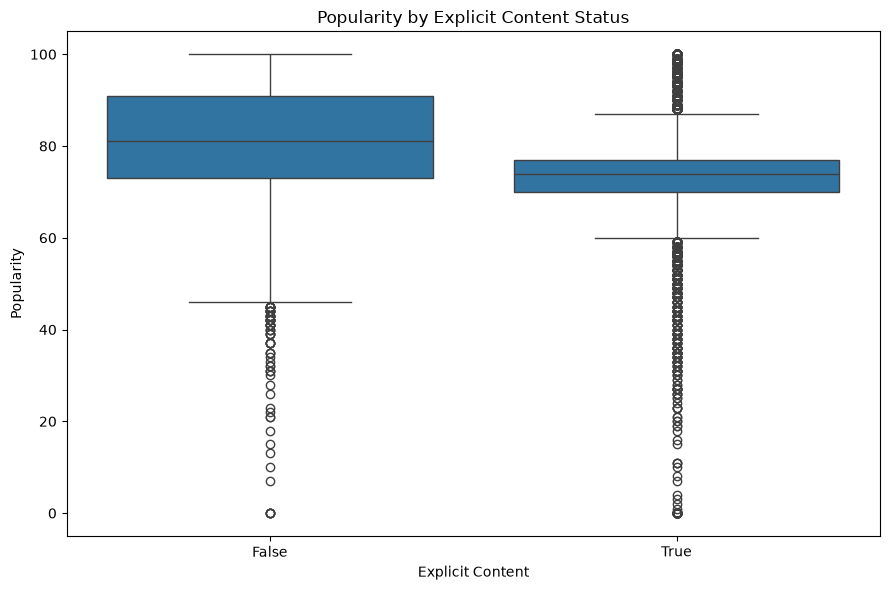

In [142]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df_clean,
    x="is_explicit",
    y="popularity"
)

plt.title("Popularity by Explicit Content Status")
plt.xlabel("Explicit Content")
plt.ylabel("Popularity")
plt.tight_layout()
plt.show()

In [143]:
df_clean["popularity_group"] = pd.cut(
    df_clean["popularity"],
    bins=[-1, 25, 50, 75, 100],
    labels=[
        "0–25",
        "26–50",
        "51–75",
        "76–100"
    ]
)

df_clean["popularity_group"].value_counts().sort_index()

popularity_group
0–25        108
26–50       360
51–75     13930
76–100    13383
Name: count, dtype: int64

In [144]:
popularity_group_compliance = (
    pd.crosstab(
        df_clean["popularity_group"],
        df_clean["is_explicit"],
        normalize="index"
    ) * 100
)

popularity_group_compliance.round(2)

is_explicit,False,True
popularity_group,,
0–25,12.96,87.04
26–50,33.06,66.94
51–75,30.14,69.86
76–100,58.43,41.57


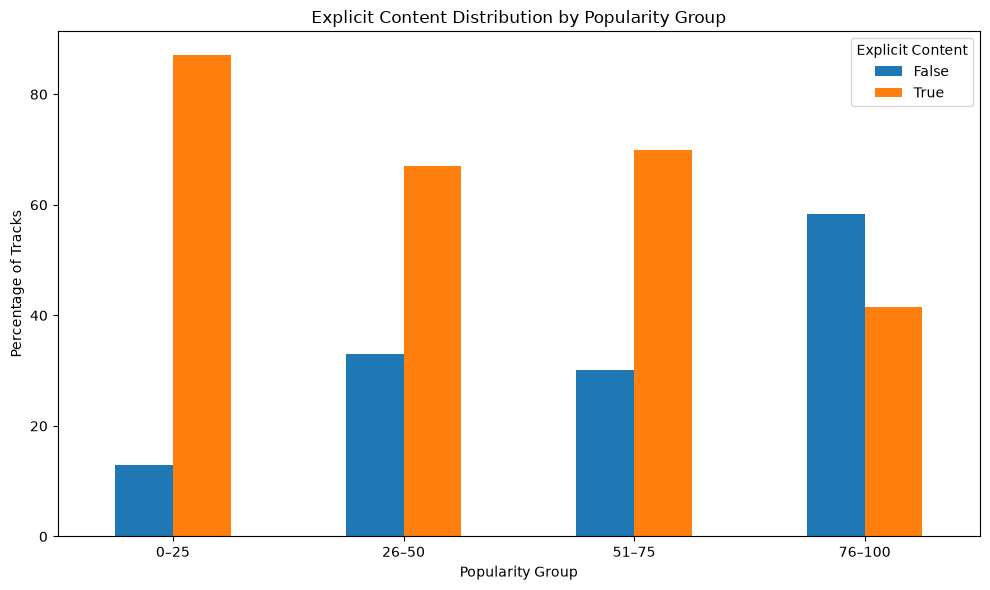

In [145]:
popularity_group_compliance.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Explicit Content Distribution by Popularity Group")
plt.xlabel("Popularity Group")
plt.ylabel("Percentage of Tracks")
plt.xticks(rotation=0)
plt.legend(title="Explicit Content")
plt.tight_layout()
plt.show()

In [146]:
popularity_position = (
    df_clean
    .groupby("is_explicit")
    .agg(
        average_popularity=("popularity", "mean"),
        median_popularity=("popularity", "median"),
        average_position=("position", "mean"),
        median_position=("position", "median")
    )
    .round(2)
)

popularity_position

,average_popularity,median_popularity,average_position,median_position
is_explicit,,,,
False,80.90,81.0,26.16,26.0
True,73.33,74.0,24.99,25.0


In [147]:
top_popular_tracks = (
    df_clean
    .nlargest(
        20,
        "popularity"
    )
    [
        [
            "song",
            "artist",
            "popularity",
            "position",
            "is_explicit"
        ]
    ]
)

top_popular_tracks

,song,artist,popularity,position,is_explicit
6011,Paint The Town Red,Doja Cat,100,12,True
6061,Paint The Town Red,Doja Cat,100,12,True
6110,Paint The Town Red,Doja Cat,100,11,True
6158,Paint The Town Red,Doja Cat,100,9,True
6207,Paint The Town Red,Doja Cat,100,8,True
6255,Paint The Town Red,Doja Cat,100,6,True
6305,Paint The Town Red,Doja Cat,100,6,True
6354,Paint The Town Red,Doja Cat,100,5,True
6405,Paint The Town Red,Doja Cat,100,6,True
8656,greedy,Tate McRae,100,7,True


In [148]:
high_popularity = df_clean[
    df_clean["popularity"] >= 75
]

high_popularity_compliance = (
    high_popularity["is_explicit"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("Popularity >= 75:")
print(high_popularity_compliance)

Popularity >= 75:
is_explicit
False    55.07
True     44.93
Name: proportion, dtype: float64


In [149]:
medium_high_popularity = df_clean[
    df_clean["popularity"] >= 50
]

medium_high_compliance = (
    medium_high_popularity["is_explicit"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("Popularity >= 50:")
print(medium_high_compliance)

Popularity >= 50:
is_explicit
True     55.99
False    44.01
Name: proportion, dtype: float64


In [150]:
popularity_compliance.to_csv(
    "data/saved/popularity_compliance_summary.csv"
)

popularity_group_compliance.to_csv(
    "data/saved/popularity_group_compliance.csv"
)

popularity_position.to_csv(
    "data/saved/popularity_position_compliance.csv"
)

print("Step 5.3 completed successfully.")

Step 5.3 completed successfully.


#### Explicit Content by Album Type

In [151]:
album_type_counts = (
    df_clean["album_type"]
    .value_counts(dropna=False)
)

print(album_type_counts)

album_type
album          14686
single         13086
compilation        9
Name: count, dtype: int64


In [152]:
album_compliance = (
    df_clean
    .groupby(["album_type", "is_explicit"])
    .agg(
        track_count=("song", "count"),
        avg_popularity=("popularity", "mean"),
        median_popularity=("popularity", "median"),
        avg_duration=("duration_min", "mean"),
        median_duration=("duration_min", "median")
    )
    .reset_index()
)

album_compliance.round(2)

,album_type,is_explicit,track_count,avg_popularity,median_popularity,avg_duration,median_duration
0,album,False,4051,77.01,75.0,3.19,3.14
1,album,True,10635,71.45,73.0,3.15,3.02
2,compilation,False,9,79.33,75.0,2.91,3.28
3,single,False,8092,82.85,83.0,2.97,2.97
4,single,True,4994,77.33,76.0,3.09,2.99


In [153]:
album_compliance_pct = (
    pd.crosstab(
        df_clean["album_type"],
        df_clean["is_explicit"],
        normalize="index"
    ) * 100
)

album_compliance_pct.round(2)

is_explicit,False,True
album_type,,
album,27.58,72.42
compilation,100.00,0.00
single,61.84,38.16


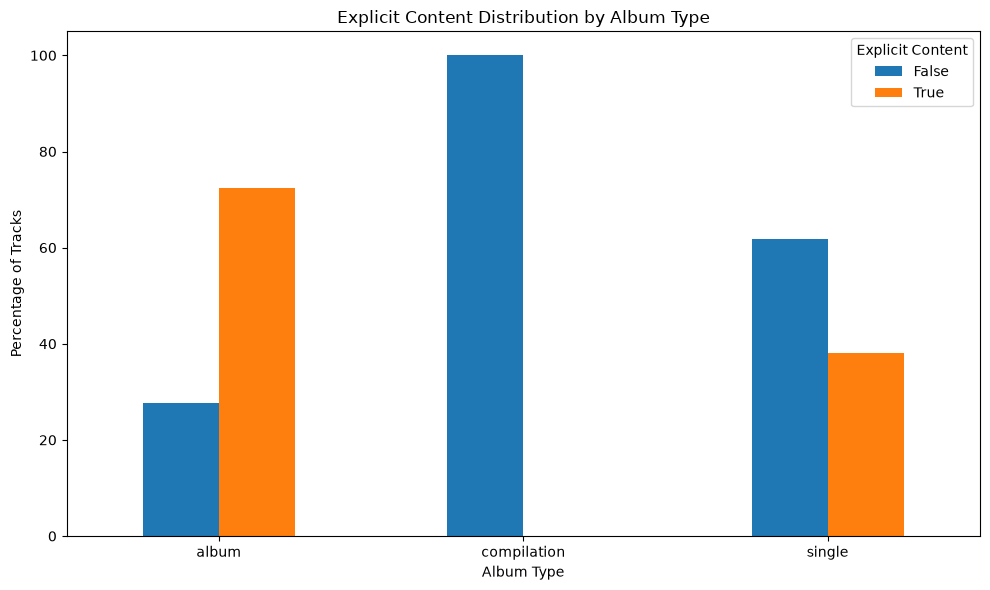

In [154]:
album_compliance_pct.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Explicit Content Distribution by Album Type")
plt.xlabel("Album Type")
plt.ylabel("Percentage of Tracks")
plt.xticks(rotation=0)
plt.legend(title="Explicit Content")
plt.tight_layout()
plt.show()

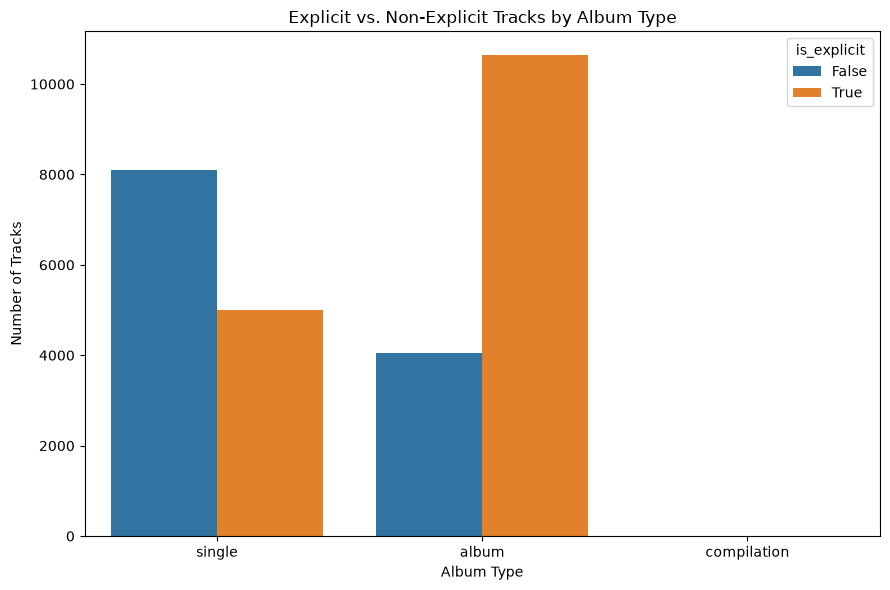

In [155]:
plt.figure(figsize=(9, 6))

sns.countplot(
    data=df_clean,
    x="album_type",
    hue="is_explicit"
)

plt.title("Explicit vs. Non-Explicit Tracks by Album Type")
plt.xlabel("Album Type")
plt.ylabel("Number of Tracks")
plt.tight_layout()
plt.show()

In [156]:
album_popularity_compliance = (
    df_clean
    .groupby(["album_type", "is_explicit"])["popularity"]
    .agg(
        count="count",
        mean="mean",
        median="median"
    )
    .round(2)
)

album_popularity_compliance

count   mean  median
album_type  is_explicit                      
album       False         4051  77.01    75.0
            True         10635  71.45    73.0
compilation False            9  79.33    75.0
single      False         8092  82.85    83.0
            True          4994  77.33    76.0

In [157]:
album_duration_compliance = (
    df_clean
    .groupby(["album_type", "is_explicit"])["duration_min"]
    .agg(
        count="count",
        mean="mean",
        median="median"
    )
    .round(2)
)

album_duration_compliance

count  mean  median
album_type  is_explicit                     
album       False         4051  3.19    3.14
            True         10635  3.15    3.02
compilation False            9  2.91    3.28
single      False         8092  2.97    2.97
            True          4994  3.09    2.99

In [158]:
dominant_compliance = (
    album_compliance_pct
    .idxmax(axis=1)
    .to_frame("dominant_content_category")
)

dominant_compliance["percentage"] = (
    album_compliance_pct.max(axis=1)
)

dominant_compliance.round(2)

,dominant_content_category,percentage
album_type,,
album,True,72.42
compilation,False,100.00
single,False,61.84


In [159]:
album_compliance.to_csv(
    "data/saved/album_content_compliance.csv",
    index=False
)

album_compliance_pct.to_csv(
    "data/saved/album_content_compliance_percentage.csv"
)

album_popularity_compliance.to_csv(
    "data/saved/album_popularity_compliance.csv"
)

album_duration_compliance.to_csv(
    "data/saved/album_duration_compliance.csv"
)

dominant_compliance.to_csv(
    "data/saved/album_dominant_compliance.csv"
)

print("Step 5.4 completed successfully.")

Step 5.4 completed successfully.


#### Artist-Level Compliance Patterns

In [160]:
artist_counts = df_clean["artist"].value_counts()

artist_threshold = 10

eligible_artists = artist_counts[
    artist_counts >= artist_threshold
].index

artist_compliance_df = df_clean[
    df_clean["artist"].isin(eligible_artists)
].copy()

print("Eligible artists:", artist_compliance_df["artist"].nunique())
print("Records analyzed:", len(artist_compliance_df))

Eligible artists: 203
Records analyzed: 27385


In [161]:
artist_compliance = (
    artist_compliance_df
    .groupby(["artist", "is_explicit"])
    .agg(
        track_count=("song", "count"),
        avg_popularity=("popularity", "mean"),
        avg_position=("position", "mean"),
        avg_duration=("duration_min", "mean")
    )
    .reset_index()
)

artist_compliance.round(2)

,artist,is_explicit,track_count,avg_popularity,avg_position,avg_duration
0,AMK,True,84,62.68,19.86,3.20
1,Adam Port & Stryv & Keinemusik,False,85,89.85,29.42,2.96
2,Aden Foyer,False,95,76.05,40.68,3.36
3,Amy Winehouse,True,10,83.20,44.60,4.02
4,Andy Williams,False,12,78.33,26.92,2.52
...,...,...,...,...,...,...
215,Zokush,True,108,65.07,29.84,3.01
216,Zola,True,113,65.99,39.07,3.02
217,Zola & Koba LaD,True,213,67.78,20.89,2.61
218,cassö & RAYE & D-Block Europe,True,92,93.52,34.83,2.21


In [162]:
artist_compliance_pct = (
    pd.crosstab(
        artist_compliance_df["artist"],
        artist_compliance_df["is_explicit"],
        normalize="index"
    ) * 100
)

artist_compliance_pct = artist_compliance_pct.round(2)

artist_compliance_pct.head(20)

is_explicit,False,True
artist,,
AMK,0.00,100.00
Adam Port & Stryv & Keinemusik,100.00,0.00
Aden Foyer,100.00,0.00
Amy Winehouse,0.00,100.00
Andy Williams,100.00,0.00
Ariana Grande,42.19,57.81
Arma Jackson,100.00,0.00
Artemas,100.00,0.00
Aya Nakamura,100.00,0.00


In [163]:
artist_compliance_overall = (
    artist_compliance_df
    .groupby("artist")
    .agg(
        total_records=("song", "count"),
        unique_songs=("song", "nunique"),
        avg_popularity=("popularity", "mean"),
        avg_position=("position", "mean"),
        avg_duration_min=("duration_min", "mean")
    )
)

if True in artist_compliance_pct.columns:
    artist_compliance_overall["explicit_pct"] = (
        artist_compliance_pct[True]
    )

if False in artist_compliance_pct.columns:
    artist_compliance_overall["non_explicit_pct"] = (
        artist_compliance_pct[False]
    )

artist_compliance_overall = (
    artist_compliance_overall
    .sort_values("explicit_pct", ascending=False)
)

artist_compliance_overall.round(2)

,total_records,unique_songs,avg_popularity,avg_position,avg_duration_min,explicit_pct,non_explicit_pct
artist,,,,,,,
AMK,84,1,62.68,19.86,3.20,100.0,0.0
Amy Winehouse,10,1,83.20,44.60,4.02,100.0,0.0
Damso,94,16,64.44,21.90,3.08,100.0,0.0
Dave & Central Cee,68,1,95.06,39.06,3.82,100.0,0.0
Dau,48,1,74.15,24.73,3.00,100.0,0.0
...,...,...,...,...,...,...,...
Victor Thompson & Vacra,50,1,74.78,40.52,2.25,0.0,100.0
Zaho de Sagazan,102,1,73.20,34.22,3.31,0.0,100.0
Zara Larsson & David Guetta,18,1,69.83,45.39,3.72,0.0,100.0


In [164]:
highest_explicit_artists = (
    artist_compliance_overall
    .sort_values("explicit_pct", ascending=False)
    .head(15)
)

highest_explicit_artists.round(2)

,total_records,unique_songs,avg_popularity,avg_position,avg_duration_min,explicit_pct,non_explicit_pct
artist,,,,,,,
AMK,84,1,62.68,19.86,3.20,100.0,0.0
Amy Winehouse,10,1,83.20,44.60,4.02,100.0,0.0
Damso,94,16,64.44,21.90,3.08,100.0,0.0
Dave & Central Cee,68,1,95.06,39.06,3.82,100.0,0.0
Dau,48,1,74.15,24.73,3.00,100.0,0.0
Dasha,47,1,91.06,41.11,2.86,100.0,0.0
DA Uzi,79,1,71.05,25.13,3.72,100.0,0.0
Burna Boy,16,1,83.38,46.38,2.56,100.0,0.0
Central Cee,16,1,73.12,42.06,2.85,100.0,0.0


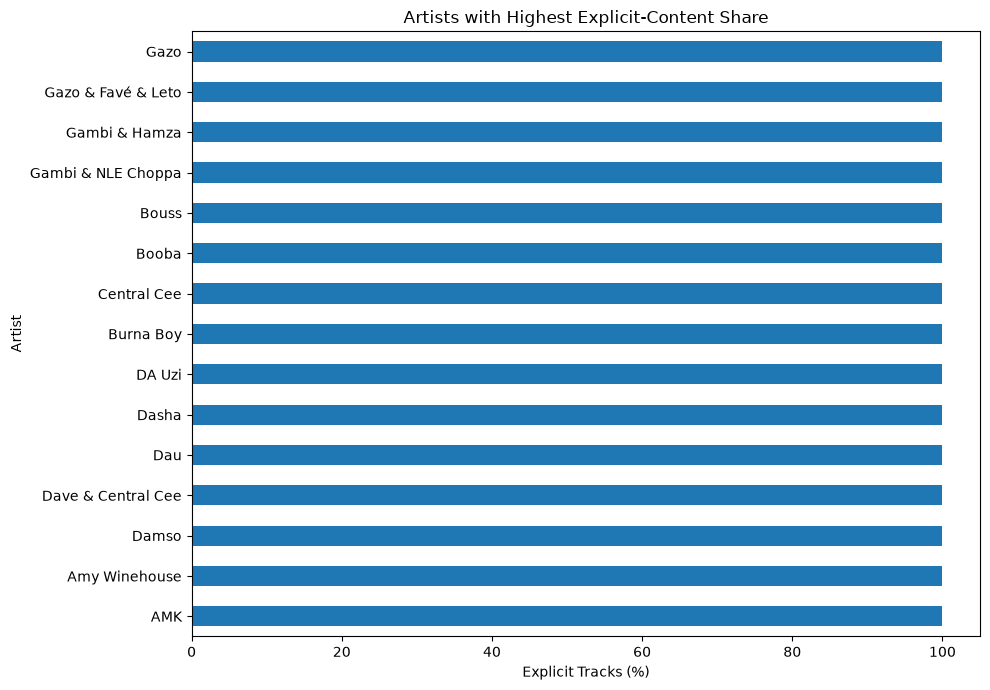

In [165]:
plt.figure(figsize=(10, 7))

highest_explicit_artists["explicit_pct"].sort_values().plot(
    kind="barh"
)

plt.title("Artists with Highest Explicit-Content Share")
plt.xlabel("Explicit Tracks (%)")
plt.ylabel("Artist")
plt.tight_layout()
plt.show()

In [166]:
lowest_explicit_artists = (
    artist_compliance_overall
    .sort_values("explicit_pct")
    .head(15)
)

lowest_explicit_artists.round(2)

,total_records,unique_songs,avg_popularity,avg_position,avg_duration_min,explicit_pct,non_explicit_pct
artist,,,,,,,
Becky G & Omega,139,1,82.81,27.99,2.78,0.0,100.0
Brenda Lee,10,2,90.10,22.50,2.10,0.0,100.0
Billie Eilish,246,9,94.63,31.19,3.67,0.0,100.0
Corneille & Aya Nakamura & Trinix,150,1,72.43,37.89,3.10,0.0,100.0
Carbonne,202,1,78.53,7.05,2.76,0.0,100.0
GIMS & Dadju,23,1,69.09,40.09,3.12,0.0,100.0
Harry Styles,47,1,92.64,35.72,2.79,0.0,100.0
Eva,82,2,60.05,39.68,3.01,0.0,100.0
Arma Jackson,33,1,61.03,25.79,2.88,0.0,100.0


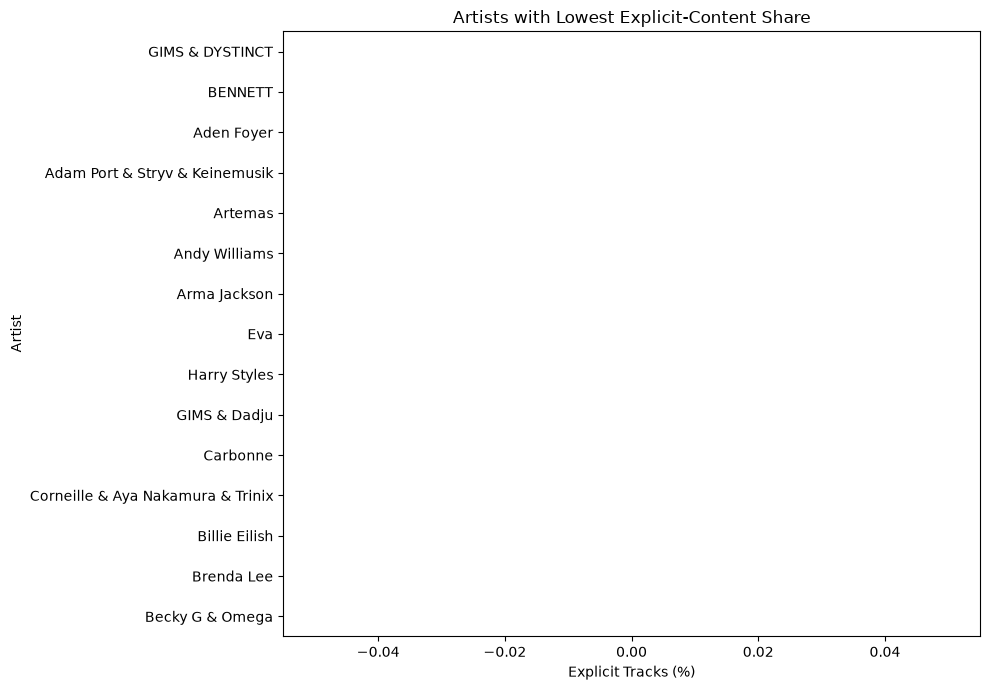

In [167]:
plt.figure(figsize=(10, 7))

lowest_explicit_artists["explicit_pct"].sort_values().plot(
    kind="barh"
)

plt.title("Artists with Lowest Explicit-Content Share")
plt.xlabel("Explicit Tracks (%)")
plt.ylabel("Artist")
plt.tight_layout()
plt.show()

In [168]:
artist_popularity_compliance = (
    artist_compliance_overall[
        [
            "total_records",
            "avg_popularity",
            "avg_position",
            "explicit_pct",
            "non_explicit_pct"
        ]
    ]
    .sort_values("avg_popularity", ascending=False)
)

artist_popularity_compliance.head(20).round(2)

,total_records,avg_popularity,avg_position,explicit_pct,non_explicit_pct
artist,,,,,
Jack Harlow,15,98.80,46.00,100.00,0.00
Lady Gaga & Bruno Mars,96,98.70,19.69,0.00,100.00
Djo,16,97.06,45.69,0.00,100.00
Taylor Swift,68,97.06,42.75,0.00,100.00
Tate McRae,216,96.84,13.67,100.00,0.00
FloyyMenor & Cris Mj,115,96.34,3.89,100.00,0.00
Metro Boomin,35,95.89,39.31,100.00,0.00
David Kushner,246,95.76,25.39,0.00,100.00
Kenya Grace,177,95.59,20.99,0.00,100.00


In [169]:
high_explicit_artist_flag = (
    artist_compliance_overall[
        artist_compliance_overall["explicit_pct"] >= 75
    ]
    .sort_values("explicit_pct", ascending=False)
)

high_explicit_artist_flag.round(2)

,total_records,unique_songs,avg_popularity,avg_position,avg_duration_min,explicit_pct,non_explicit_pct
artist,,,,,,,
AMK,84,1,62.68,19.86,3.20,100.00,0.00
Amy Winehouse,10,1,83.20,44.60,4.02,100.00,0.00
Damso,94,16,64.44,21.90,3.08,100.00,0.00
Dave & Central Cee,68,1,95.06,39.06,3.82,100.00,0.00
Dau,48,1,74.15,24.73,3.00,100.00,0.00
...,...,...,...,...,...,...,...
SCH,188,19,64.94,35.35,3.51,88.83,11.17
VEN1,187,1,72.66,18.64,2.63,86.63,13.37
Black Eyed Peas,13,3,72.77,43.54,3.89,84.62,15.38


In [170]:
low_explicit_artist_flag = (
    artist_compliance_overall[
        artist_compliance_overall["explicit_pct"] <= 25
    ]
    .sort_values("explicit_pct")
)

low_explicit_artist_flag.round(2)

,total_records,unique_songs,avg_popularity,avg_position,avg_duration_min,explicit_pct,non_explicit_pct
artist,,,,,,,
Harry Styles,47,1,92.64,35.72,2.79,0.00,100.00
Gradur & SDM & Rsko,56,1,67.68,35.50,3.33,0.00,100.00
Eva,82,2,60.05,39.68,3.01,0.00,100.00
GIMS & Dadju,23,1,69.09,40.09,3.12,0.00,100.00
GIMS & DYSTINCT,124,1,79.83,3.38,3.15,0.00,100.00
...,...,...,...,...,...,...,...
Victor Thompson & Vacra,50,1,74.78,40.52,2.25,0.00,100.00
Zerb & Sofiya Nzau,13,1,62.46,46.31,3.47,0.00,100.00
Dadi & JYEUHAIR & Youssef Swatt's,127,3,73.02,16.28,3.35,0.79,99.21


In [171]:
artist_compliance.to_csv(
    "data/saved/artist_content_compliance.csv",
    index=False
)

artist_compliance_pct.to_csv(
    "data/saved/artist_content_compliance_percentage.csv"
)

artist_compliance_overall.to_csv(
    "data/saved/artist_compliance_overall.csv"
)

print("Step 5.5 completed successfully.")

Step 5.5 completed successfully.


#### Explicit-Content Trend and Stability Over Time

In [172]:
daily_explicit_analysis = (
    daily_explicit_analysis
    .sort_values("date")
    .copy()
)

daily_explicit_analysis.head()

is_explicit,date,non_explicit_pct,explicit_pct,explicit_7day_avg
0,2024-05-18,36.0,64.0,64.0
1,2024-05-19,38.0,62.0,63.0
2,2024-05-20,46.0,54.0,60.0
3,2024-05-21,46.0,54.0,58.5
4,2024-05-22,46.0,54.0,57.6


In [173]:
df_clean["date"] = pd.to_datetime(df_clean["date"])

daily_explicit_analysis["date"] = pd.to_datetime(
    daily_explicit_analysis["date"]
)

In [174]:
trend_statistics = {
    "Average Explicit %":
        daily_explicit_analysis["explicit_pct"].mean(),

    "Median Explicit %":
        daily_explicit_analysis["explicit_pct"].median(),

    "Standard Deviation":
        daily_explicit_analysis["explicit_pct"].std(),

    "Minimum Explicit %":
        daily_explicit_analysis["explicit_pct"].min(),

    "Maximum Explicit %":
        daily_explicit_analysis["explicit_pct"].max(),

    "Range":
        (
            daily_explicit_analysis["explicit_pct"].max()
            - daily_explicit_analysis["explicit_pct"].min()
        )
}

trend_statistics

{'Average Explicit %': np.float64(56.26279279279279),
 'Median Explicit %': np.float64(58.0),
 'Standard Deviation': np.float64(9.0580652147866),
 'Minimum Explicit %': np.float64(14.0),
 'Maximum Explicit %': np.float64(76.0),
 'Range': np.float64(62.0)}

In [175]:
trend_statistics = {
    key: round(value, 2)
    for key, value in trend_statistics.items()
}

trend_statistics

{'Average Explicit %': np.float64(56.26),
 'Median Explicit %': np.float64(58.0),
 'Standard Deviation': np.float64(9.06),
 'Minimum Explicit %': np.float64(14.0),
 'Maximum Explicit %': np.float64(76.0),
 'Range': np.float64(62.0)}

In [176]:
daily_explicit_analysis["explicit_7day_avg"] = (
    daily_explicit_analysis["explicit_pct"]
    .rolling(
        window=7,
        min_periods=1
    )
    .mean()
)

daily_explicit_analysis[
    [
        "date",
        "explicit_pct",
        "explicit_7day_avg"
    ]
].head(15)

is_explicit,date,explicit_pct,explicit_7day_avg
0,2024-05-18,64.0,64.000000
1,2024-05-19,62.0,63.000000
2,2024-05-20,54.0,60.000000
3,2024-05-21,54.0,58.500000
4,2024-05-22,54.0,57.600000
5,2024-05-23,54.0,57.000000
6,2024-05-24,58.0,57.142857
7,2024-05-25,58.0,56.285714
8,2024-05-26,60.0,56.000000
9,2024-05-27,56.0,56.285714


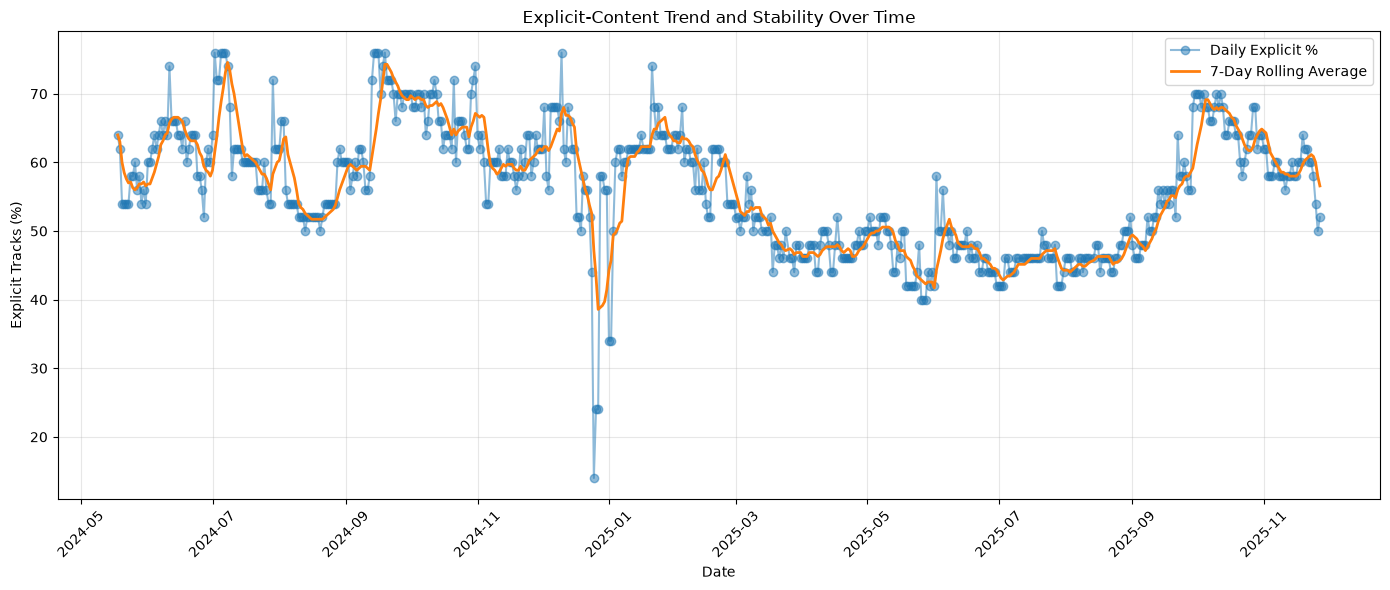

In [177]:
plt.figure(figsize=(14, 6))

plt.plot(
    daily_explicit_analysis["date"],
    daily_explicit_analysis["explicit_pct"],
    marker="o",
    alpha=0.5,
    label="Daily Explicit %"
)

plt.plot(
    daily_explicit_analysis["date"],
    daily_explicit_analysis["explicit_7day_avg"],
    linewidth=2,
    label="7-Day Rolling Average"
)

plt.title("Explicit-Content Trend and Stability Over Time")
plt.xlabel("Date")
plt.ylabel("Explicit Tracks (%)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [178]:
time_sorted = (
    daily_explicit_analysis
    .sort_values("date")
)

first_explicit = (
    time_sorted.iloc[0]["explicit_pct"]
)

last_explicit = (
    time_sorted.iloc[-1]["explicit_pct"]
)

change_pp = last_explicit - first_explicit

print(
    f"First recorded explicit percentage: "
    f"{first_explicit:.2f}%"
)

print(
    f"Last recorded explicit percentage: "
    f"{last_explicit:.2f}%"
)

print(
    f"Change: {change_pp:.2f} percentage points"
)

First recorded explicit percentage: 64.00%
Last recorded explicit percentage: 52.00%
Change: -12.00 percentage points


In [179]:
highest_period = (
    daily_explicit_analysis
    .nlargest(5, "explicit_pct")
    [
        [
            "date",
            "explicit_pct"
        ]
    ]
)

lowest_period = (
    daily_explicit_analysis
    .nsmallest(5, "explicit_pct")
    [
        [
            "date",
            "explicit_pct"
        ]
    ]
)

print("Highest explicit-content periods:")
display(highest_period)

print("Lowest explicit-content periods:")
display(lowest_period)

Highest explicit-content periods:


is_explicit,date,explicit_pct
45,2024-07-02,76.0
48,2024-07-05,76.0
49,2024-07-06,76.0
50,2024-07-07,76.0
119,2024-09-14,76.0


Lowest explicit-content periods:


is_explicit,date,explicit_pct
221,2024-12-25,14.0
222,2024-12-26,24.0
223,2024-12-27,24.0
228,2025-01-01,34.0
229,2025-01-02,34.0


In [180]:
monthly_explicit = (
    df_clean
    .assign(
        month=df_clean["date"].dt.to_period("M")
    )
    .groupby(["month", "is_explicit"])
    .size()
    .unstack(fill_value=0)
)

In [181]:
monthly_explicit_pct = (
    monthly_explicit
    .div(
        monthly_explicit.sum(axis=1),
        axis=0
    )
    * 100
)

monthly_explicit_pct.round(2)

is_explicit,False,True
month,,
2024-05,43.14,56.86
2024-06,37.33,62.67
2024-07,36.52,63.48
2024-08,44.97,55.03
2024-09,33.47,66.53
2024-10,32.97,67.03
2024-11,39.93,60.07
2024-12,43.61,56.39
2025-01,39.35,60.65


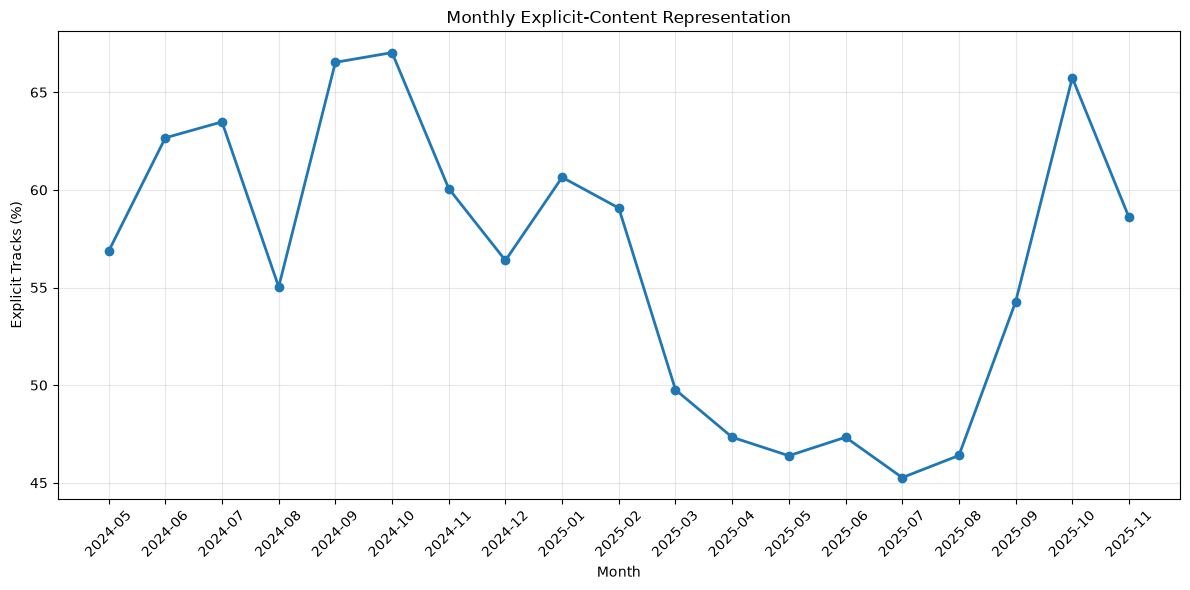

In [182]:
plt.figure(figsize=(12, 6))

if True in monthly_explicit_pct.columns:
    plt.plot(
        monthly_explicit_pct.index.astype(str),
        monthly_explicit_pct[True],
        marker="o",
        linewidth=2
    )

plt.title("Monthly Explicit-Content Representation")
plt.xlabel("Month")
plt.ylabel("Explicit Tracks (%)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [183]:
mean_explicit = (
    daily_explicit_analysis["explicit_pct"].mean()
)

std_explicit = (
    daily_explicit_analysis["explicit_pct"].std()
)

if mean_explicit != 0:
    coefficient_variation = (
        std_explicit / mean_explicit
    ) * 100
else:
    coefficient_variation = np.nan

print(
    f"Coefficient of variation: "
    f"{coefficient_variation:.2f}%"
)

Coefficient of variation: 16.10%


In [184]:
if coefficient_variation < 10:
    stability = "Relatively Stable"
elif coefficient_variation < 25:
    stability = "Moderately Variable"
else:
    stability = "Highly Variable"

print("Trend Stability:", stability)

Trend Stability: Moderately Variable


In [185]:
trend_stability_summary = pd.DataFrame({
    "Metric": [
        "Average Explicit %",
        "Median Explicit %",
        "Standard Deviation",
        "Minimum Explicit %",
        "Maximum Explicit %",
        "Range",
        "First Recorded Explicit %",
        "Last Recorded Explicit %",
        "Change in Percentage Points",
        "Coefficient of Variation",
        "Trend Stability"
    ],
    "Value": [
        trend_statistics["Average Explicit %"],
        trend_statistics["Median Explicit %"],
        trend_statistics["Standard Deviation"],
        trend_statistics["Minimum Explicit %"],
        trend_statistics["Maximum Explicit %"],
        trend_statistics["Range"],
        round(first_explicit, 2),
        round(last_explicit, 2),
        round(change_pp, 2),
        round(coefficient_variation, 2),
        stability
    ]
})

trend_stability_summary

,Metric,Value
0,Average Explicit %,56.26
1,Median Explicit %,58.0
2,Standard Deviation,9.06
3,Minimum Explicit %,14.0
4,Maximum Explicit %,76.0
5,Range,62.0
6,First Recorded Explicit %,64.0
7,Last Recorded Explicit %,52.0
8,Change in Percentage Points,-12.0
9,Coefficient of Variation,16.1


In [186]:
daily_explicit_analysis.to_csv(
    "data/saved/explicit_content_trend_stability.csv",
    index=False
)

monthly_explicit_pct.to_csv(
    "data/saved/monthly_explicit_content_trend.csv"
)

trend_stability_summary.to_csv(
    "data/saved/trend_stability_summary.csv",
    index=False
)

print("Step 5.6 completed successfully.")

Step 5.6 completed successfully.


#### Combined Content-Compliance Summary

The Content Compliance Analysis examined explicit-content representation
within the France Top 50 dataset using the available `is_explicit` field.

The analysis covered:

1. Overall explicit-content representation
2. Chart-position distribution
3. Popularity differences
4. Song-duration differences
5. Album-type patterns
6. Artist-level patterns
7. Trends and stability over time

The findings describe patterns within the dataset and should not be
interpreted as a complete legal, regulatory, cultural, or platform-policy
compliance assessment.

The `is_explicit` field provides an indicator of explicit content, but the
dataset does not provide sufficient information to evaluate every possible
content-compliance requirement.

Therefore, the results should be treated as a data-driven content-profile
analysis rather than a formal compliance certification.

In [187]:
overall_compliance = (
    df_clean
    .groupby("is_explicit")
    .agg(
        track_count=("song", "count"),
        unique_songs=("song", "nunique"),
        unique_artists=("artist", "nunique"),
        avg_popularity=("popularity", "mean"),
        median_popularity=("popularity", "median"),
        avg_chart_position=("position", "mean"),
        median_chart_position=("position", "median"),
        avg_duration_min=("duration_min", "mean"),
        median_duration_min=("duration_min", "median")
    )
    .reset_index()
)

overall_compliance["track_percentage"] = (
    overall_compliance["track_count"]
    / overall_compliance["track_count"].sum()
    * 100
)

overall_compliance = overall_compliance.round(2)

overall_compliance

,is_explicit,track_count,unique_songs,unique_artists,avg_popularity,median_popularity,avg_chart_position,median_chart_position,avg_duration_min,median_duration_min,track_percentage
0,False,12152,242,193,80.90,81.0,26.16,26.0,3.04,3.01,43.74
1,True,15629,461,150,73.33,74.0,24.99,25.0,3.13,2.99,56.26


In [188]:
chart_position_summary = (
    df_clean
    .groupby("is_explicit")
    .agg(
        avg_position=("position", "mean"),
        median_position=("position", "median"),
        best_position=("position", "min"),
        worst_position=("position", "max")
    )
    .reset_index()
    .round(2)
)

chart_position_summary

,is_explicit,avg_position,median_position,best_position,worst_position
0,False,26.16,26.0,1,50
1,True,24.99,25.0,1,50


In [189]:
popularity_summary = (
    df_clean
    .groupby("is_explicit")
    .agg(
        avg_popularity=("popularity", "mean"),
        median_popularity=("popularity", "median"),
        max_popularity=("popularity", "max")
    )
    .reset_index()
    .round(2)
)

popularity_summary

,is_explicit,avg_popularity,median_popularity,max_popularity
0,False,80.90,81.0,100
1,True,73.33,74.0,100


In [190]:
duration_compliance_summary = (
    df_clean
    .groupby("is_explicit")
    .agg(
        avg_duration_min=("duration_min", "mean"),
        median_duration_min=("duration_min", "median"),
        shortest_duration_min=("duration_min", "min"),
        longest_duration_min=("duration_min", "max")
    )
    .reset_index()
    .round(2)
)

duration_compliance_summary

,is_explicit,avg_duration_min,median_duration_min,shortest_duration_min,longest_duration_min
0,False,3.04,3.01,0.00,5.96
1,True,3.13,2.99,0.67,9.12


In [191]:
album_compliance_summary = (
    df_clean
    .groupby(["album_type", "is_explicit"])
    .agg(
        track_count=("song", "count"),
        avg_popularity=("popularity", "mean"),
        avg_duration_min=("duration_min", "mean")
    )
    .reset_index()
    .round(2)
)

album_compliance_summary

,album_type,is_explicit,track_count,avg_popularity,avg_duration_min
0,album,False,4051,77.01,3.19
1,album,True,10635,71.45,3.15
2,compilation,False,9,79.33,2.91
3,single,False,8092,82.85,2.97
4,single,True,4994,77.33,3.09


In [192]:
artist_compliance_summary = (
    artist_compliance_overall
    .reset_index()
    .sort_values(
        "explicit_pct",
        ascending=False
    )
)

artist_compliance_summary.head(20).round(2)

,artist,total_records,unique_songs,avg_popularity,avg_position,avg_duration_min,explicit_pct,non_explicit_pct
0,AMK,84,1,62.68,19.86,3.20,100.0,0.0
1,Amy Winehouse,10,1,83.20,44.60,4.02,100.0,0.0
2,Damso,94,16,64.44,21.90,3.08,100.0,0.0
3,Dave & Central Cee,68,1,95.06,39.06,3.82,100.0,0.0
4,Dau,48,1,74.15,24.73,3.00,100.0,0.0
5,Dasha,47,1,91.06,41.11,2.86,100.0,0.0
6,DA Uzi,79,1,71.05,25.13,3.72,100.0,0.0
7,Burna Boy,16,1,83.38,46.38,2.56,100.0,0.0
8,Central Cee,16,1,73.12,42.06,2.85,100.0,0.0
9,Booba,308,10,68.56,30.74,2.94,100.0,0.0


In [193]:
time_compliance_summary = pd.DataFrame({
    "Metric": [
        "Average Daily Explicit %",
        "Median Daily Explicit %",
        "Minimum Daily Explicit %",
        "Maximum Daily Explicit %",
        "First Recorded Explicit %",
        "Last Recorded Explicit %",
        "Change in Percentage Points",
        "Coefficient of Variation",
        "Trend Stability"
    ],
    "Value": [
        trend_statistics["Average Explicit %"],
        trend_statistics["Median Explicit %"],
        trend_statistics["Minimum Explicit %"],
        trend_statistics["Maximum Explicit %"],
        round(first_explicit, 2),
        round(last_explicit, 2),
        round(change_pp, 2),
        round(coefficient_variation, 2),
        stability
    ]
})

time_compliance_summary

,Metric,Value
0,Average Daily Explicit %,56.26
1,Median Daily Explicit %,58.0
2,Minimum Daily Explicit %,14.0
3,Maximum Daily Explicit %,76.0
4,First Recorded Explicit %,64.0
5,Last Recorded Explicit %,52.0
6,Change in Percentage Points,-12.0
7,Coefficient of Variation,16.1
8,Trend Stability,Moderately Variable


In [194]:
master_compliance_findings = pd.DataFrame({
    "Analysis Area": [
        "Overall Content Profile",
        "Chart Position",
        "Popularity",
        "Song Duration",
        "Album Type",
        "Artist Level",
        "Time Trend"
    ],

    "Primary Metric": [
        "Explicit-content percentage",
        "Average and median chart position",
        "Average and median popularity",
        "Average and median duration",
        "Explicit distribution by album type",
        "Explicit percentage by eligible artist",
        "Daily explicit-content percentage"
    ],

    "Purpose": [
        "Measure overall explicit-content representation",
        "Compare explicit representation across rankings",
        "Compare explicit representation across popularity levels",
        "Compare duration patterns",
        "Identify album-type differences",
        "Identify artist-level differences",
        "Measure change and stability over time"
    ]
})

master_compliance_findings

,Analysis Area,Primary Metric,Purpose
0,Overall Content Profile,Explicit-content percentage,Measure overall explicit-content representation
1,Chart Position,Average and median chart position,Compare explicit representation across rankings
2,Popularity,Average and median popularity,Compare explicit representation across popular...
3,Song Duration,Average and median duration,Compare duration patterns
4,Album Type,Explicit distribution by album type,Identify album-type differences
5,Artist Level,Explicit percentage by eligible artist,Identify artist-level differences
6,Time Trend,Daily explicit-content percentage,Measure change and stability over time


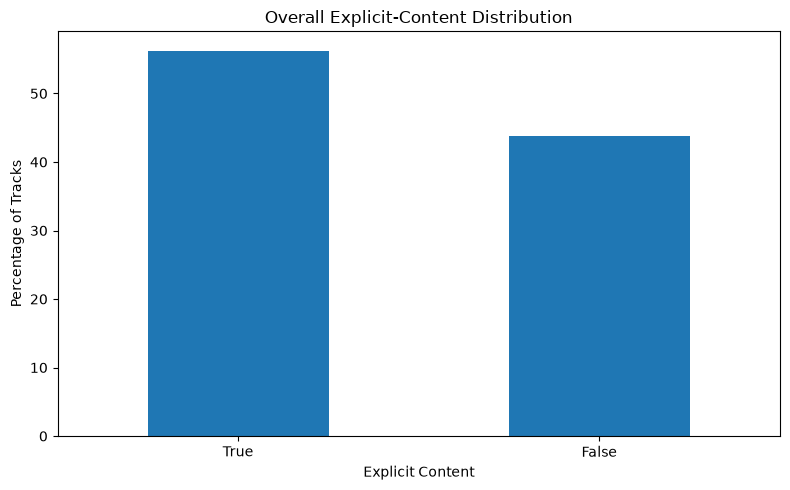

In [195]:
# Overall explicit-content distribution

overall_percentage = (
    df_clean["is_explicit"]
    .value_counts(normalize=True)
    .mul(100)
)

plt.figure(figsize=(8, 5))

overall_percentage.plot(
    kind="bar"
)

plt.title("Overall Explicit-Content Distribution")
plt.xlabel("Explicit Content")
plt.ylabel("Percentage of Tracks")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

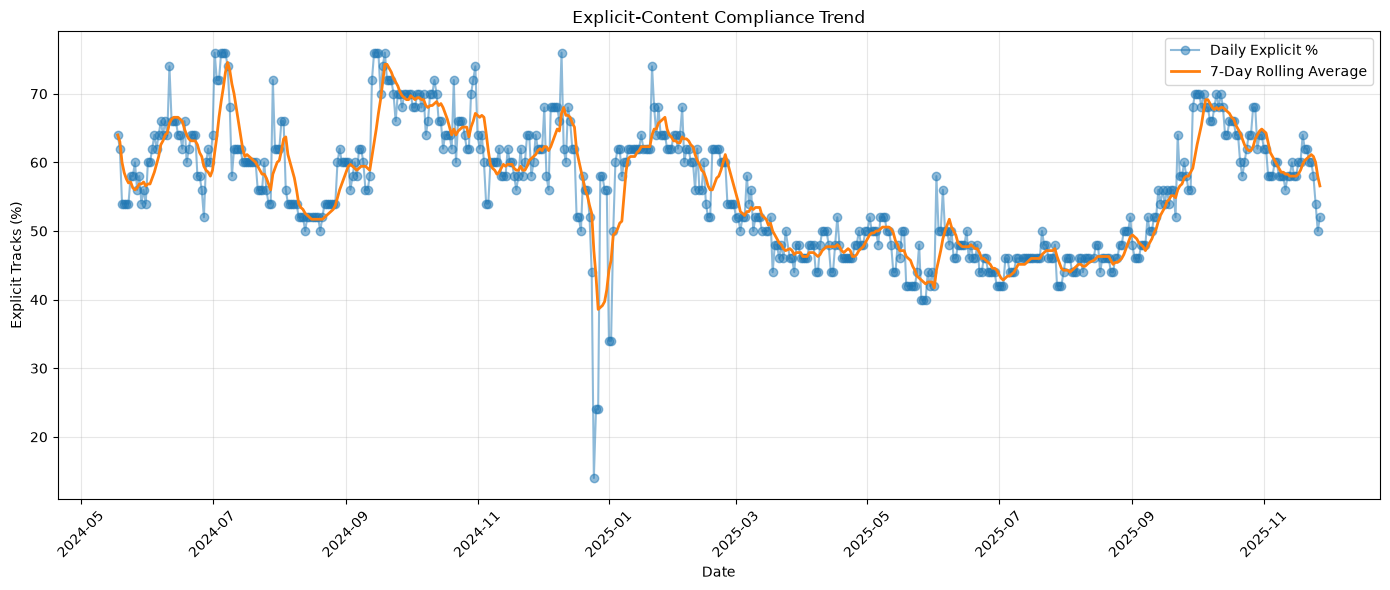

In [196]:
plt.figure(figsize=(14, 6))

plt.plot(
    daily_explicit_analysis["date"],
    daily_explicit_analysis["explicit_pct"],
    marker="o",
    alpha=0.5,
    label="Daily Explicit %"
)

plt.plot(
    daily_explicit_analysis["date"],
    daily_explicit_analysis["explicit_7day_avg"],
    linewidth=2,
    label="7-Day Rolling Average"
)

plt.title("Explicit-Content Compliance Trend")
plt.xlabel("Date")
plt.ylabel("Explicit Tracks (%)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [197]:
overall_compliance.to_csv(
    "data/saved/final_overall_compliance.csv",
    index=False
)

chart_position_summary.to_csv(
    "data/saved/compliance_chart_position_summary.csv",
    index=False
)

popularity_summary.to_csv(
    "data/saved/compliance_popularity_summary.csv",
    index=False
)

duration_compliance_summary.to_csv(
    "data/saved/compliance_duration_summary.csv",
    index=False
)

album_compliance_summary.to_csv(
    "data/saved/compliance_album_summary.csv",
    index=False
)

artist_compliance_summary.to_csv(
    "data/saved/compliance_artist_summary.csv",
    index=False
)

time_compliance_summary.to_csv(
    "data/saved/compliance_time_summary.csv",
    index=False
)

master_compliance_findings.to_csv(
    "data/saved/master_content_compliance_findings.csv",
    index=False
)

print("Step 5 — Content Compliance Analysis completed successfully.")

Step 5 — Content Compliance Analysis completed successfully.


#### Step 6 — Format Preference Analysis

In [198]:
duration_profile = (
    df_clean["duration_min"]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
    .round(2)
)

duration_profile

count     27781.00
mean          3.09
median        3.00
std           0.54
min           0.00
max           9.12
Name: duration_min, dtype: float64

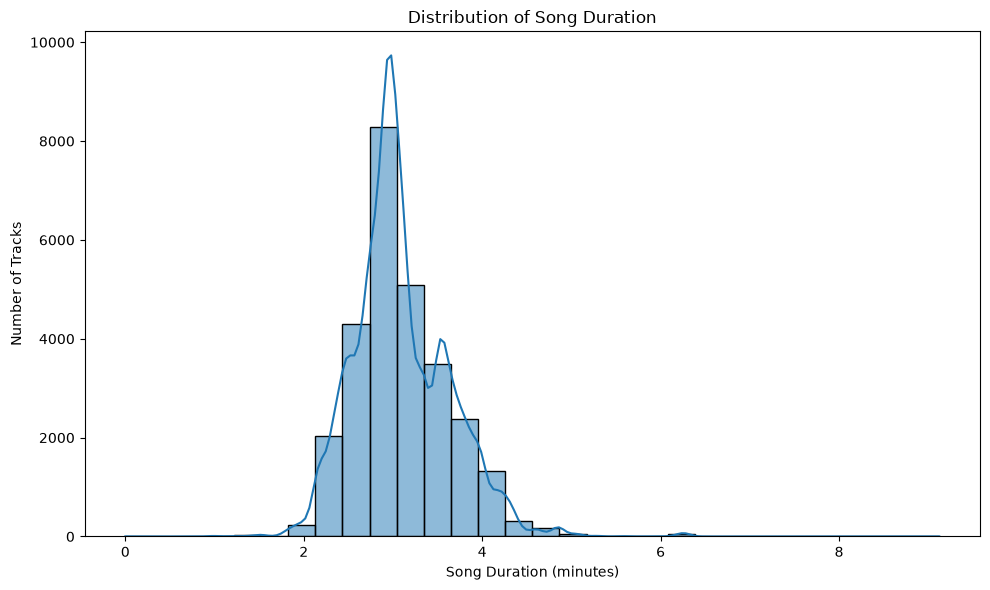

In [199]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_clean,
    x="duration_min",
    bins=30,
    kde=True
)

plt.title("Distribution of Song Duration")
plt.xlabel("Song Duration (minutes)")
plt.ylabel("Number of Tracks")
plt.tight_layout()
plt.show()

In [200]:
df_clean["duration_group"] = pd.cut(
    df_clean["duration_min"],
    bins=[0, 2, 3, 4, 5, float("inf")],
    labels=[
        "Under 2 min",
        "2–3 min",
        "3–4 min",
        "4–5 min",
        "5+ min"
    ],
    right=False
)

In [201]:
duration_distribution = (
    df_clean["duration_group"]
    .value_counts()
    .sort_index()
)

duration_distribution

duration_group
Under 2 min      180
2–3 min        13682
3–4 min        12418
4–5 min         1412
5+ min            89
Name: count, dtype: int64

In [202]:
duration_percentage = (
    df_clean["duration_group"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

duration_percentage

duration_group
Under 2 min     0.65
2–3 min        49.25
3–4 min        44.70
4–5 min         5.08
5+ min          0.32
Name: proportion, dtype: float64

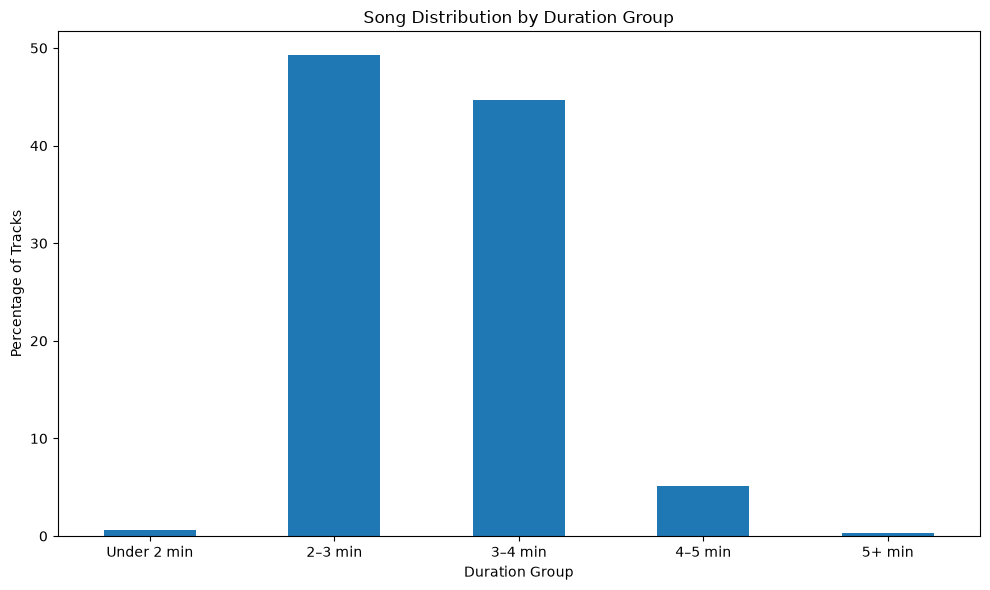

In [203]:
duration_percentage.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Song Distribution by Duration Group")
plt.xlabel("Duration Group")
plt.ylabel("Percentage of Tracks")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [204]:
most_common_duration = (
    duration_percentage
    .idxmax()
)

most_common_percentage = (
    duration_percentage
    .max()
)

print(
    f"Most common duration group: "
    f"{most_common_duration}"
)

print(
    f"Percentage of tracks: "
    f"{most_common_percentage:.2f}%"
)

Most common duration group: 2–3 min
Percentage of tracks: 49.25%


In [205]:
shortest_tracks = (
    df_clean
    .nsmallest(10, "duration_min")
    [
        [
            "song",
            "artist",
            "duration_min",
            "position",
            "popularity"
        ]
    ]
)

longest_tracks = (
    df_clean
    .nlargest(10, "duration_min")
    [
        [
            "song",
            "artist",
            "duration_min",
            "position",
            "popularity"
        ]
    ]
)

print("Shortest tracks:")
display(shortest_tracks)

print("Longest tracks:")
display(longest_tracks)

Shortest tracks:


,song,artist,duration_min,position,popularity
13001,Unknown Song,Lavern,0.000000,2,0
12442,Interlude *,PLK,0.667333,43,56
6469,Rolls Royce,Werenoi,0.985483,20,39
6519,Rolls Royce,Werenoi,0.985483,20,58
6569,Rolls Royce,Werenoi,0.985483,20,61
6616,Rolls Royce,Werenoi,0.985483,17,64
6673,Rolls Royce,Werenoi,0.985483,24,64
6723,Rolls Royce,Werenoi,0.985483,24,66
8229,Cotton Club Freestyle - Remix,Josman,1.180217,30,0
8288,Cotton Club Freestyle - Remix,Josman,1.180217,39,41


Longest tracks:


,song,artist,duration_min,position,popularity
194,BIG Brother,Luv Resval,9.123550,45,54
23795,Sous le soleil,Jul & 13 Organisé & L'Algérino,8.002667,46,53
22653,Bande organisée 2,Jul & 13 Organisé & Alonzo,6.274883,4,51
22707,Bande organisée 2,Jul & 13 Organisé & Alonzo,6.274883,8,60
22757,Bande organisée 2,Jul & 13 Organisé & Alonzo,6.274883,8,63
22810,Bande organisée 2,Jul & 13 Organisé & Alonzo,6.274883,11,64
22860,Bande organisée 2,Jul & 13 Organisé & Alonzo,6.274883,11,66
22912,Bande organisée 2,Jul & 13 Organisé & Alonzo,6.274883,13,67
22964,Bande organisée 2,Jul & 13 Organisé & Alonzo,6.274883,15,68
23013,Bande organisée 2,Jul & 13 Organisé & Alonzo,6.274883,14,68


In [206]:
duration_chart = (
    df_clean
    .groupby("duration_group", observed=True)
    .agg(
        track_count=("song", "count"),
        avg_position=("position", "mean"),
        median_position=("position", "median"),
        avg_popularity=("popularity", "mean"),
        median_popularity=("popularity", "median")
    )
    .round(2)
)

duration_chart

,track_count,avg_position,median_position,avg_popularity,median_popularity
duration_group,,,,,
Under 2 min,180,27.11,29.0,76.09,76.0
2–3 min,13682,25.61,26.0,75.56,75.0
3–4 min,12418,24.89,25.0,77.71,76.0
4–5 min,1412,29.25,32.0,78.21,76.0
5+ min,89,32.17,34.0,71.18,71.0


In [207]:
duration_profile.to_csv(
    "data/saved/format_duration_profile.csv"
)

duration_percentage.to_csv(
    "data/saved/format_duration_distribution.csv"
)

duration_chart.to_csv(
    "data/saved/format_duration_chart_analysis.csv"
)

print("Step 6.1 completed successfully.")

Step 6.1 completed successfully.


#### Album-Type Distribution

In [208]:
album_type_distribution = (
    df_clean["album_type"]
    .value_counts(dropna=False)
)

album_type_distribution

album_type
album          14686
single         13086
compilation        9
Name: count, dtype: int64

In [209]:
album_type_percentage = (
    df_clean["album_type"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)

album_type_percentage

album_type
album          52.86
single         47.10
compilation     0.03
Name: proportion, dtype: float64

In [210]:
album_type_summary = pd.DataFrame({
    "track_count": album_type_distribution,
    "percentage": album_type_percentage
})

album_type_summary

,track_count,percentage
album_type,,
album,14686,52.86
single,13086,47.10
compilation,9,0.03


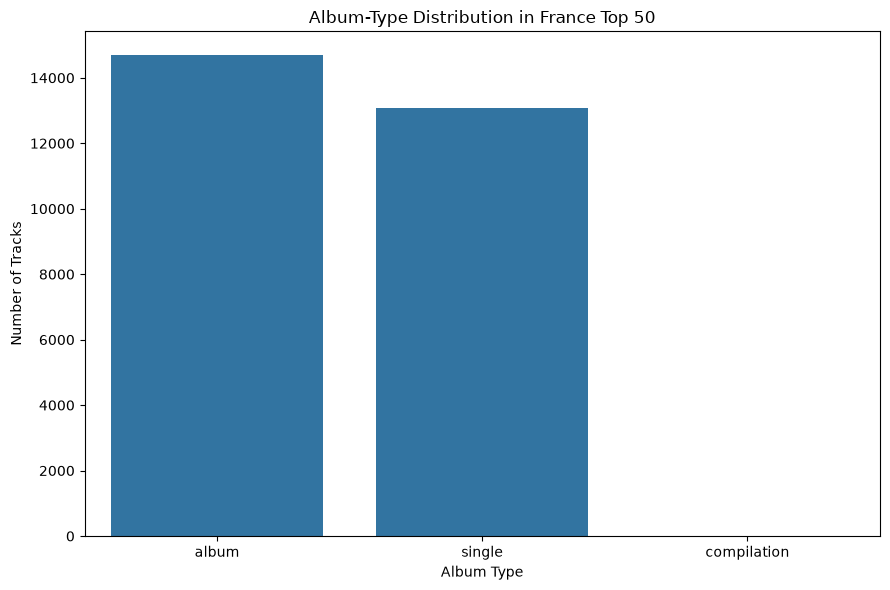

In [211]:
plt.figure(figsize=(9, 6))

sns.countplot(
    data=df_clean,
    x="album_type",
    order=df_clean["album_type"].value_counts().index
)

plt.title("Album-Type Distribution in France Top 50")
plt.xlabel("Album Type")
plt.ylabel("Number of Tracks")
plt.tight_layout()
plt.show()

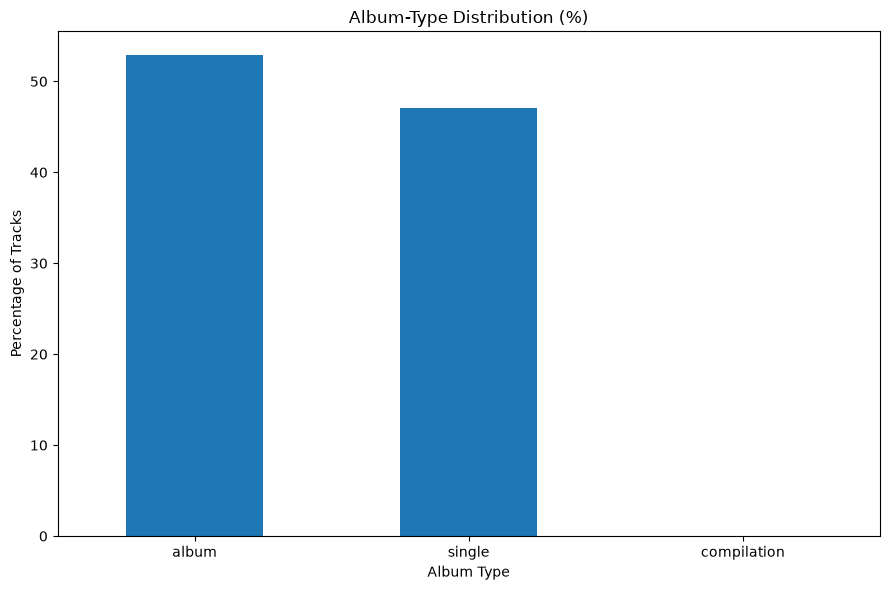

In [212]:
album_type_percentage.plot(
    kind="bar",
    figsize=(9, 6)
)

plt.title("Album-Type Distribution (%)")
plt.xlabel("Album Type")
plt.ylabel("Percentage of Tracks")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [213]:
album_type_chart = (
    df_clean
    .groupby("album_type")
    .agg(
        track_count=("song", "count"),
        avg_position=("position", "mean"),
        median_position=("position", "median"),
        best_position=("position", "min"),
        avg_popularity=("popularity", "mean"),
        median_popularity=("popularity", "median")
    )
    .round(2)
)

album_type_chart

,track_count,avg_position,median_position,best_position,avg_popularity,median_popularity
album_type,,,,,,
album,14686,26.73,28.0,1,72.99,73.0
compilation,9,28.67,30.0,14,79.33,75.0
single,13086,24.13,24.0,1,80.74,78.0


In [214]:
album_type_duration = (
    df_clean
    .groupby("album_type")
    .agg(
        avg_duration_min=("duration_min", "mean"),
        median_duration_min=("duration_min", "median"),
        shortest_duration_min=("duration_min", "min"),
        longest_duration_min=("duration_min", "max")
    )
    .round(2)
)

album_type_duration

,avg_duration_min,median_duration_min,shortest_duration_min,longest_duration_min
album_type,,,,
album,3.16,3.04,0.67,9.12
compilation,2.91,3.28,1.92,4.00
single,3.02,2.97,0.00,8.00


In [215]:
album_type_explicit = (
    pd.crosstab(
        df_clean["album_type"],
        df_clean["is_explicit"],
        normalize="index"
    ) * 100
)

album_type_explicit.round(2)

is_explicit,False,True
album_type,,
album,27.58,72.42
compilation,100.00,0.00
single,61.84,38.16


In [216]:
dominant_album_type = (
    album_type_percentage
    .idxmax()
)

dominant_album_percentage = (
    album_type_percentage
    .max()
)

print(
    f"Most common album type: {dominant_album_type}"
)

print(
    f"Percentage of tracks: {dominant_album_percentage:.2f}%"
)

Most common album type: album
Percentage of tracks: 52.86%


In [217]:
album_format_analysis = (
    album_type_summary
    .join(album_type_chart.drop(columns="track_count"), how="left")
    .join(album_type_duration, how="left")
)

album_format_analysis

,track_count,percentage,avg_position,median_position,best_position,avg_popularity,median_popularity,avg_duration_min,median_duration_min,shortest_duration_min,longest_duration_min
album_type,,,,,,,,,,,
album,14686,52.86,26.73,28.0,1,72.99,73.0,3.16,3.04,0.67,9.12
single,13086,47.10,24.13,24.0,1,80.74,78.0,3.02,2.97,0.00,8.00
compilation,9,0.03,28.67,30.0,14,79.33,75.0,2.91,3.28,1.92,4.00


In [218]:
album_type_summary.to_csv(
    "data/saved/album_type_distribution.csv"
)

album_type_chart.to_csv(
    "data/saved/album_type_chart_analysis.csv"
)

album_type_duration.to_csv(
    "data/saved/album_type_duration_analysis.csv"
)

album_type_explicit.to_csv(
    "data/saved/album_type_explicit_analysis.csv"
)

album_format_analysis.to_csv(
    "data/saved/album_format_analysis.csv"
)

print("Step 6.2 completed successfully.")

Step 6.2 completed successfully.


#### Duration by Album Type

In [219]:
duration_by_album = (
    df_clean
    .groupby("album_type")
    .agg(
        track_count=("song", "count"),
        average_duration_min=("duration_min", "mean"),
        median_duration_min=("duration_min", "median"),
        minimum_duration_min=("duration_min", "min"),
        maximum_duration_min=("duration_min", "max"),
        std_duration_min=("duration_min", "std")
    )
    .round(2)
)

duration_by_album

,track_count,average_duration_min,median_duration_min,minimum_duration_min,maximum_duration_min,std_duration_min
album_type,,,,,,
album,14686,3.16,3.04,0.67,9.12,0.55
compilation,9,2.91,3.28,1.92,4.00,0.85
single,13086,3.02,2.97,0.00,8.00,0.52


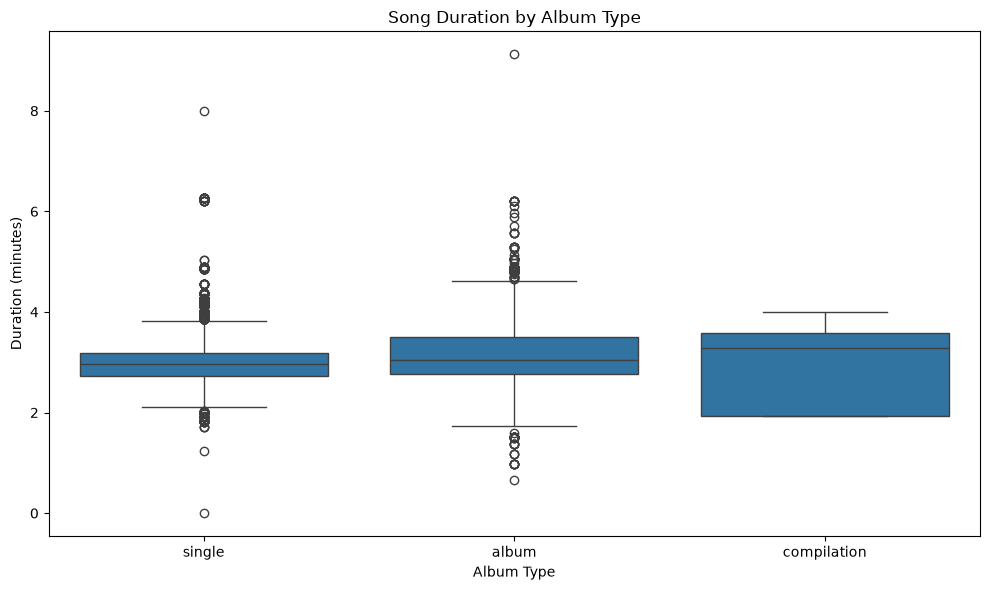

In [220]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_clean,
    x="album_type",
    y="duration_min"
)

plt.title("Song Duration by Album Type")
plt.xlabel("Album Type")
plt.ylabel("Duration (minutes)")
plt.tight_layout()
plt.show()

In [221]:
average_duration_by_album = (
    df_clean
    .groupby("album_type")["duration_min"]
    .mean()
    .sort_values(ascending=False)
    .round(2)
)

average_duration_by_album

album_type
album          3.16
single         3.02
compilation    2.91
Name: duration_min, dtype: float64

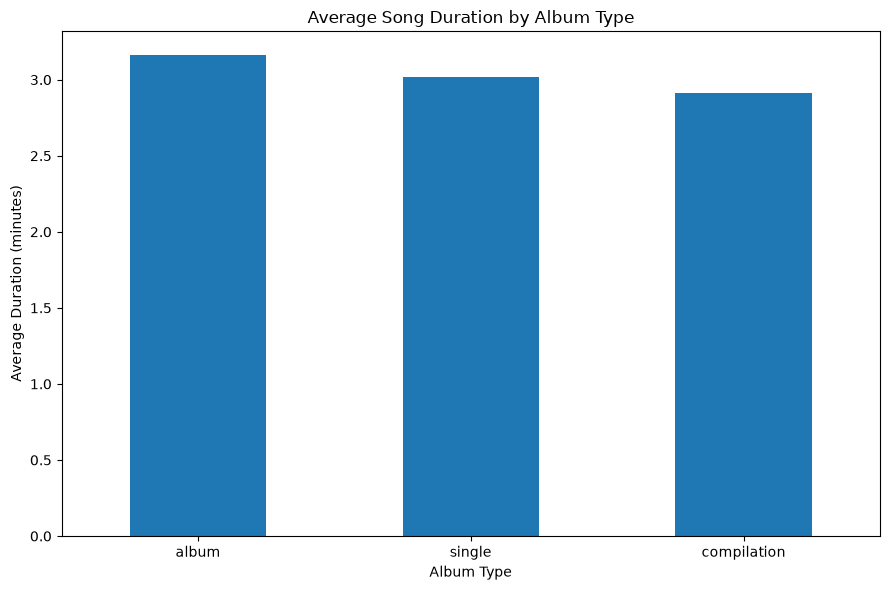

In [222]:
average_duration_by_album.plot(
    kind="bar",
    figsize=(9, 6)
)

plt.title("Average Song Duration by Album Type")
plt.xlabel("Album Type")
plt.ylabel("Average Duration (minutes)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [223]:
album_duration_groups = (
    pd.crosstab(
        df_clean["album_type"],
        df_clean["duration_group"],
        normalize="index"
    ) * 100
)

album_duration_groups.round(2)

duration_group,Under 2 min,2–3 min,3–4 min,4–5 min,5+ min
album_type,,,,,
album,0.60,44.71,47.93,6.41,0.35
compilation,33.33,11.11,55.56,0.00,0.00
single,0.68,54.37,41.07,3.59,0.29


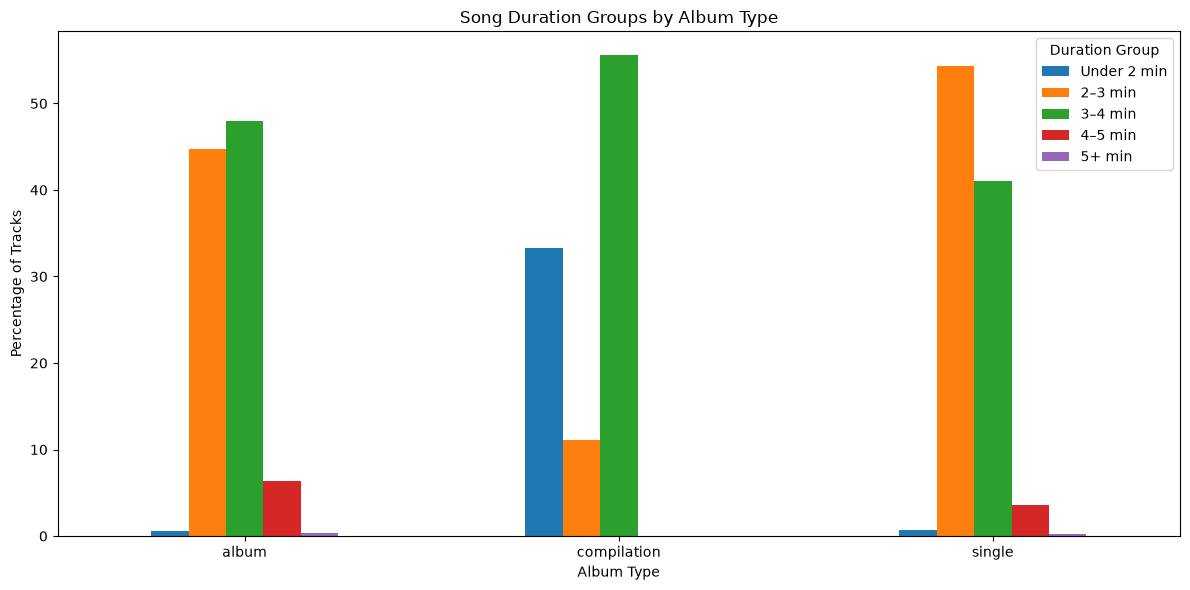

In [224]:
album_duration_groups.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Song Duration Groups by Album Type")
plt.xlabel("Album Type")
plt.ylabel("Percentage of Tracks")
plt.xticks(rotation=0)
plt.legend(title="Duration Group")
plt.tight_layout()
plt.show()

In [225]:
album_duration_chart = (
    df_clean
    .groupby("album_type")
    .agg(
        avg_duration_min=("duration_min", "mean"),
        median_duration_min=("duration_min", "median"),
        avg_position=("position", "mean"),
        median_position=("position", "median"),
        avg_popularity=("popularity", "mean"),
        median_popularity=("popularity", "median")
    )
    .round(2)
)

album_duration_chart

,avg_duration_min,median_duration_min,avg_position,median_position,avg_popularity,median_popularity
album_type,,,,,,
album,3.16,3.04,26.73,28.0,72.99,73.0
compilation,2.91,3.28,28.67,30.0,79.33,75.0
single,3.02,2.97,24.13,24.0,80.74,78.0


In [226]:
longest_average_album_type = (
    average_duration_by_album.idxmax()
)

longest_average_duration = (
    average_duration_by_album.max()
)

print(
    f"Album type with longest average duration: "
    f"{longest_average_album_type}"
)

print(
    f"Average duration: "
    f"{longest_average_duration:.2f} minutes"
)

Album type with longest average duration: album
Average duration: 3.16 minutes


In [227]:
shortest_average_album_type = (
    average_duration_by_album.idxmin()
)

shortest_average_duration = (
    average_duration_by_album.min()
)

print(
    f"Album type with shortest average duration: "
    f"{shortest_average_album_type}"
)

print(
    f"Average duration: "
    f"{shortest_average_duration:.2f} minutes"
)

Album type with shortest average duration: compilation
Average duration: 2.91 minutes


In [228]:
duration_album_analysis = (
    duration_by_album
    .join(
        album_duration_chart[
            [
                "avg_position",
                "median_position",
                "avg_popularity",
                "median_popularity"
            ]
        ]
    )
)

duration_album_analysis

,track_count,average_duration_min,median_duration_min,minimum_duration_min,maximum_duration_min,std_duration_min,avg_position,median_position,avg_popularity,median_popularity
album_type,,,,,,,,,,
album,14686,3.16,3.04,0.67,9.12,0.55,26.73,28.0,72.99,73.0
compilation,9,2.91,3.28,1.92,4.00,0.85,28.67,30.0,79.33,75.0
single,13086,3.02,2.97,0.00,8.00,0.52,24.13,24.0,80.74,78.0


In [229]:
duration_by_album.to_csv(
    "data/saved/duration_by_album_type.csv"
)

album_duration_groups.to_csv(
    "data/saved/duration_groups_by_album_type.csv"
)

duration_album_analysis.to_csv(
    "data/saved/duration_album_complete_analysis.csv"
)

print("Step 6.3 completed successfully.")

Step 6.3 completed successfully.


#### Format Patterns by Chart Position

In [230]:
df_clean["chart_position_group"] = pd.cut(
    df_clean["position"],
    bins=[0, 10, 25, 50],
    labels=[
        "Top 10",
        "Positions 11-25",
        "Positions 26-50"
    ],
    include_lowest=True
)

print(
    df_clean["chart_position_group"]
    .value_counts()
    .sort_index()
)

chart_position_group
Top 10              5554
Positions 11-25     8334
Positions 26-50    13893
Name: count, dtype: int64


In [231]:
duration_by_position = (
    df_clean
    .groupby("chart_position_group", observed=True)
    .agg(
        track_count=("song", "count"),
        avg_duration_min=("duration_min", "mean"),
        median_duration_min=("duration_min", "median"),
        min_duration_min=("duration_min", "min"),
        max_duration_min=("duration_min", "max"),
        avg_popularity=("popularity", "mean")
    )
    .round(2)
)

duration_by_position

,track_count,avg_duration_min,median_duration_min,min_duration_min,max_duration_min,avg_popularity
chart_position_group,,,,,,
Top 10,5554,3.09,3.01,0.00,6.27,78.27
Positions 11-25,8334,3.08,2.99,0.99,6.27,77.76
Positions 26-50,13893,3.10,2.99,0.67,9.12,75.32


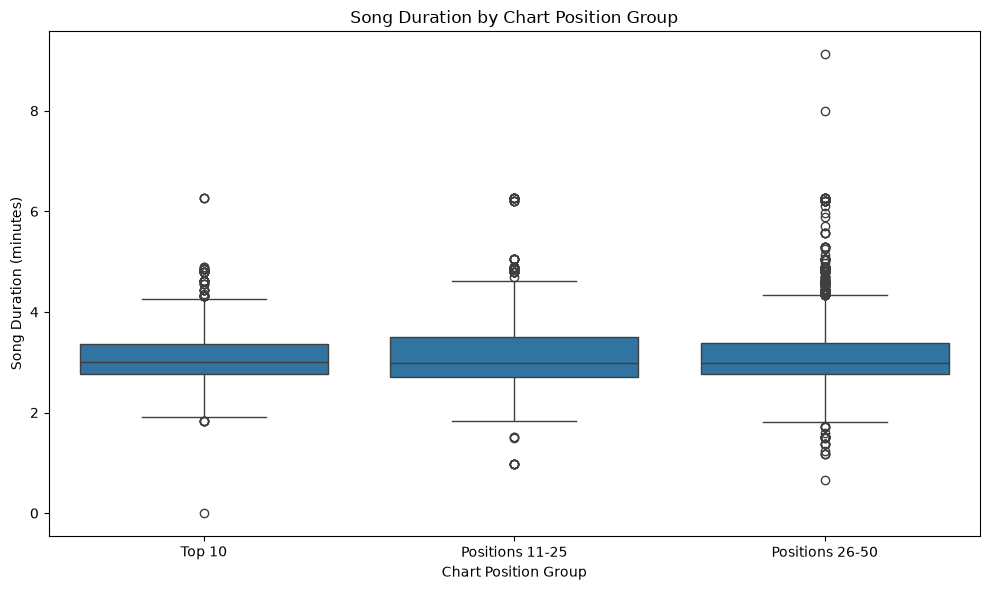

In [232]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_clean,
    x="chart_position_group",
    y="duration_min",
    order=[
        "Top 10",
        "Positions 11-25",
        "Positions 26-50"
    ]
)

plt.title("Song Duration by Chart Position Group")
plt.xlabel("Chart Position Group")
plt.ylabel("Song Duration (minutes)")
plt.tight_layout()
plt.show()

In [233]:
album_by_position = (
    pd.crosstab(
        df_clean["chart_position_group"],
        df_clean["album_type"]
    )
)

album_by_position

album_type,album,compilation,single
chart_position_group,,,
Top 10,2736,0,2818
Positions 11-25,4069,4,4261
Positions 26-50,7881,5,6007


In [234]:
album_by_position_pct = (
    pd.crosstab(
        df_clean["chart_position_group"],
        df_clean["album_type"],
        normalize="index"
    ) * 100
).round(2)

album_by_position_pct

album_type,album,compilation,single
chart_position_group,,,
Top 10,49.26,0.00,50.74
Positions 11-25,48.82,0.05,51.13
Positions 26-50,56.73,0.04,43.24


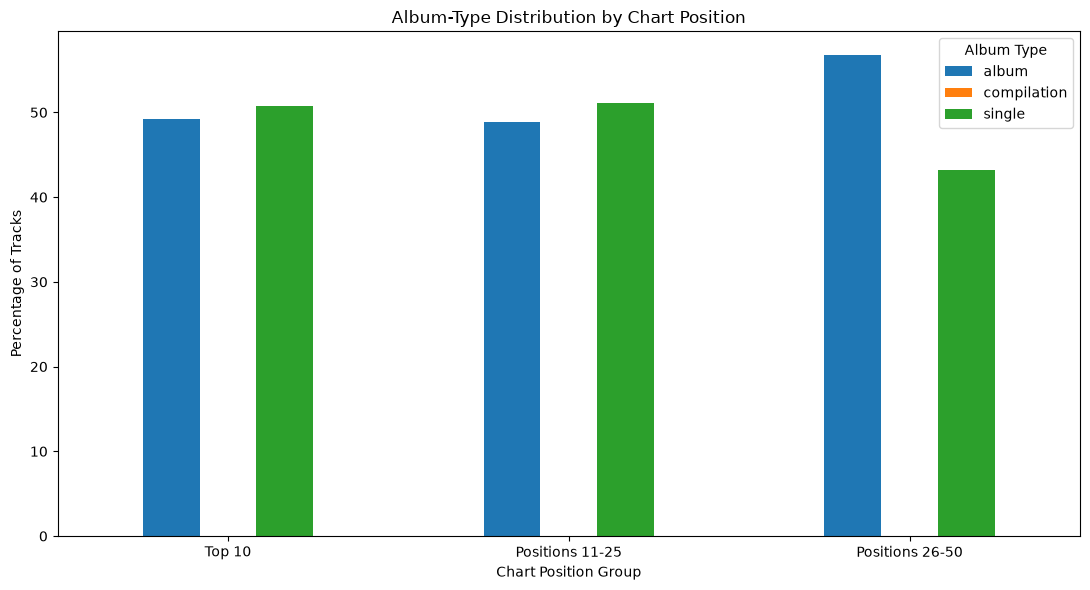

In [235]:
album_by_position_pct.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Album-Type Distribution by Chart Position")
plt.xlabel("Chart Position Group")
plt.ylabel("Percentage of Tracks")
plt.xticks(rotation=0)
plt.legend(title="Album Type")
plt.tight_layout()
plt.show()

In [236]:
df_clean["duration_group"] = pd.cut(
    df_clean["duration_min"],
    bins=[0, 2, 3, 4, 5, float("inf")],
    labels=[
        "Under 2 min",
        "2–3 min",
        "3–4 min",
        "4–5 min",
        "5+ min"
    ],
    right=False
)

In [237]:
duration_group_by_position = (
    pd.crosstab(
        df_clean["chart_position_group"],
        df_clean["duration_group"],
        normalize="index"
    ) * 100
).round(2)

duration_group_by_position

duration_group,Under 2 min,2–3 min,3–4 min,4–5 min,5+ min
chart_position_group,,,,,
Top 10,0.52,47.12,48.67,3.64,0.05
Positions 11-25,0.68,50.49,44.35,4.16,0.31
Positions 26-50,0.68,49.36,43.32,6.21,0.43


In [238]:
position_popularity_summary = (
    df_clean
    .groupby("chart_position_group", observed=True)
    .agg(
        avg_position=("position", "mean"),
        median_position=("position", "median"),
        avg_popularity=("popularity", "mean"),
        median_popularity=("popularity", "median"),
        track_count=("song", "count")
    )
    .round(2)
)

position_popularity_summary

,avg_position,median_position,avg_popularity,median_popularity,track_count
chart_position_group,,,,,
Top 10,5.5,5.5,78.27,78.0,5554
Positions 11-25,18.0,18.0,77.76,76.0,8334
Positions 26-50,38.0,38.0,75.32,74.0,13893


In [239]:
format_position_summary = (
    duration_by_position
    .join(
        position_popularity_summary[
            [
                "avg_position",
                "median_position",
                "median_popularity"
            ]
        ]
    )
)

format_position_summary

,track_count,avg_duration_min,median_duration_min,min_duration_min,max_duration_min,avg_popularity,avg_position,median_position,median_popularity
chart_position_group,,,,,,,,,
Top 10,5554,3.09,3.01,0.00,6.27,78.27,5.5,5.5,78.0
Positions 11-25,8334,3.08,2.99,0.99,6.27,77.76,18.0,18.0,76.0
Positions 26-50,13893,3.10,2.99,0.67,9.12,75.32,38.0,38.0,74.0


In [240]:
duration_by_position.to_csv(
    "data/saved/duration_by_chart_position.csv"
)

album_by_position.to_csv(
    "data/saved/album_type_by_chart_position.csv"
)

album_by_position_pct.to_csv(
    "data/saved/album_type_by_chart_position_percentage.csv"
)

duration_group_by_position.to_csv(
    "data/saved/duration_groups_by_chart_position.csv"
)

format_position_summary.to_csv(
    "data/saved/format_position_summary.csv"
)

print("Step 6.4 completed successfully.")

Step 6.4 completed successfully.


#### Format Patterns by Popularity

In [241]:
df_clean["popularity_group"] = pd.cut(
    df_clean["popularity"],
    bins=[-1, 25, 50, 75, 100],
    labels=[
        "0–25",
        "26–50",
        "51–75",
        "76–100"
    ],
    include_lowest=True
)

popularity_distribution = (
    df_clean["popularity_group"]
    .value_counts(sort=False)
    .rename_axis("popularity_group")
    .reset_index(name="track_count")
)

popularity_distribution

,popularity_group,track_count
0,0–25,108
1,26–50,360
2,51–75,13930
3,76–100,13383


In [242]:
duration_by_popularity = (
    df_clean
    .groupby("popularity_group", observed=True)
    .agg(
        track_count=("song", "count"),
        avg_duration_min=("duration_min", "mean"),
        median_duration_min=("duration_min", "median"),
        min_duration_min=("duration_min", "min"),
        max_duration_min=("duration_min", "max"),
        avg_chart_position=("position", "mean")
    )
    .round(2)
)

duration_by_popularity

,track_count,avg_duration_min,median_duration_min,min_duration_min,max_duration_min,avg_chart_position
popularity_group,,,,,,
0–25,108,3.16,3.15,0.00,6.11,25.19
26–50,360,2.96,2.88,0.99,5.14,28.78
51–75,13930,3.06,2.97,0.67,9.12,28.82
76–100,13383,3.13,3.05,1.83,5.57,21.97


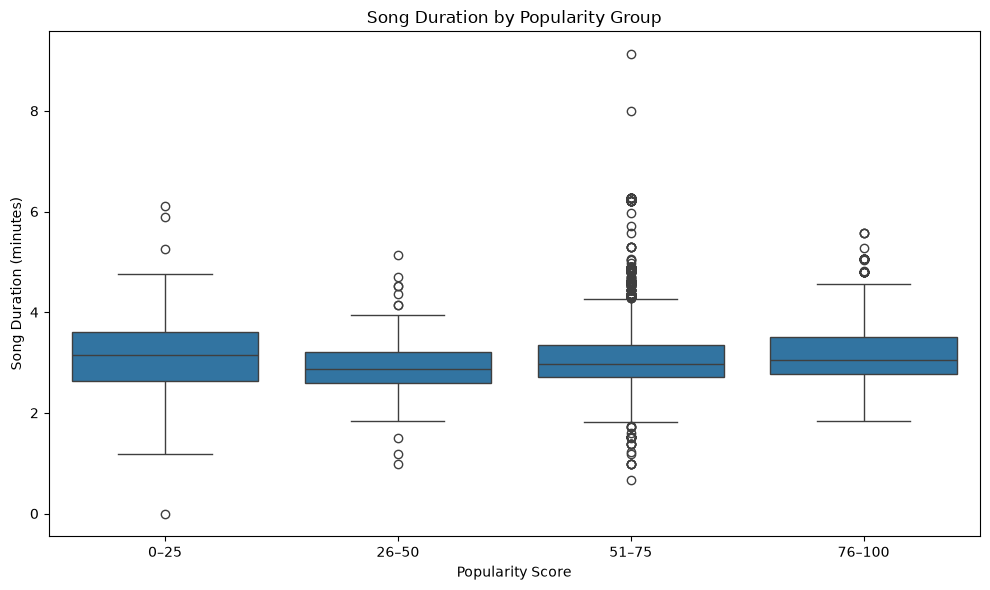

In [243]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_clean,
    x="popularity_group",
    y="duration_min",
    order=["0–25", "26–50", "51–75", "76–100"]
)

plt.title("Song Duration by Popularity Group")
plt.xlabel("Popularity Score")
plt.ylabel("Song Duration (minutes)")
plt.tight_layout()
plt.show()

In [244]:
album_by_popularity = pd.crosstab(
    df_clean["popularity_group"],
    df_clean["album_type"]
)

album_by_popularity

album_type,album,compilation,single
popularity_group,,,
0–25,94,0,14
26–50,308,0,52
51–75,9258,5,4667
76–100,5026,4,8353


In [245]:
album_by_popularity_pct = (
    pd.crosstab(
        df_clean["popularity_group"],
        df_clean["album_type"],
        normalize="index"
    ) * 100
).round(2)

album_by_popularity_pct

album_type,album,compilation,single
popularity_group,,,
0–25,87.04,0.00,12.96
26–50,85.56,0.00,14.44
51–75,66.46,0.04,33.50
76–100,37.56,0.03,62.42


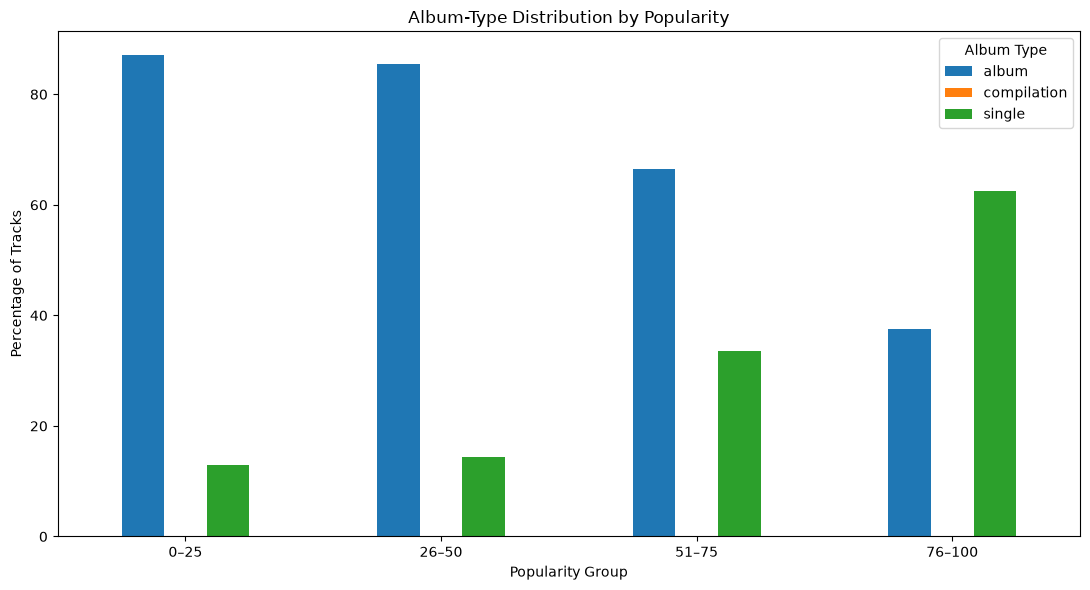

In [246]:
album_by_popularity_pct.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Album-Type Distribution by Popularity")
plt.xlabel("Popularity Group")
plt.ylabel("Percentage of Tracks")
plt.xticks(rotation=0)
plt.legend(title="Album Type")
plt.tight_layout()
plt.show()

In [247]:
df_clean["duration_group"] = pd.cut(
    df_clean["duration_min"],
    bins=[0, 2, 3, 4, 5, float("inf")],
    labels=[
        "Under 2 min",
        "2–3 min",
        "3–4 min",
        "4–5 min",
        "5+ min"
    ],
    right=False
)

In [248]:
duration_group_by_popularity = (
    pd.crosstab(
        df_clean["popularity_group"],
        df_clean["duration_group"],
        normalize="index"
    ) * 100
).round(2)

duration_group_by_popularity

duration_group,Under 2 min,2–3 min,3–4 min,4–5 min,5+ min
popularity_group,,,,,
0–25,4.63,35.19,46.30,11.11,2.78
26–50,1.67,58.33,38.06,1.67,0.28
51–75,0.47,53.78,41.18,4.16,0.40
76–100,0.77,44.40,48.53,6.08,0.22


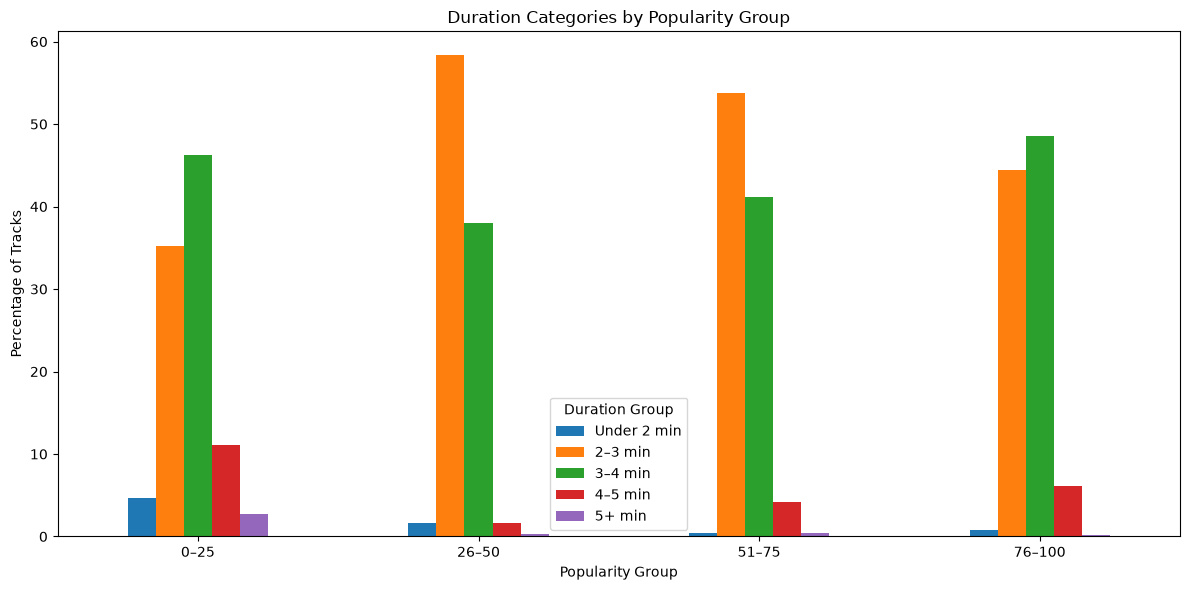

In [249]:
duration_group_by_popularity.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Duration Categories by Popularity Group")
plt.xlabel("Popularity Group")
plt.ylabel("Percentage of Tracks")
plt.xticks(rotation=0)
plt.legend(title="Duration Group")
plt.tight_layout()
plt.show()

In [250]:
popularity_format_summary = (
    df_clean
    .groupby("popularity_group", observed=True)
    .agg(
        track_count=("song", "count"),
        avg_popularity=("popularity", "mean"),
        median_popularity=("popularity", "median"),
        avg_chart_position=("position", "mean"),
        median_chart_position=("position", "median"),
        avg_duration_min=("duration_min", "mean"),
        median_duration_min=("duration_min", "median"),
        unique_artists=("artist", "nunique")
    )
    .round(2)
)

popularity_format_summary

,track_count,avg_popularity,median_popularity,avg_chart_position,median_chart_position,avg_duration_min,median_duration_min,unique_artists
popularity_group,,,,,,,,
0–25,108,5.12,0.0,25.19,24.5,3.16,3.15,42
26–50,360,42.60,44.5,28.78,30.0,2.96,2.88,70
51–75,13930,69.87,71.0,28.82,30.0,3.06,2.97,213
76–100,13383,85.18,84.0,21.97,20.0,3.13,3.05,174


In [251]:
# Album type with the highest average popularity
album_popularity_ranking = (
    df_clean
    .groupby("album_type")
    .agg(
        track_count=("song", "count"),
        avg_popularity=("popularity", "mean"),
        median_popularity=("popularity", "median"),
        avg_duration_min=("duration_min", "mean")
    )
    .sort_values("avg_popularity", ascending=False)
    .round(2)
)

album_popularity_ranking

,track_count,avg_popularity,median_popularity,avg_duration_min
album_type,,,,
single,13086,80.74,78.0,3.02
compilation,9,79.33,75.0,2.91
album,14686,72.99,73.0,3.16


In [252]:
duration_by_popularity.to_csv(
    "data/saved/duration_by_popularity.csv"
)

album_by_popularity.to_csv(
    "data/saved/album_type_by_popularity.csv"
)

album_by_popularity_pct.to_csv(
    "data/saved/album_type_by_popularity_percentage.csv"
)

duration_group_by_popularity.to_csv(
    "data/saved/duration_groups_by_popularity.csv"
)

popularity_format_summary.to_csv(
    "data/saved/format_popularity_summary.csv"
)

album_popularity_ranking.to_csv(
    "data/saved/album_popularity_ranking.csv"
)

print("Step 6.5 completed successfully.")

Step 6.5 completed successfully.


#### Combined Format-Preference Summary

In [253]:
import pandas as pd
from pathlib import Path

# Check required columns
required_columns = [
    "song",
    "artist",
    "duration_min",
    "album_type",
    "position",
    "popularity"
]

missing_columns = [
    col for col in required_columns
    if col not in df_clean.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# Create duration groups if they do not already exist
if "duration_group" not in df_clean.columns:
    df_clean["duration_group"] = pd.cut(
        df_clean["duration_min"],
        bins=[0, 2, 3, 4, 5, float("inf")],
        labels=[
            "Under 2 min",
            "2–3 min",
            "3–4 min",
            "4–5 min",
            "5+ min"
        ],
        right=False
    )

# Create chart-position groups if needed
if "chart_position_group" not in df_clean.columns:
    df_clean["chart_position_group"] = pd.cut(
        df_clean["position"],
        bins=[0, 10, 25, 50],
        labels=[
            "Top 10",
            "Positions 11-25",
            "Positions 26-50"
        ],
        include_lowest=True
    )

# Create popularity groups if needed
if "popularity_group" not in df_clean.columns:
    df_clean["popularity_group"] = pd.cut(
        df_clean["popularity"],
        bins=[-1, 25, 50, 75, 100],
        labels=["0–25", "26–50", "51–75", "76–100"],
        include_lowest=True
    )

print("Step 6.6: Data preparation completed.")
print(f"Total records: {len(df_clean)}")


Step 6.6: Data preparation completed.
Total records: 27781


In [254]:
# Overall dataset summary

format_overall_summary = pd.DataFrame({
    "Metric": [
        "Total Tracks",
        "Unique Songs",
        "Unique Artists",
        "Average Duration (minutes)",
        "Median Duration (minutes)",
        "Average Popularity",
        "Average Chart Position",
        "Number of Album Types"
    ],
    "Value": [
        len(df_clean),
        df_clean["song"].nunique(),
        df_clean["artist"].nunique(),
        round(df_clean["duration_min"].mean(), 2),
        round(df_clean["duration_min"].median(), 2),
        round(df_clean["popularity"].mean(), 2),
        round(df_clean["position"].mean(), 2),
        df_clean["album_type"].nunique()
    ]
})

display(format_overall_summary)


,Metric,Value
0,Total Tracks,27781.00
1,Unique Songs,696.00
2,Unique Artists,325.00
3,Average Duration (minutes),3.09
4,Median Duration (minutes),3.00
5,Average Popularity,76.64
6,Average Chart Position,25.50
7,Number of Album Types,3.00


In [255]:
duration_preference_summary = (
    df_clean.groupby("duration_group", observed=False)
    .agg(
        track_count=("song", "count"),
        avg_duration=("duration_min", "mean"),
        avg_popularity=("popularity", "mean"),
        avg_chart_position=("position", "mean")
    )
    .reset_index()
)

duration_preference_summary["track_percentage"] = (
    duration_preference_summary["track_count"]
    / len(df_clean) * 100
).round(2)

duration_preference_summary = (
    duration_preference_summary
    .round(2)
    .sort_values("track_count", ascending=False)
)

display(duration_preference_summary)

,duration_group,track_count,avg_duration,avg_popularity,avg_chart_position,track_percentage
1,2–3 min,13682,2.70,75.56,25.61,49.25
2,3–4 min,12418,3.39,77.71,24.89,44.70
3,4–5 min,1412,4.26,78.21,29.25,5.08
0,Under 2 min,180,1.77,76.09,27.11,0.65
4,5+ min,89,5.79,71.18,32.17,0.32


In [256]:
album_preference_summary = (
    df_clean.groupby("album_type", dropna=False)
    .agg(
        track_count=("song", "count"),
        avg_duration=("duration_min", "mean"),
        median_duration=("duration_min", "median"),
        avg_popularity=("popularity", "mean"),
        avg_chart_position=("position", "mean"),
        unique_artists=("artist", "nunique")
    )
    .reset_index()
)

album_preference_summary["track_percentage"] = (
    album_preference_summary["track_count"]
    / len(df_clean) * 100
).round(2)

album_preference_summary = (
    album_preference_summary
    .round(2)
    .sort_values("track_count", ascending=False)
)

display(album_preference_summary)

,album_type,track_count,avg_duration,median_duration,avg_popularity,avg_chart_position,unique_artists,track_percentage
0,album,14686,3.16,3.04,72.99,26.73,169,52.86
2,single,13086,3.02,2.97,80.74,24.13,200,47.10
1,compilation,9,2.91,3.28,79.33,28.67,5,0.03


In [257]:
# Format patterns by chart-position group
chart_format_summary = (
    df_clean.groupby("chart_position_group", observed=False)
    .agg(
        track_count=("song", "count"),
        avg_duration=("duration_min", "mean"),
        avg_popularity=("popularity", "mean"),
        unique_artists=("artist", "nunique")
    )
    .reset_index()
    .round(2)
)

# Most common album type in each chart-position group
chart_album_distribution = pd.crosstab(
    df_clean["chart_position_group"],
    df_clean["album_type"],
    normalize="index"
).mul(100).round(2)

# Format patterns by popularity group
popularity_format_summary = (
    df_clean.groupby("popularity_group", observed=False)
    .agg(
        track_count=("song", "count"),
        avg_duration=("duration_min", "mean"),
        median_duration=("duration_min", "median"),
        avg_chart_position=("position", "mean"),
        unique_artists=("artist", "nunique")
    )
    .reset_index()
    .round(2)
)

# Album-type distribution within each popularity group
popularity_album_distribution = pd.crosstab(
    df_clean["popularity_group"],
    df_clean["album_type"],
    normalize="index"
).mul(100).round(2)

print("FORMAT BY CHART POSITION")
display(chart_format_summary)

print("ALBUM-TYPE DISTRIBUTION BY CHART POSITION (%)")
display(chart_album_distribution)

print("FORMAT BY POPULARITY")
display(popularity_format_summary)

print("ALBUM-TYPE DISTRIBUTION BY POPULARITY (%)")
display(popularity_album_distribution)

FORMAT BY CHART POSITION


,chart_position_group,track_count,avg_duration,avg_popularity,unique_artists
0,Top 10,5554,3.09,78.27,109
1,Positions 11-25,8334,3.08,77.76,200
2,Positions 26-50,13893,3.10,75.32,306


ALBUM-TYPE DISTRIBUTION BY CHART POSITION (%)


album_type,album,compilation,single
chart_position_group,,,
Top 10,49.26,0.00,50.74
Positions 11-25,48.82,0.05,51.13
Positions 26-50,56.73,0.04,43.24


FORMAT BY POPULARITY


,popularity_group,track_count,avg_duration,median_duration,avg_chart_position,unique_artists
0,0–25,108,3.16,3.15,25.19,42
1,26–50,360,2.96,2.88,28.78,70
2,51–75,13930,3.06,2.97,28.82,213
3,76–100,13383,3.13,3.05,21.97,174


ALBUM-TYPE DISTRIBUTION BY POPULARITY (%)


album_type,album,compilation,single
popularity_group,,,
0–25,87.04,0.00,12.96
26–50,85.56,0.00,14.44
51–75,66.46,0.04,33.50
76–100,37.56,0.03,62.42


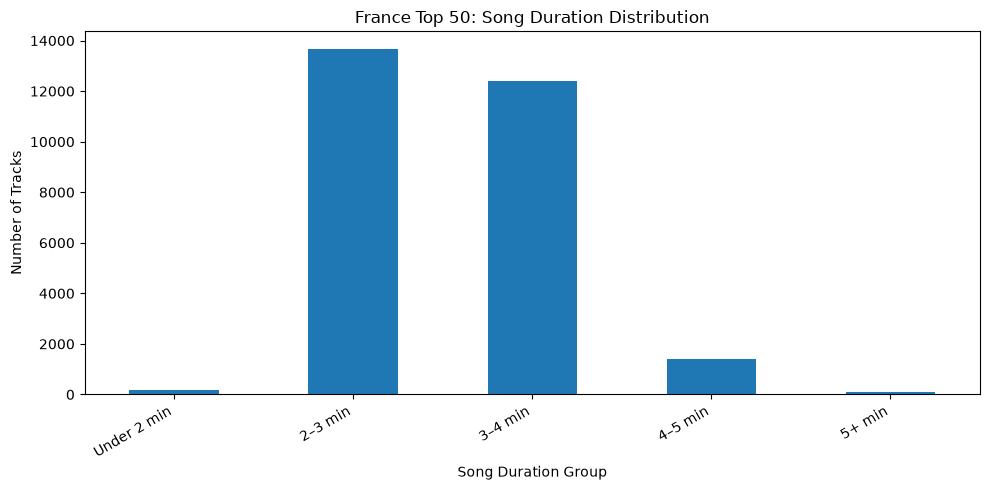

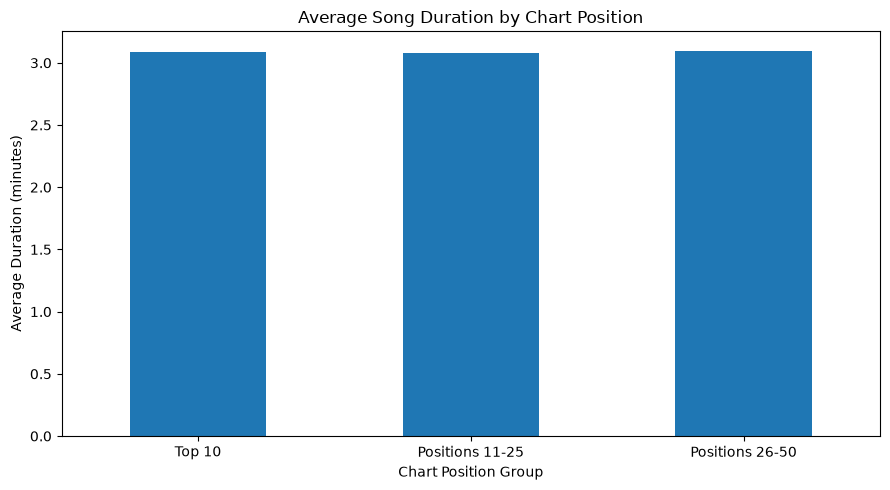

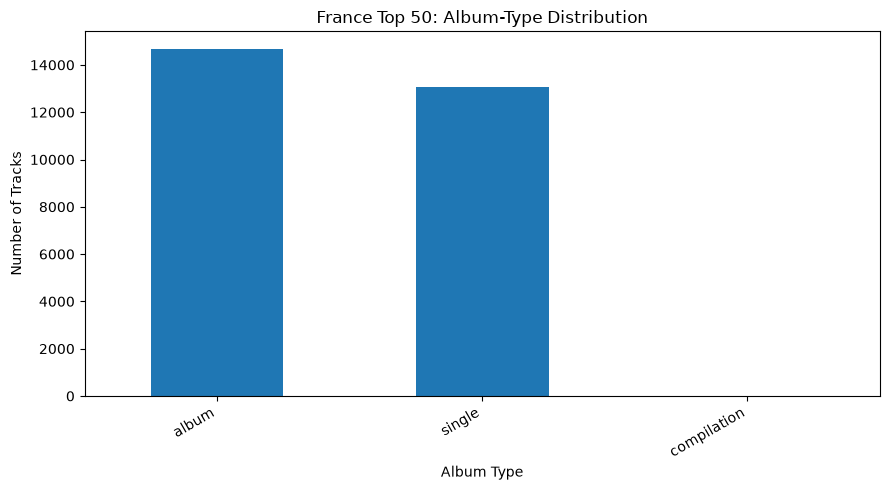

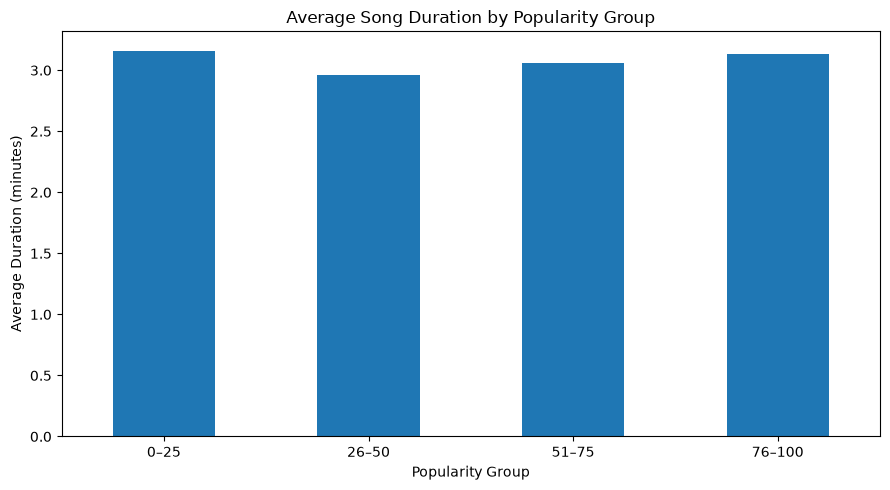

In [258]:
import matplotlib.pyplot as plt

# Chart 1: Song duration distribution
duration_counts = (
    df_clean["duration_group"]
    .value_counts(sort=False)
)

duration_counts = duration_counts[duration_counts.index.notna()]

plt.figure(figsize=(10, 5))
duration_counts.plot(kind="bar")
plt.title("France Top 50: Song Duration Distribution")
plt.xlabel("Song Duration Group")
plt.ylabel("Number of Tracks")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# Chart 2: Average duration by chart position
chart_duration = (
    df_clean.groupby("chart_position_group", observed=False)["duration_min"]
    .mean()
    .dropna()
)

plt.figure(figsize=(9, 5))
chart_duration.plot(kind="bar")
plt.title("Average Song Duration by Chart Position")
plt.xlabel("Chart Position Group")
plt.ylabel("Average Duration (minutes)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Chart 3: Album-type distribution
album_counts = df_clean["album_type"].value_counts(dropna=False)

plt.figure(figsize=(9, 5))
album_counts.plot(kind="bar")
plt.title("France Top 50: Album-Type Distribution")
plt.xlabel("Album Type")
plt.ylabel("Number of Tracks")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# Chart 4: Average duration by popularity group
popularity_duration = (
    df_clean.groupby("popularity_group", observed=False)["duration_min"]
    .mean()
    .dropna()
)

plt.figure(figsize=(9, 5))
popularity_duration.plot(kind="bar")
plt.title("Average Song Duration by Popularity Group")
plt.xlabel("Popularity Group")
plt.ylabel("Average Duration (minutes)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [259]:
# Create output directory if it does not exist
output_dir = Path("data/saved")
output_dir.mkdir(parents=True, exist_ok=True)

# Export summary tables
format_overall_summary.to_csv(
    output_dir / "step_6_6_overall_format_summary.csv",
    index=False
)

duration_preference_summary.to_csv(
    output_dir / "step_6_6_duration_preference_summary.csv",
    index=False
)

album_preference_summary.to_csv(
    output_dir / "step_6_6_album_preference_summary.csv",
    index=False
)

chart_format_summary.to_csv(
    output_dir / "step_6_6_chart_format_summary.csv",
    index=False
)

chart_album_distribution.to_csv(
    output_dir / "step_6_6_album_by_chart_position.csv"
)

popularity_format_summary.to_csv(
    output_dir / "step_6_6_popularity_format_summary.csv",
    index=False
)

popularity_album_distribution.to_csv(
    output_dir / "step_6_6_album_by_popularity.csv"
)

print("Step 6.6 completed.")
print(f"Summary files saved to: {output_dir.resolve()}")

Step 6.6 completed.
Summary files saved to: C:\Unified Mentor\Projects\Audience Sensitivity, Content Compliance & Format Preference Analysis of France Top 50 Playlist\data\saved


#### Conclusions and Recommendations

In [260]:
import pandas as pd
from pathlib import Path

required_columns = [
    "song", "artist", "is_explicit",
    "duration_min", "album_type",
    "position", "popularity"
]

missing_columns = [
    col for col in required_columns
    if col not in df_clean.columns
]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

df_final = df_clean.copy()

# Standardize explicit-content flags for analysis
df_final["explicit_flag"] = (
    df_final["is_explicit"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({
        "true": True,
        "false": False,
        "1": True,
        "0": False,
        "yes": True,
        "no": False
    })
)

valid_explicit = df_final["explicit_flag"].notna()
explicit_data = df_final.loc[valid_explicit].copy()

total_tracks = len(df_final)
unique_songs = df_final["song"].nunique()
unique_artists = df_final["artist"].nunique()

explicit_count = int(
    (explicit_data["explicit_flag"] == True).sum()
)
non_explicit_count = int(
    (explicit_data["explicit_flag"] == False).sum()
)

explicit_pct = (
    explicit_count / len(explicit_data) * 100
    if len(explicit_data) else float("nan")
)

overall_summary = pd.DataFrame({
    "Metric": [
        "Total playlist records",
        "Unique songs",
        "Unique artists",
        "Records with a valid explicit flag",
        "Explicit tracks",
        "Non-explicit tracks",
        "Explicit tracks (%)",
        "Average song duration (minutes)",
        "Median song duration (minutes)",
        "Average popularity",
        "Average chart position"
    ],
    "Value": [
        total_tracks,
        unique_songs,
        unique_artists,
        len(explicit_data),
        explicit_count,
        non_explicit_count,
        round(explicit_pct, 2) if pd.notna(explicit_pct) else None,
        round(df_final["duration_min"].mean(), 2),
        round(df_final["duration_min"].median(), 2),
        round(df_final["popularity"].mean(), 2),
        round(df_final["position"].mean(), 2)
    ]
})

display(overall_summary)

,Metric,Value
0,Total playlist records,27781.00
1,Unique songs,696.00
2,Unique artists,325.00
3,Records with a valid explicit flag,27781.00
4,Explicit tracks,15629.00
5,Non-explicit tracks,12152.00
6,Explicit tracks (%),56.26
7,Average song duration (minutes),3.09
8,Median song duration (minutes),3.00
9,Average popularity,76.64


In [261]:
findings = []

def add_finding(label, value):
    findings.append({
        "Finding Area": label,
        "Data-Based Finding": value
    })

# 1. Explicit-content profile
if len(explicit_data) > 0:
    add_finding(
        "Explicit content",
        f"{explicit_count} of {len(explicit_data)} records "
        f"({explicit_pct:.2f}%) are flagged as explicit."
    )
else:
    add_finding(
        "Explicit content",
        "No valid explicit-content flags were available."
    )

# 2. Duration pattern
duration_data = df_final.dropna(subset=["duration_min"])

if not duration_data.empty:
    avg_duration = duration_data["duration_min"].mean()
    median_duration = duration_data["duration_min"].median()

    add_finding(
        "Song duration",
        f"Mean duration is {avg_duration:.2f} minutes; "
        f"median duration is {median_duration:.2f} minutes."
    )

# 3. Most frequent album type
album_counts = df_final["album_type"].dropna().value_counts()

if not album_counts.empty:
    add_finding(
        "Album type",
        f"{album_counts.index[0]} is the most frequent album type "
        f"({album_counts.iloc[0]} records)."
    )

# 4. Chart position
position_data = df_final.dropna(subset=["position"])

if not position_data.empty:
    add_finding(
        "Chart position",
        f"Mean chart position is "
        f"{position_data['position'].mean():.2f}. "
        "A smaller numerical position represents a higher chart rank."
    )

# 5. Popularity
popularity_data = df_final.dropna(subset=["popularity"])

if not popularity_data.empty:
    add_finding(
        "Popularity",
        f"Mean popularity score is "
        f"{popularity_data['popularity'].mean():.2f}."
    )

# 6. Explicit rate by album type
if not explicit_data.empty:
    explicit_by_album = (
        explicit_data.groupby("album_type", dropna=True)
        ["explicit_flag"]
        .agg(["mean", "count"])
        .reset_index()
    )

    explicit_by_album["explicit_pct"] = (
        explicit_by_album["mean"] * 100
    )

    eligible_album_rates = explicit_by_album[
        explicit_by_album["count"] >= 3
    ]

    if not eligible_album_rates.empty:
        highest = eligible_album_rates.loc[
            eligible_album_rates["explicit_pct"].idxmax()
        ]

        add_finding(
            "Explicit content by album type",
            f"{highest['album_type']} has the highest observed "
            f"explicit-track share among album types with at least "
            f"3 valid records ({highest['explicit_pct']:.2f}%)."
        )

# 7. Explicit vs non-explicit popularity
if not explicit_data.empty:
    explicit_comparison = (
        explicit_data.groupby("explicit_flag")
        .agg(
            track_count=("song", "count"),
            avg_popularity=("popularity", "mean"),
            avg_chart_position=("position", "mean"),
            avg_duration=("duration_min", "mean")
        )
        .reset_index()
    )

    display(explicit_comparison.round(2))

    if explicit_comparison["explicit_flag"].nunique() == 2:
        pop_values = explicit_comparison.set_index(
            "explicit_flag"
        )["avg_popularity"]

        if True in pop_values.index and False in pop_values.index:
            difference = pop_values[True] - pop_values[False]

            add_finding(
                "Popularity comparison",
                f"Mean popularity for explicit tracks is "
                f"{difference:+.2f} points compared with "
                "non-explicit tracks (explicit minus non-explicit)."
            )

key_findings = pd.DataFrame(findings)
display(key_findings)


,explicit_flag,track_count,avg_popularity,avg_chart_position,avg_duration
0,False,12152,80.90,26.16,3.04
1,True,15629,73.33,24.99,3.13


,Finding Area,Data-Based Finding
0,Explicit content,15629 of 27781 records (56.26%) are flagged as...
1,Song duration,Mean duration is 3.09 minutes; median duration...
2,Album type,album is the most frequent album type (14686 r...
3,Chart position,Mean chart position is 25.50. A smaller numeri...
4,Popularity,Mean popularity score is 76.64.
5,Explicit content by album type,album has the highest observed explicit-track ...
6,Popularity comparison,Mean popularity for explicit tracks is -7.57 p...


In [262]:
conclusion_lines = []

conclusion_lines.append(
    "FINAL PROJECT CONCLUSION"
)

conclusion_lines.append(
    f"The dataset contains {total_tracks} playlist records, "
    f"{unique_songs} unique songs, and {unique_artists} unique artists."
)

if pd.notna(explicit_pct):
    conclusion_lines.append(
        f"Among records with valid explicit-content labels, "
        f"{explicit_pct:.2f}% are flagged as explicit "
        f"and {100 - explicit_pct:.2f}% as non-explicit."
    )
else:
    conclusion_lines.append(
        "The explicit-content share could not be calculated "
        "because valid labels were unavailable."
    )

if not duration_data.empty:
    conclusion_lines.append(
        f"Average track duration is {avg_duration:.2f} minutes, "
        f"with a median of {median_duration:.2f} minutes."
    )

if not album_counts.empty:
    conclusion_lines.append(
        f"The most frequently represented album type is "
        f"{album_counts.index[0]}, with {album_counts.iloc[0]} records."
    )

if not popularity_data.empty:
    conclusion_lines.append(
        f"The average popularity score is "
        f"{popularity_data['popularity'].mean():.2f}."
    )

conclusion_lines.extend([
    "",
    "RECOMMENDATIONS",
    "1. Monitor explicit and non-explicit content as separate segments.",
    "2. Validate content metadata against relevant platform policies.",
    "3. Compare duration and album-type distributions with popularity "
    "and chart position before making format decisions.",
    "4. Review artist-level patterns using sufficient observations "
    "to avoid conclusions based on very small samples.",
    "5. Repeat the analysis over time to check whether findings persist.",
    "",
    "LIMITATIONS",
    "These findings describe the supplied playlist dataset. They do not "
    "establish causation, represent every listener in France, or prove "
    "legal or platform-policy compliance. Results may depend on the "
    "dataset's collection period, coverage, and data quality."
])

final_conclusion = "\n".join(conclusion_lines)
print(final_conclusion)

FINAL PROJECT CONCLUSION
The dataset contains 27781 playlist records, 696 unique songs, and 325 unique artists.
Among records with valid explicit-content labels, 56.26% are flagged as explicit and 43.74% as non-explicit.
Average track duration is 3.09 minutes, with a median of 3.00 minutes.
The most frequently represented album type is album, with 14686 records.
The average popularity score is 76.64.

RECOMMENDATIONS
1. Monitor explicit and non-explicit content as separate segments.
2. Validate content metadata against relevant platform policies.
3. Compare duration and album-type distributions with popularity and chart position before making format decisions.
4. Review artist-level patterns using sufficient observations to avoid conclusions based on very small samples.
5. Repeat the analysis over time to check whether findings persist.

LIMITATIONS
These findings describe the supplied playlist dataset. They do not establish causation, represent every listener in France, or prove legal

In [263]:
output_dir = Path("data/saved")
output_dir.mkdir(parents=True, exist_ok=True)

# Export analytical tables
overall_summary.to_csv(
    output_dir / "step_7_overall_summary.csv",
    index=False
)

key_findings.to_csv(
    output_dir / "step_7_key_findings.csv",
    index=False
)

if not explicit_data.empty:
    explicit_comparison.to_csv(
        output_dir / "step_7_explicit_comparison.csv",
        index=False
    )

# Export the written conclusion
report_path = output_dir / "step_7_final_conclusion.txt"
report_path.write_text(final_conclusion, encoding="utf-8")

print("Step 7 outputs exported successfully.")
print(f"Output directory: {output_dir.resolve()}")
print(f"Conclusion file: {report_path.resolve()}")

Step 7 outputs exported successfully.
Output directory: C:\Unified Mentor\Projects\Audience Sensitivity, Content Compliance & Format Preference Analysis of France Top 50 Playlist\data\saved
Conclusion file: C:\Unified Mentor\Projects\Audience Sensitivity, Content Compliance & Format Preference Analysis of France Top 50 Playlist\data\saved\step_7_final_conclusion.txt
